# MML: Multimodal Data Filtering & Cleaning
![Logo MMLab](../../Assets/Figures/Logo%20MMLab.png)

### Requirements
This script uses numpy, pandas, scipy, librosa, matplotlib, tqdm and emd (Empirical Mode Decomposition). Please install them with pip before running (e.g., pip install numpy pandas scipy librosa matplotlib tqdm emd).


### CODE OVERVIEW
This script cleans each physiological and acoustic signal of the two participants (P1 and P2) and merges them, together with the 3D motion tracking data, into one time-aligned table per trial. The input is the set of trial-level files (.csv and denoised .wav) produced in the previous preprocessing steps, and the output is one filtered .csv per signal and, finally, one merged .csv per condition and trial, ready for analysis.

0. **Packages**
     The script imports essential Python libraries for file handling, signal processing (scipy, librosa, emd), and plotting.

1. **Key Variables & Functions**
     Users define the input and output folders and the keywords used to find the files (participant labels P1/P2 and the audio keyword "denoised").
     - **Core filters** Zero-phase Butterworth filters (high-, low-, or band-pass, with edge padding to avoid edge artifacts) and a notch filter for powerline noise.
     - **Signal-specific functions** One processing function for each signal (ECG, EMG, respiration, audio amplitude envelope), built from the core filters.

2. **Filtering each Modality (with Loops)**
     The script loops over all files in the input folder, matches them by participant and signal type, filters them, and saves each result as a .csv together with its LSL time.
     - **Audio**: amplitude envelope extracted from the denoised audio (400-4000 Hz band-pass, rectification, 10 Hz low-pass, normalization between 0 and 1). A pitch (F0) extraction with the YIN algorithm is also included but is no longer used (we work with the amplitude envelope instead).
     - **ECG**: high-pass (0.75 Hz) and low-pass (3 Hz) filtering. An alternative pipeline (band-pass, 50 Hz notch filter, and removal of high-frequency noise with EMD) is included in the code.
     - **Respiration**: low-pass filter at 1 Hz to retain only the breathing pattern.
     - **EMG** (biceps and triceps): 30 Hz high-pass, full-wave rectification, and 20 Hz low-pass (i.e., a smoothed muscle-activation envelope).
     !! **Filter cutoffs and the sampling rate (1000 Hz for the physiological signals) should be adjusted to your own recording setup.**

3. **Merging all Modalities per Trial**
     The filtered files are then combined into one table for each condition and trial.
     - The data of P1 and P2 are first merged within each modality (columns are suffixed _P1 and _P2) and aligned to start at time 0.
     - Motion tracking data are given LSL times by matching their frame numbers with the LSL video frame numbers (see Video Clipping). If no LSL times are found, a synthetic time vector at an assumed frame rate of 30 fps is used instead, and a warning is printed.
     - All modalities are then resampled (linear interpolation) onto one common time grid of 1000 Hz.
     - Condition (vision, movement) and trial labels are added, and the merged table is saved as one .csv file per condition and trial.

### 0. Import all necessary packages


In [67]:
import os
from os import listdir
import numpy as np
import csv #csv saving
import pandas as pd
import math #basic operations
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
import glob
import matplotlib.pyplot as plt
import tkinter # GUI toolkit to open and save files
from tkinter import filedialog, messagebox  # GUI toolkit to open and save files
from scipy.signal import butter, filtfilt, iirnotch
import librosa
import librosa.display
import tempfile
import shutil
import tqdm
from scipy.ndimage import uniform_filter1d
import emd


print("Everything imported successfully")

Everything imported successfully


#### 1. Defyining key Directories, Variables & Functions




In [68]:
input_folder = r"D:\Mobile-Multimodal-Lab\4_PROCESSED\raw_trials"
output_folder = r"D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials"
print("Input folder:", input_folder)
print("Output folder:", output_folder)  

## --- FUNCTIONS --- ##

### ------------------------------------------
### Core Filtering Functions
### ------------------------------------------

def butter_filter(data, cutoff, fs, order=4, filter_type='low'):
    """
    General-purpose Butterworth filter (low, high, or bandpass) with zero-phase filtering.
    Padding is applied to avoid edge artifacts.

    Parameters:
    - data: Signal to filter (1D array)
    - cutoff: Cutoff frequency (float for low/high, tuple for bandpass)
    - fs: Sampling rate in Hz
    - order: Filter order
    - filter_type: 'low', 'high', or 'band'

    Returns:
    - Filtered signal (same length as input)
    """
    # <chunk: filter-butterworth>
    nyquist = 0.5 * fs
    if filter_type == 'band':
        low, high = cutoff
        normal_cutoff = [low / nyquist, high / nyquist]
    else:
        normal_cutoff = cutoff / nyquist

    b, a = butter(order, normal_cutoff, btype=filter_type, analog=False)
    padded_data = np.pad(data, (1000, 1000), mode='edge')
    filtered_data = filtfilt(b, a, padded_data)
    return filtered_data[1000:-1000]
    # </chunk>

def notch_filter(signal, fs, notch_freq=50, quality_factor=30):
    """
    Notch filter to remove powerline interference at specified frequency.
    
    Parameters:
    - signal: 1D array of the signal
    - fs: Sampling rate
    - notch_freq: Frequency to notch out (e.g., 50 or 60 Hz)
    - quality_factor: Q-factor determining notch sharpness
    
    Returns:
    - Filtered signal
    """
    # <chunk: filter-notch>
    b, a = iirnotch(notch_freq / (fs / 2), quality_factor)
    return filtfilt(b, a, signal)
    # </chunk>


### ------------------------------------------
### Signal-Specific Processing Functions
### ------------------------------------------

def process_ecg(ecg_signal, fs, cutoff_high=0.5, cutoff_low=40, notch_freq=50, quality_factor=30):
    """
    Cleans ECG signal by applying high-pass, low-pass, and notch filters.
    """
    high_passed = butter_filter(ecg_signal, cutoff_high, fs, order=4, filter_type='high')
    low_passed = butter_filter(high_passed, cutoff_low, fs, order=4, filter_type='low')
    filtered = notch_filter(low_passed, fs, notch_freq, quality_factor)
    return filtered

def process_emg(emg_signal, fs, cutoff_high=20, cutoff_low=10):
    """
    Processes EMG by high-pass filtering, rectifying, then low-pass filtering.
    """
    high_passed = butter_filter(emg_signal, cutoff_high, fs, order=4, filter_type='high')
    rectified = np.abs(high_passed)
    return butter_filter(rectified, cutoff_low, fs, order=4, filter_type='low')

def process_respiration(resp_signal, fs, lowpass_cutoff=1.0):
    """
    Low-pass filters respiration signal to retain only breathing patterns.
    """
    return butter_filter(resp_signal, lowpass_cutoff, fs, order=4, filter_type='low')


### ------------------------------------------
### Audio Feature Extraction
### ------------------------------------------

def extract_pitch_yin(audio, sr, fmin=50, fmax=400, frame_length=2048, hop_length=512, trough_threshold=0.1):
    """
    Extracts pitch (F0) from audio using librosa's YIN algorithm.
    Returns both pitch values and time vector.
    """
    f0 = librosa.yin(audio, fmin=fmin, fmax=fmax, sr=sr,
                     frame_length=frame_length, hop_length=hop_length,
                     trough_threshold=trough_threshold)
    times = librosa.times_like(f0, sr=sr, hop_length=hop_length)
    return f0, times

def amp_envelope(audiofilename):
    """
    Extracts amplitude envelope from audio by applying bandpass, rectification,
    lowpass filtering, and scaling to 0–1.
    """
    audio, sr = librosa.load(audiofilename, sr=None)
    # Apply bandpass filter between 400–4000 Hz
    data = butter_filter(audio, 400, sr, order=2, filter_type='high')
    data = butter_filter(data, 4000, sr, order=2, filter_type='low')
    # Rectify and smooth
    data = np.abs(data)
    data = butter_filter(data, 10, sr, order=2, filter_type='low')
    # Normalize
    return (data - np.min(data)) / (np.max(data) - np.min(data)), sr


# Empirical Mode Decomposition
def my_get_next_imf(x, zoom=None, sd_thresh=0.1):
    proto_imf = x.copy()
    continue_sift = True
    niters = 0

    if zoom is None:
        zoom = (0, x.shape[0])

    while continue_sift:
        niters += 1
        upper_env = emd.sift.interp_envelope(proto_imf, mode='upper')
        lower_env = emd.sift.interp_envelope(proto_imf, mode='lower')
        avg_env = (upper_env+lower_env) / 2
        stop, val = emd.sift.stop_imf_sd(proto_imf-avg_env, proto_imf, sd=sd_thresh)
        proto_imf = proto_imf - avg_env
        if stop:
            continue_sift = False

    return proto_imf



### ---KEYWORDS--- ###
participants = ['P1', 'P2']
audio_keyword = 'denoised'




Input folder: D:\Mobile-Multimodal-Lab\4_PROCESSED\raw_trials
Output folder: D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials


### Extracting Amplitude from the Raw Audio. 

In [ ]:
for root, dirs, files in os.walk(input_folder):  # Loop through all files in the input directory
    for file in files:                           # Loop through all files in the input directory
        for P in participants:                   # Loop through P1 and P2
            # Find the LSL csv file
            if P in file and 'Mic' in file and file.endswith(".csv"):   # Check if the file contains the keyword and is a .csv file
                print("Processing LSL file: ", os.path.basename(file))
                LSL_filename = os.path.join(root, file)
                LSL_data = pd.read_csv(LSL_filename)
                LSL_Time = LSL_data['LSL_Time']
                # Get the start and end time of the LSL
                start_time = LSL_Time.iloc[0]
                end_time = LSL_Time.iloc[-1]
                duration = end_time - start_time  # Total duration of the LSL time

            # Find the corresponding audio file
            if P in file and audio_keyword in file and file.endswith(".wav"):
                print("Processing audio file: ", os.path.basename(file))
                audio_filename = os.path.join(root, file)
                
                # Extract amplitude envelope using the predefined function
                print("Extracting amplitude envelope...")
                envelope_normalized, sr = amp_envelope(audio_filename)
                print("The sample rate of the audio file is: ", sr)

                # Generate time array
                times = np.linspace(0, len(envelope_normalized) / sr, len(envelope_normalized))

                # Save the amplitude envelope to data frame
                envelope_df = pd.DataFrame({
                    'Time': times,
                    'Amplitude_Envelope': envelope_normalized
                })

                # Create the output CSV file
                filename_base = os.path.basename(file)
                parts = filename_base.split('_')
                new_name = '_'.join(parts[:7]).replace('Mic', 'AudioEnvelope')
                output_filename = os.path.join(output_folder, new_name + '.csv')
                envelope_df.to_csv(output_filename, index=False)
                print("Amplitude envelope data saved to: ", output_filename)

                ## PLOTTING ##
                audio_data, _ = librosa.load(audio_filename, sr=sr)
                plt.figure(figsize=(12, 8))
                plt.subplot(2, 1, 1)
                plt.plot(np.linspace(0, len(audio_data) / sr, len(audio_data)), audio_data, label='Raw Audio', color='gray')
                plt.title('Raw Audio Signal')

                plt.subplot(2, 1, 2)
                plt.plot(times, envelope_normalized, label='Amplitude Envelope', color='blue')
                plt.title('Amplitude Envelope')
                plt.xlabel('Time (s)')
                plt.tight_layout()
                plt.show()



### ECG Filtering with 

Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_0_StartParticipantSinging_NoVision_Movement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


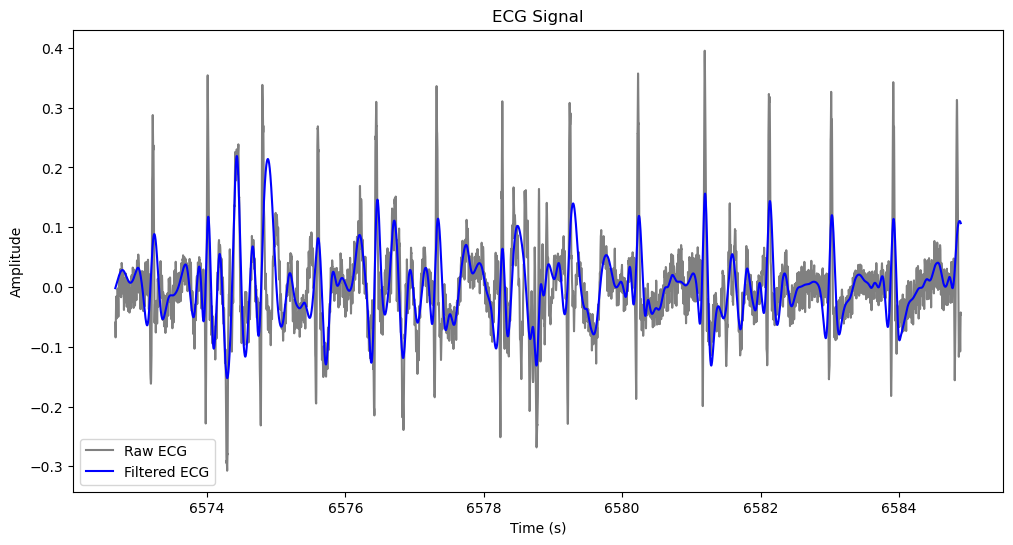

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_1_StartParticipantSinging_NoVision_Movement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


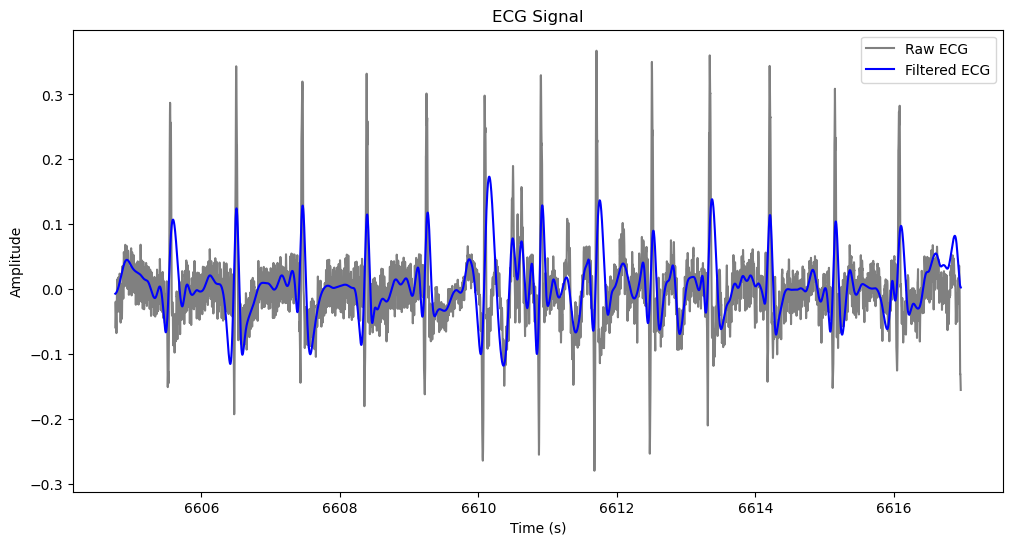

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_2_StartParticipantSinging_NoVision_Movement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


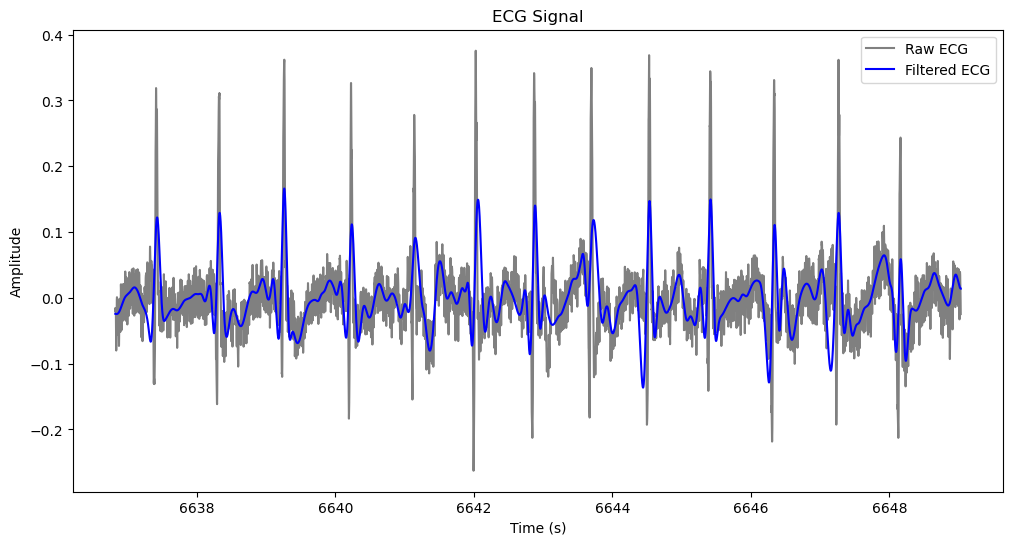

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_3_StartParticipantSinging_NoVision_Movement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


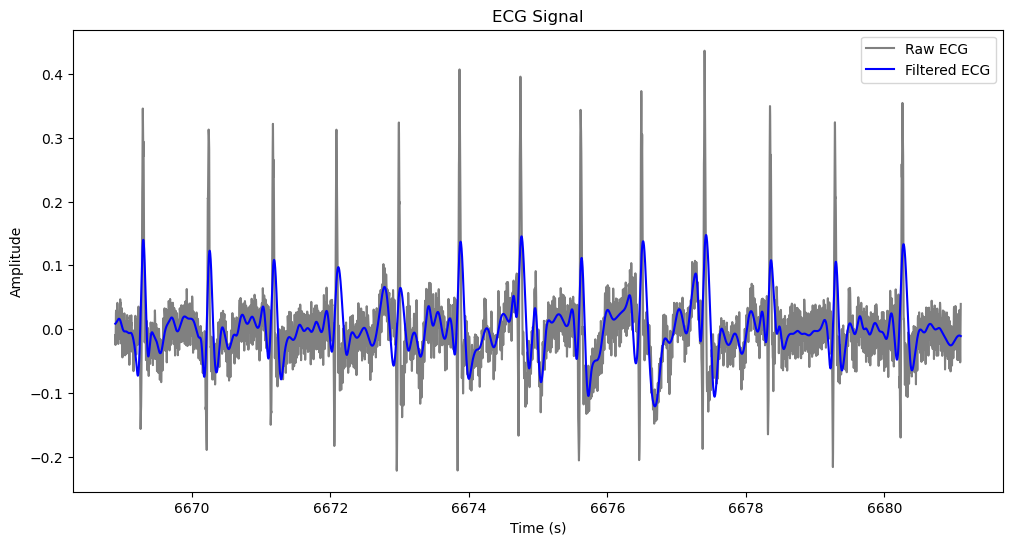

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_4_StartParticipantSinging_NoVision_Movement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


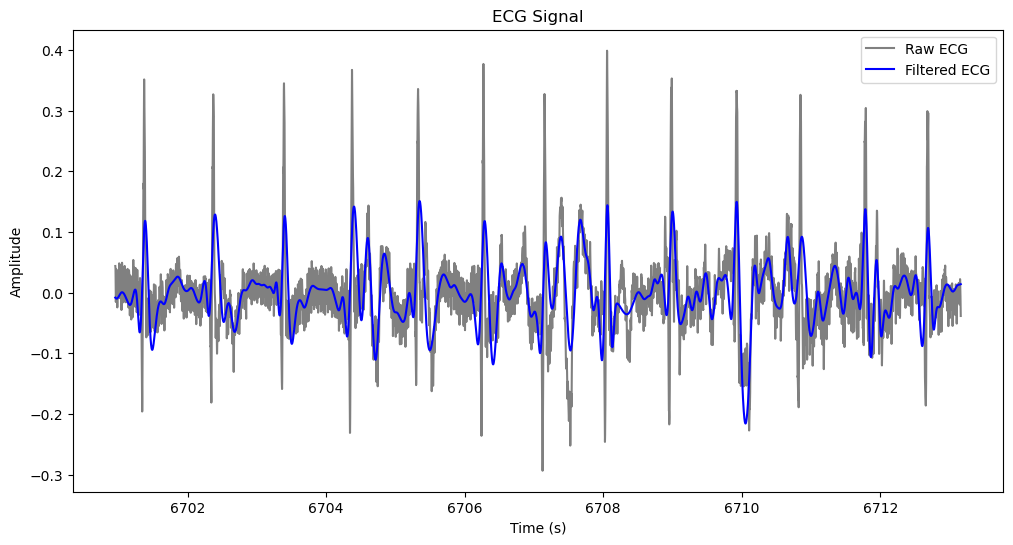

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_0_StartParticipantSinging_NoVision_NoMovement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


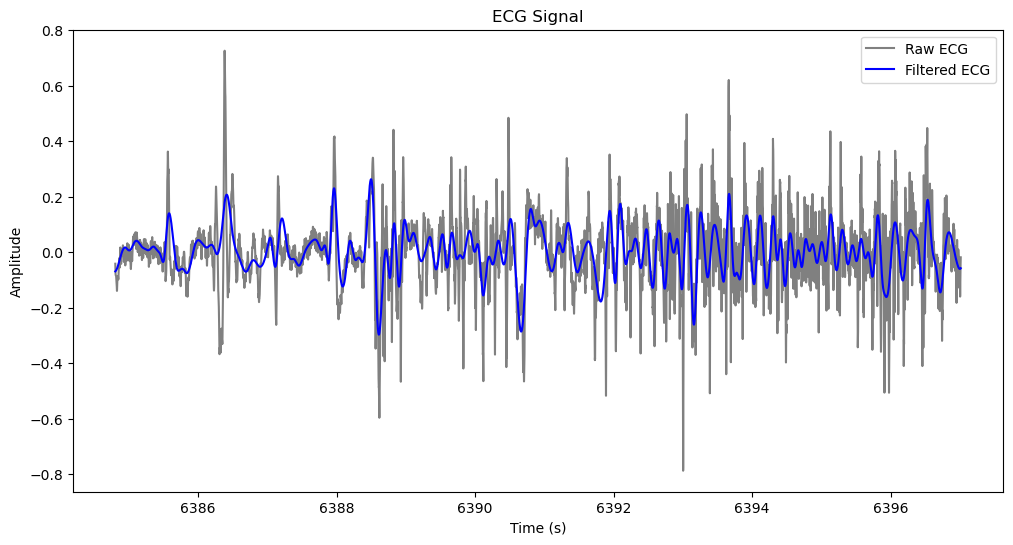

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_1_StartParticipantSinging_NoVision_NoMovement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


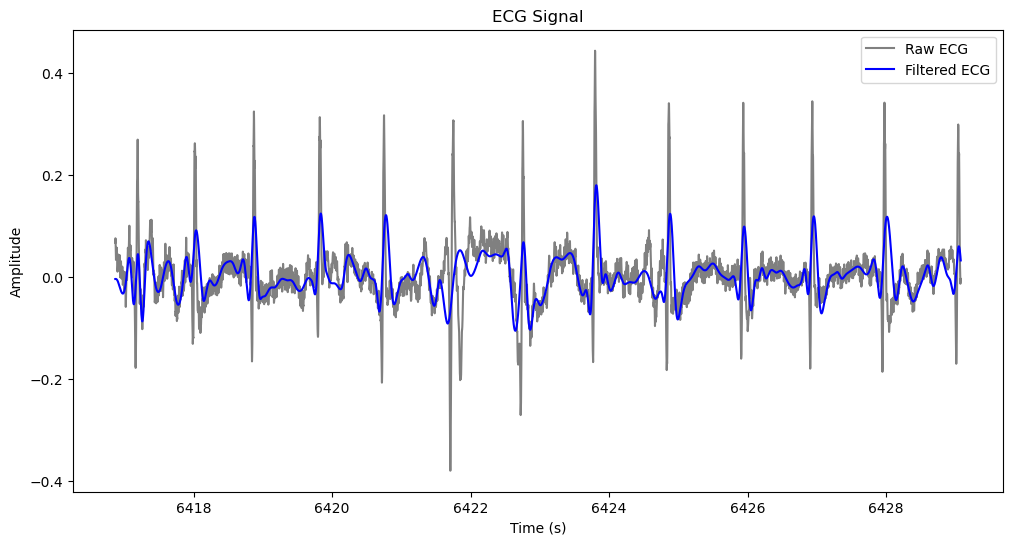

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_2_StartParticipantSinging_NoVision_NoMovement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


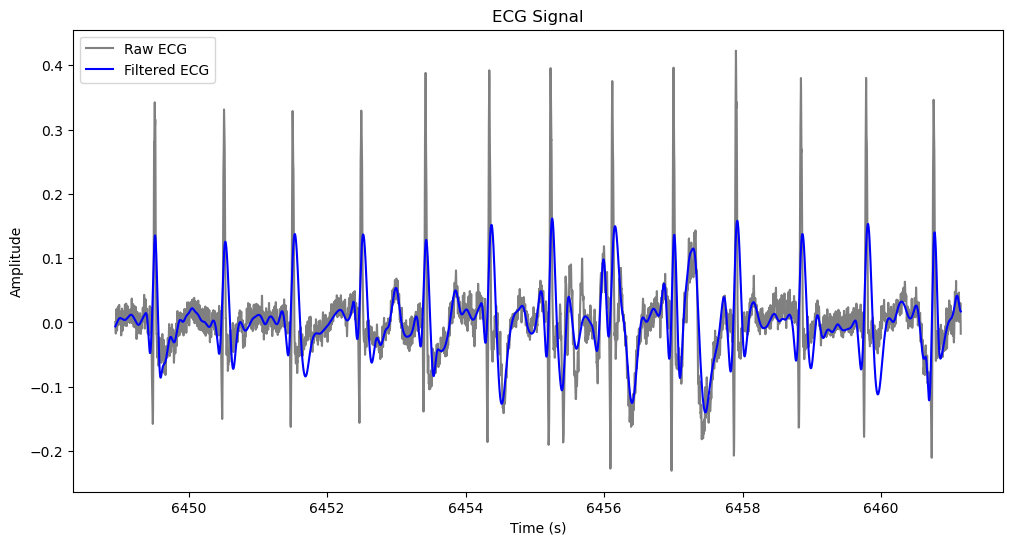

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_3_StartParticipantSinging_NoVision_NoMovement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


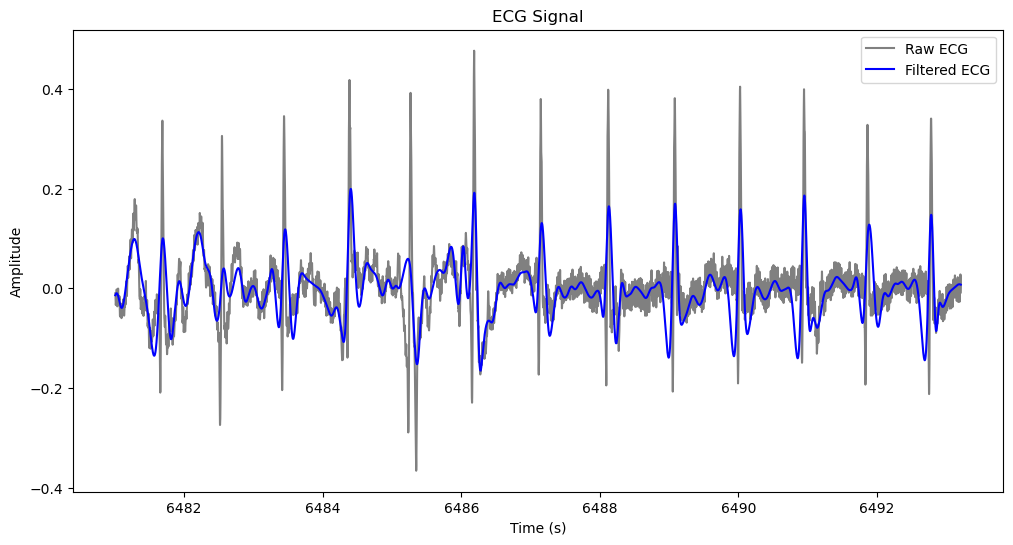

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_4_StartParticipantSinging_NoVision_NoMovement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


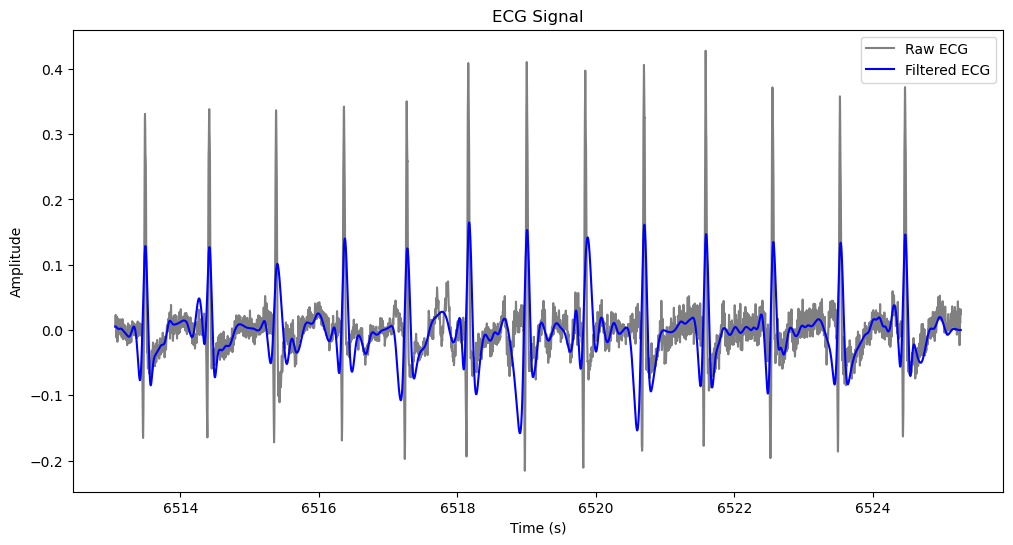

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_NoVision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_0_StartParticipantSinging_Vision_Movement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


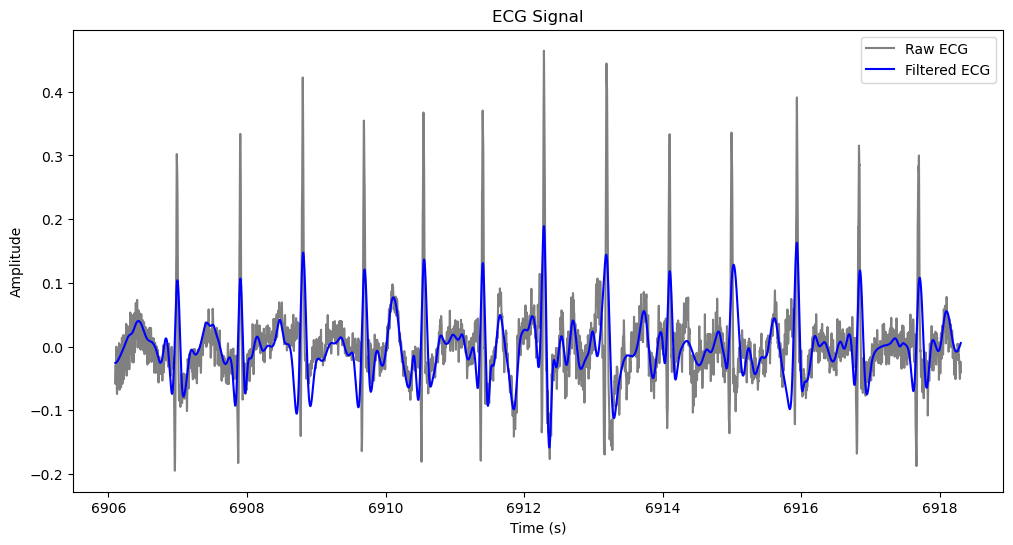

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_1_StartParticipantSinging_Vision_Movement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


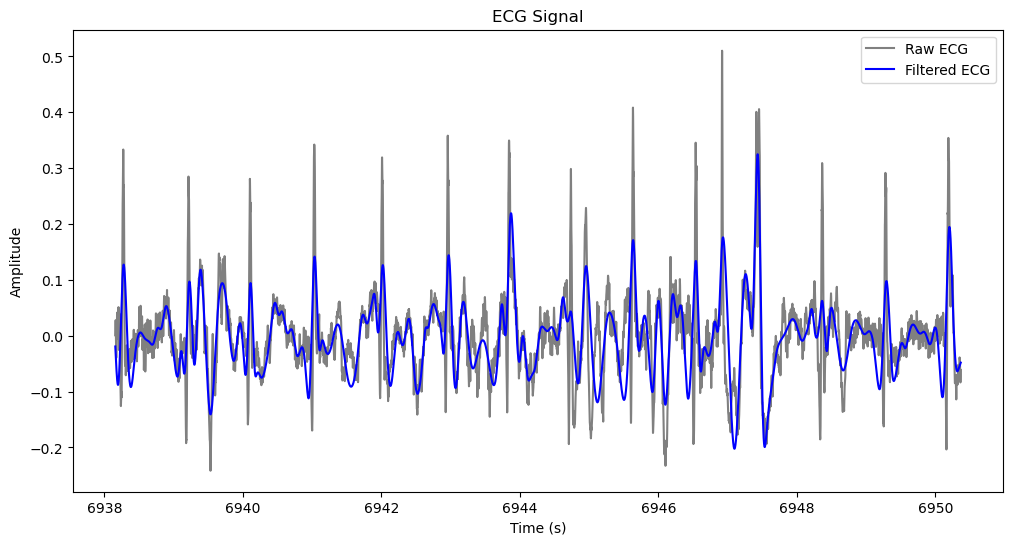

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_2_StartParticipantSinging_Vision_Movement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


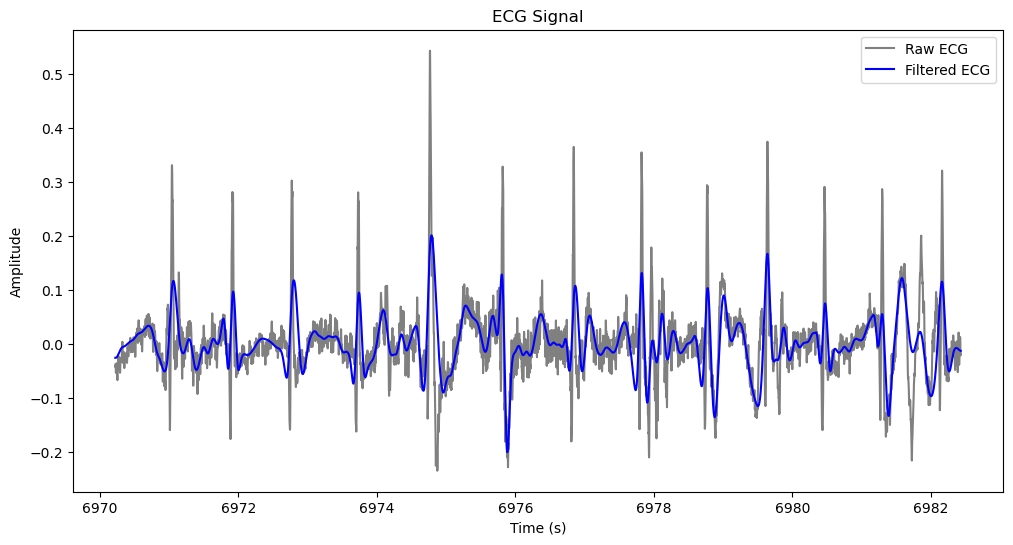

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_3_StartParticipantSinging_Vision_Movement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


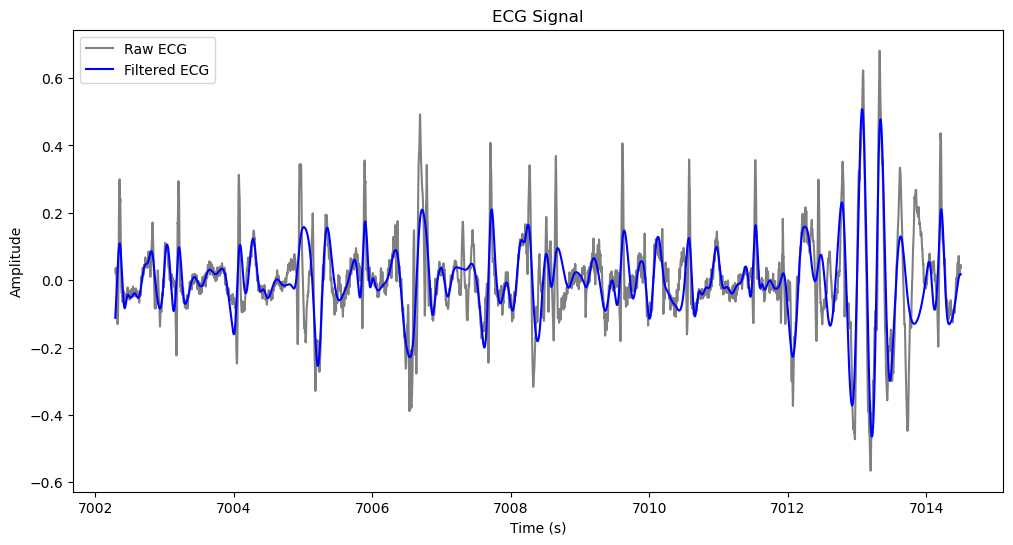

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_4_StartParticipantSinging_Vision_Movement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


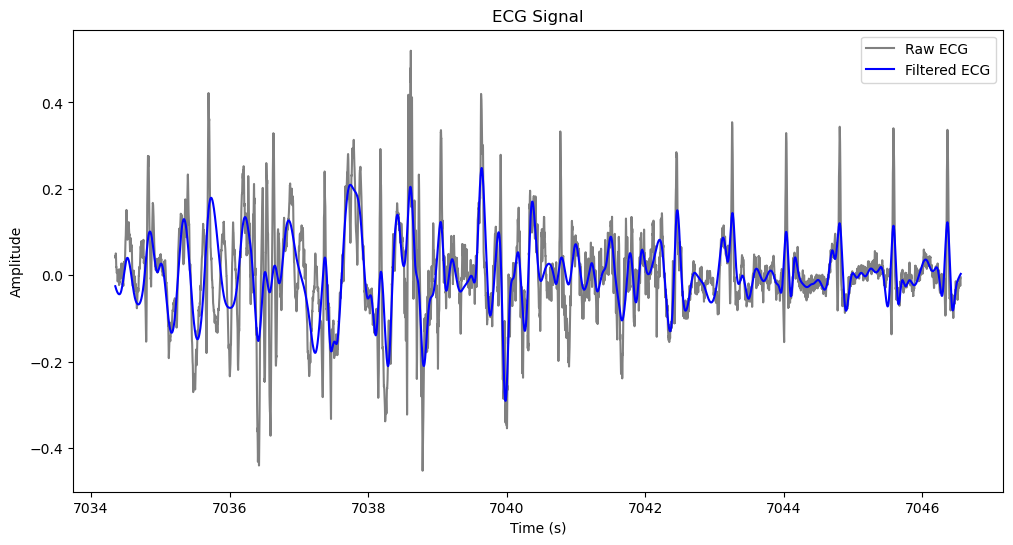

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_0_StartParticipantSinging_Vision_NoMovement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


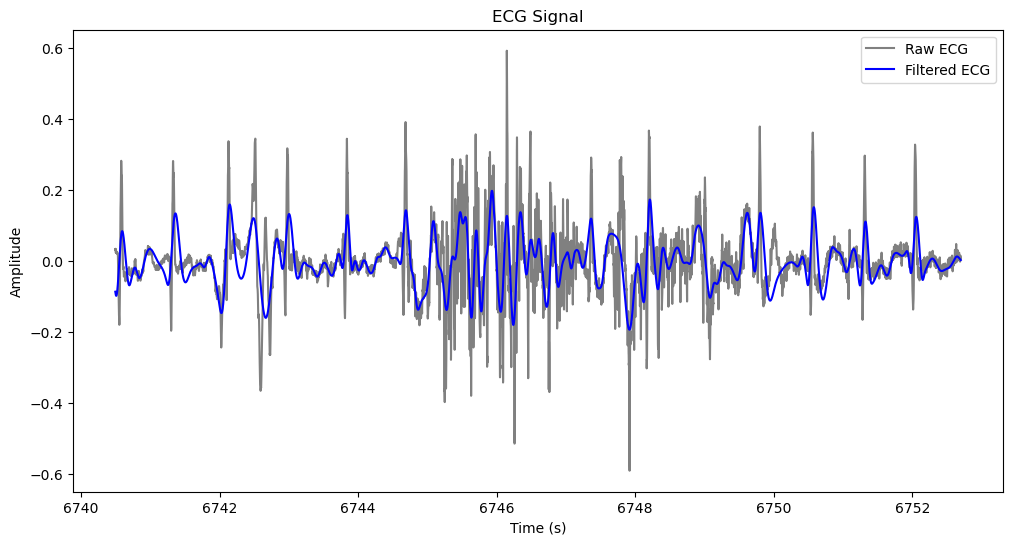

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_1_StartParticipantSinging_Vision_NoMovement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


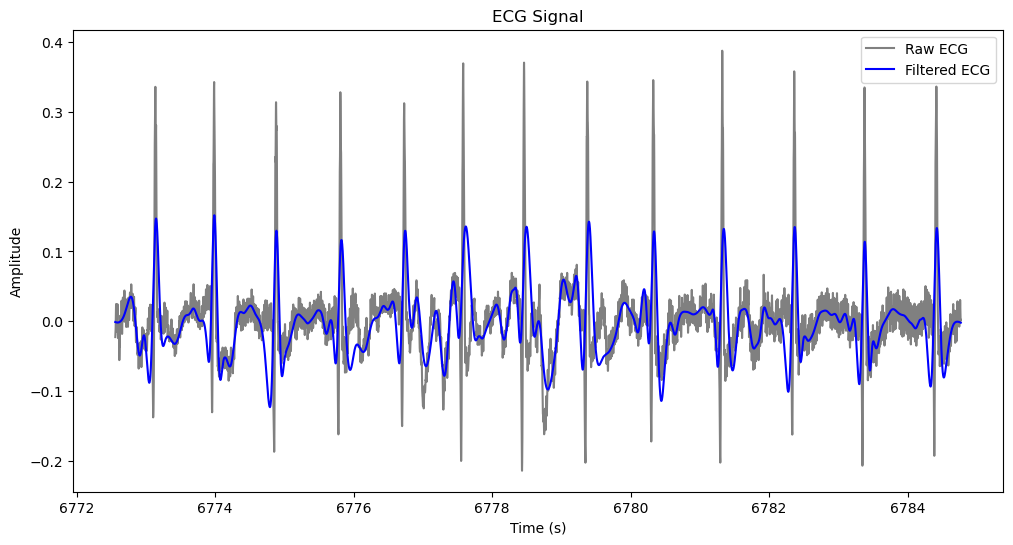

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_2_StartParticipantSinging_Vision_NoMovement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


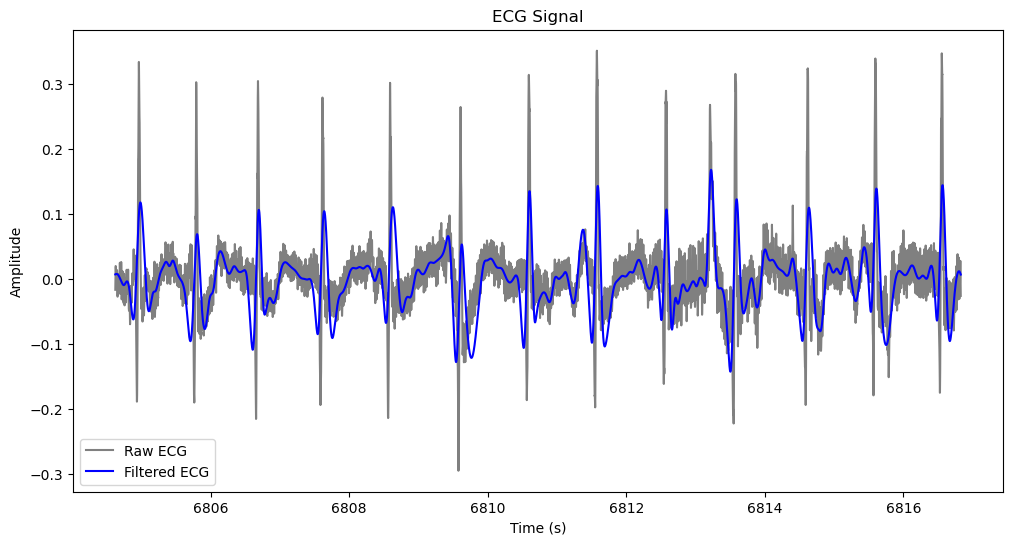

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_3_StartParticipantSinging_Vision_NoMovement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


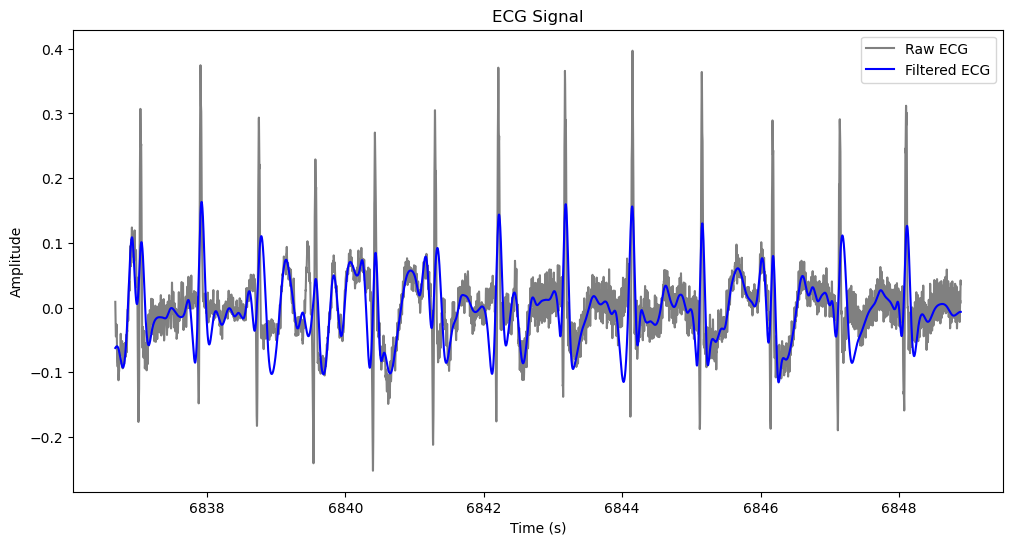

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_4_StartParticipantSinging_Vision_NoMovement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


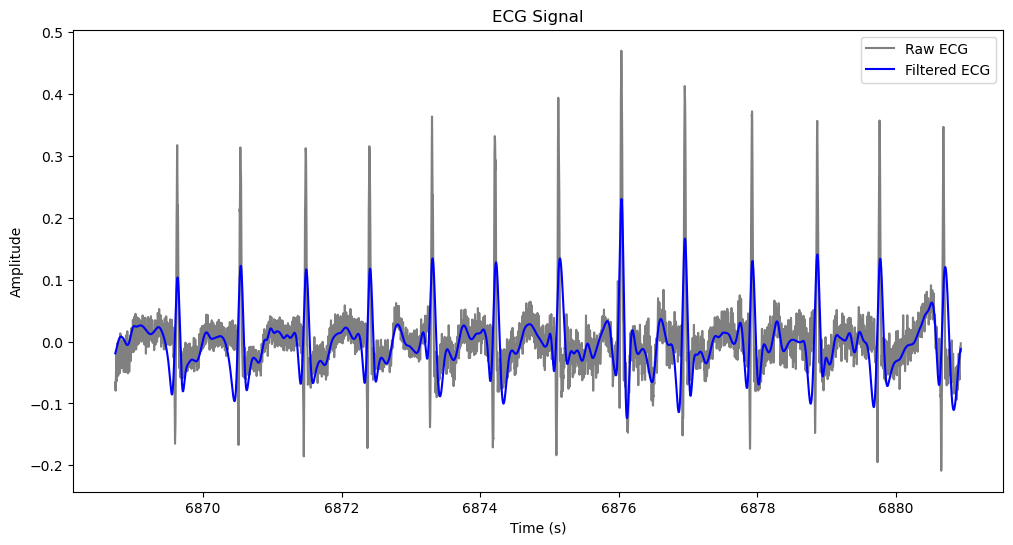

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P1_Vision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_0_StartParticipantSinging_NoVision_Movement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


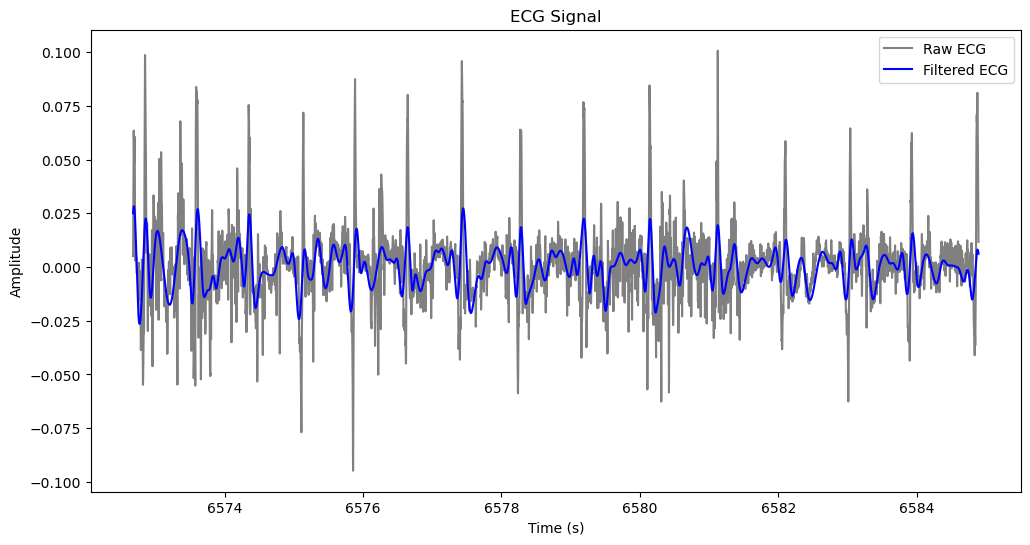

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_1_StartParticipantSinging_NoVision_Movement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


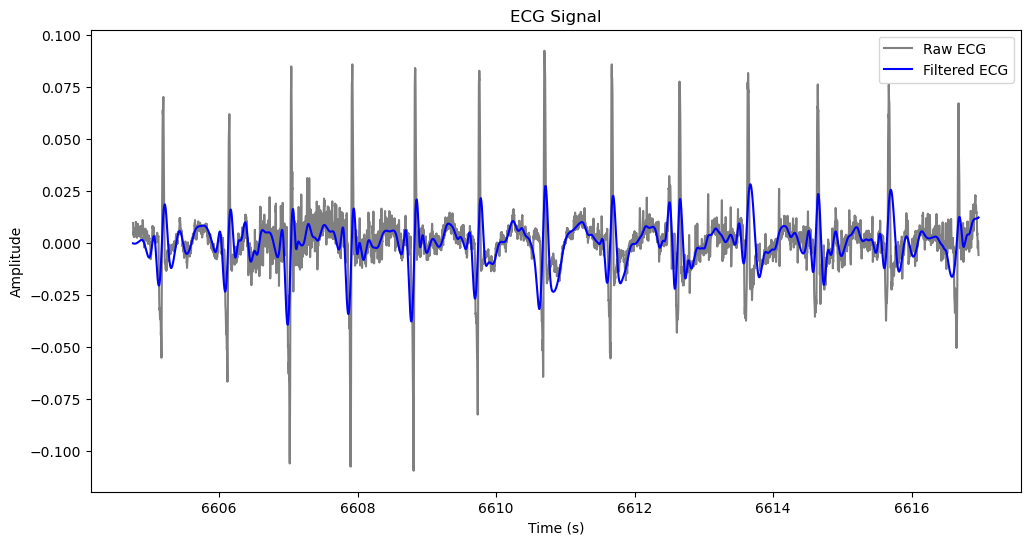

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_2_StartParticipantSinging_NoVision_Movement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


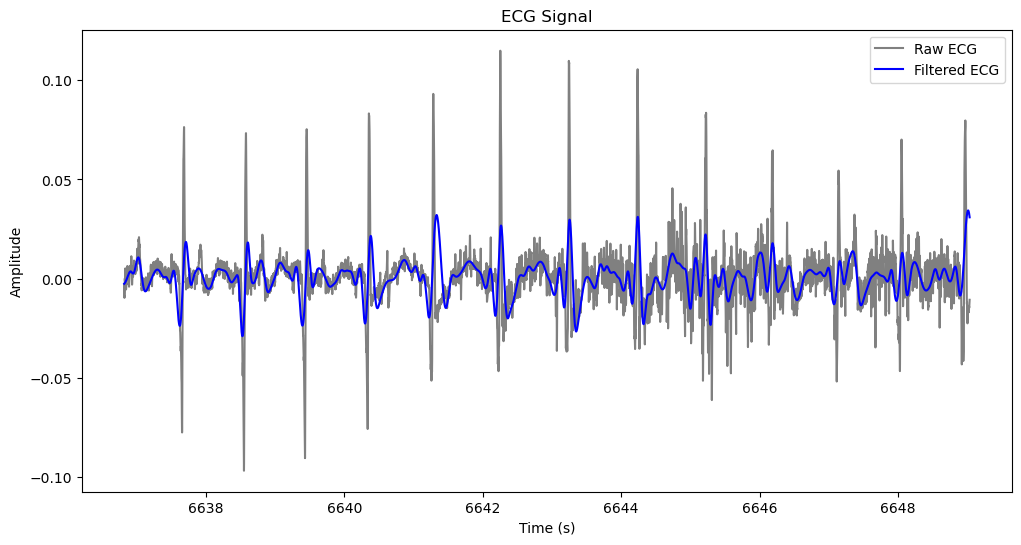

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_3_StartParticipantSinging_NoVision_Movement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


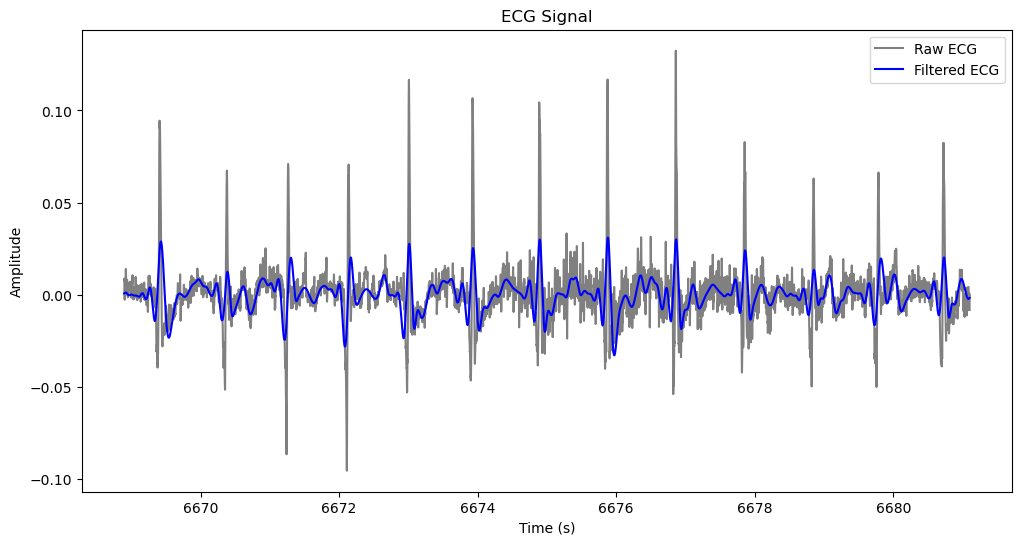

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_4_StartParticipantSinging_NoVision_Movement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


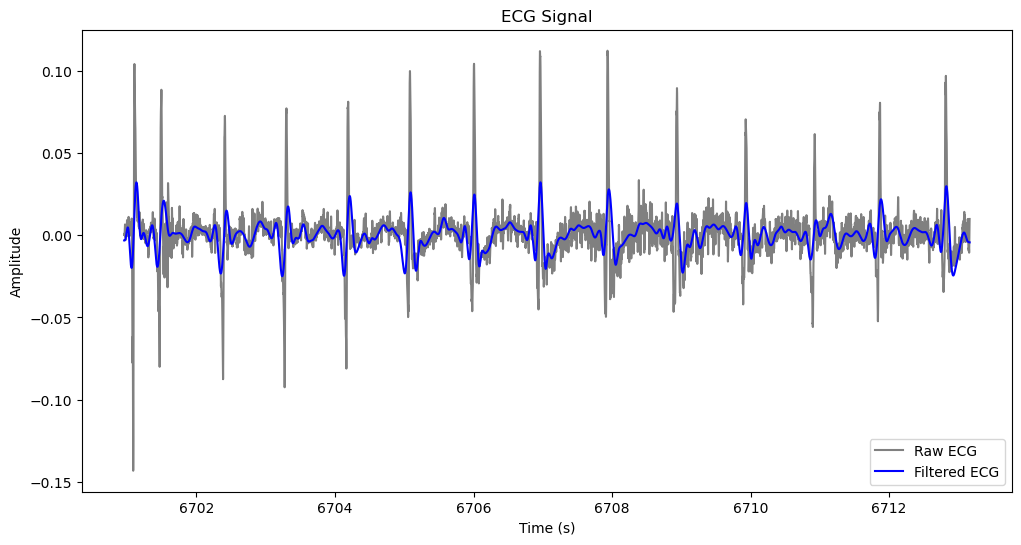

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_0_StartParticipantSinging_NoVision_NoMovement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


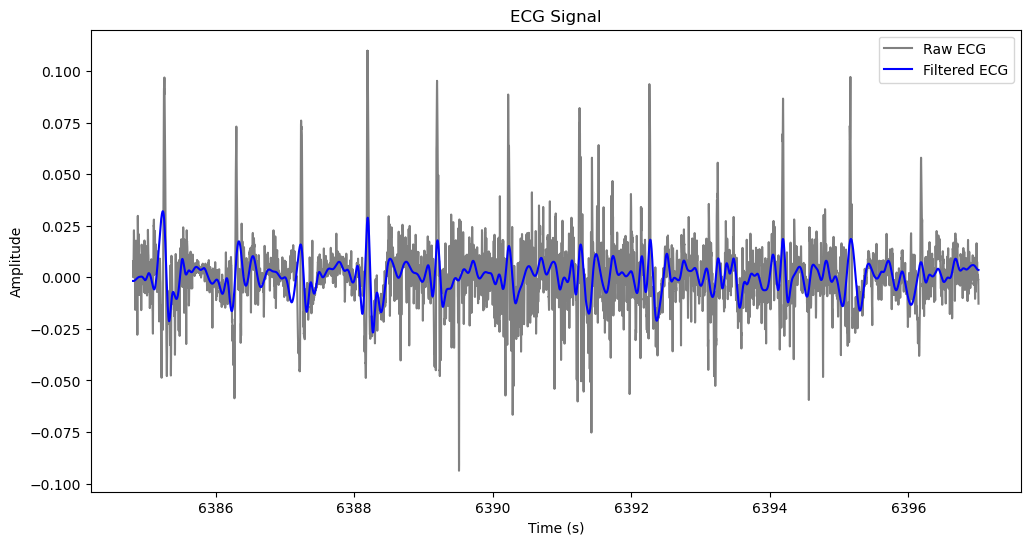

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_1_StartParticipantSinging_NoVision_NoMovement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


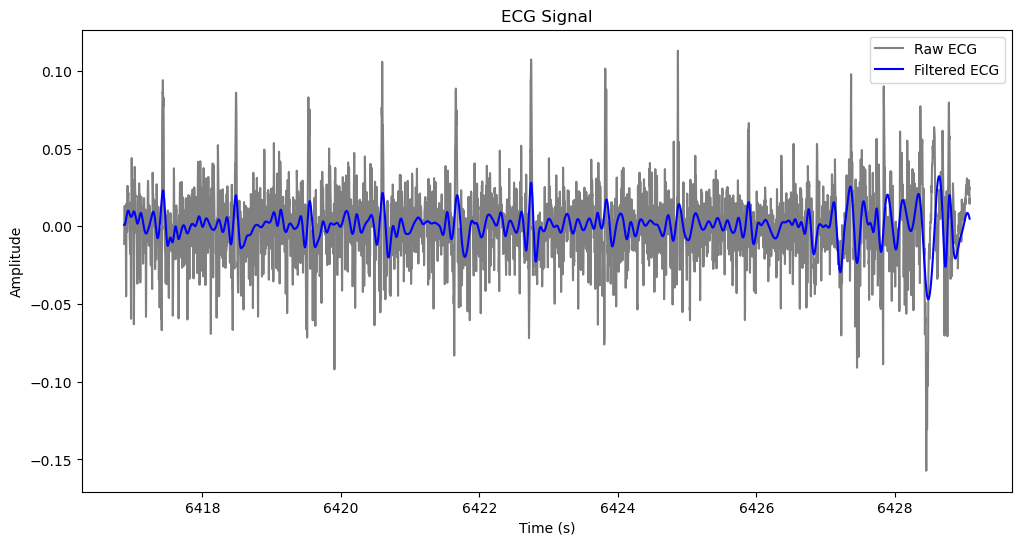

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_2_StartParticipantSinging_NoVision_NoMovement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


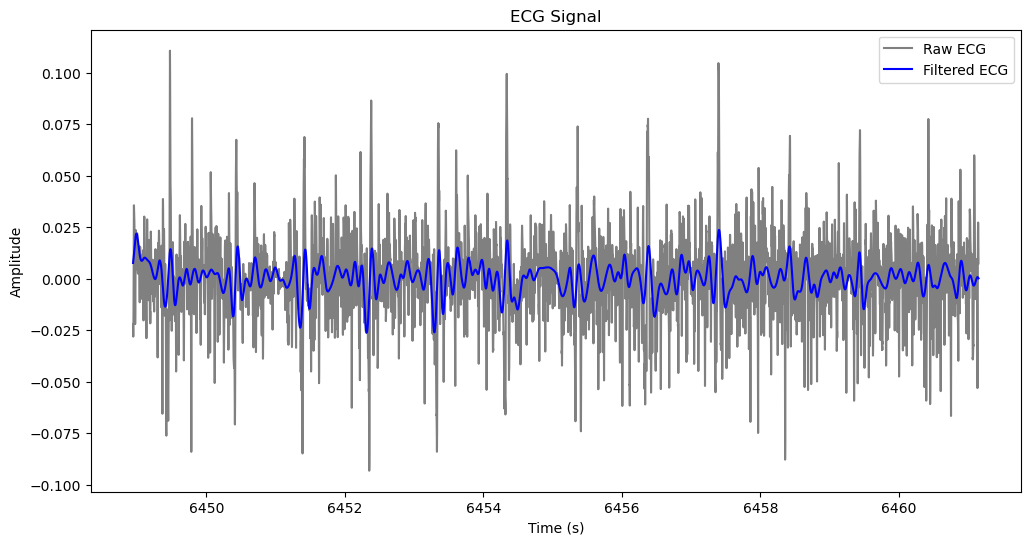

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_3_StartParticipantSinging_NoVision_NoMovement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


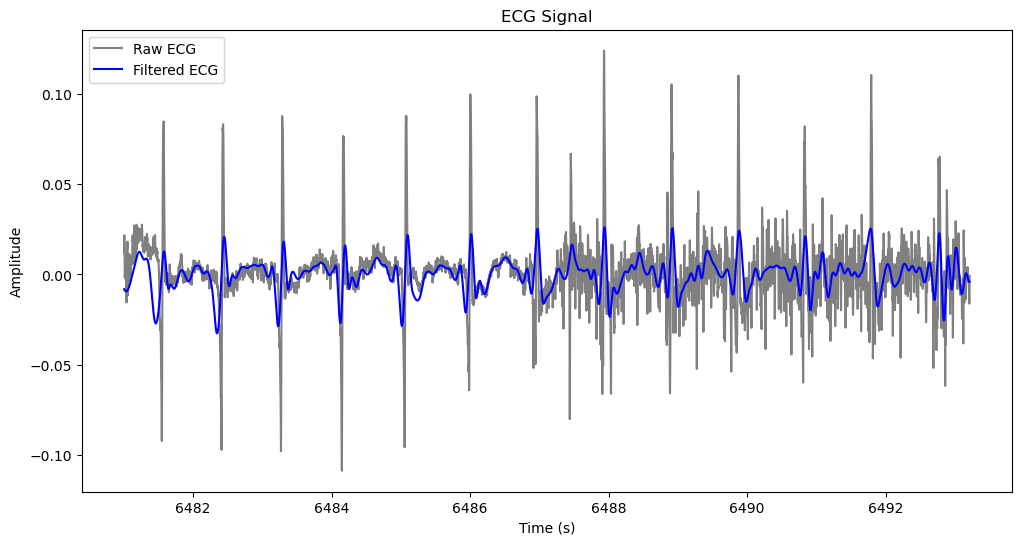

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_4_StartParticipantSinging_NoVision_NoMovement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


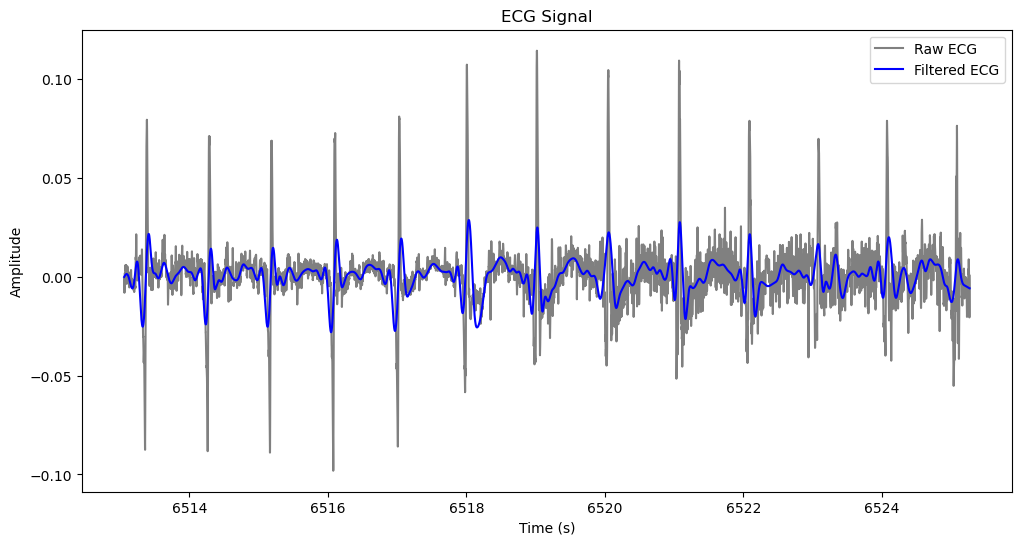

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_NoVision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_0_StartParticipantSinging_Vision_Movement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


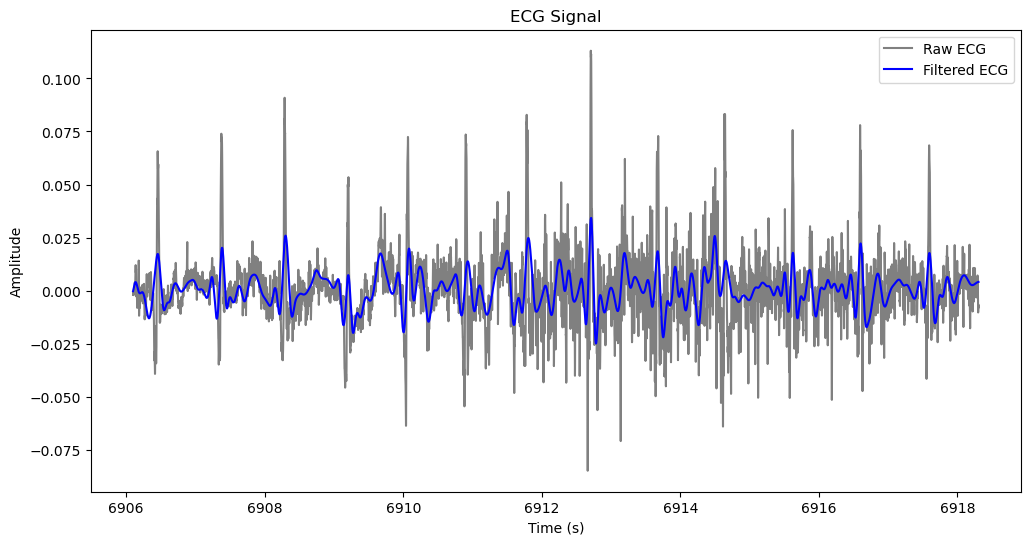

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_1_StartParticipantSinging_Vision_Movement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


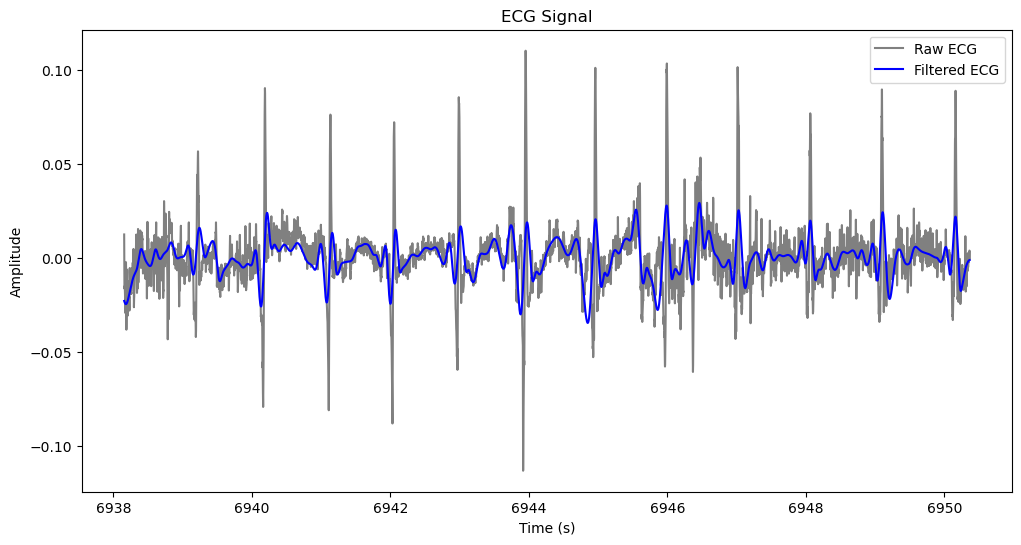

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_2_StartParticipantSinging_Vision_Movement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


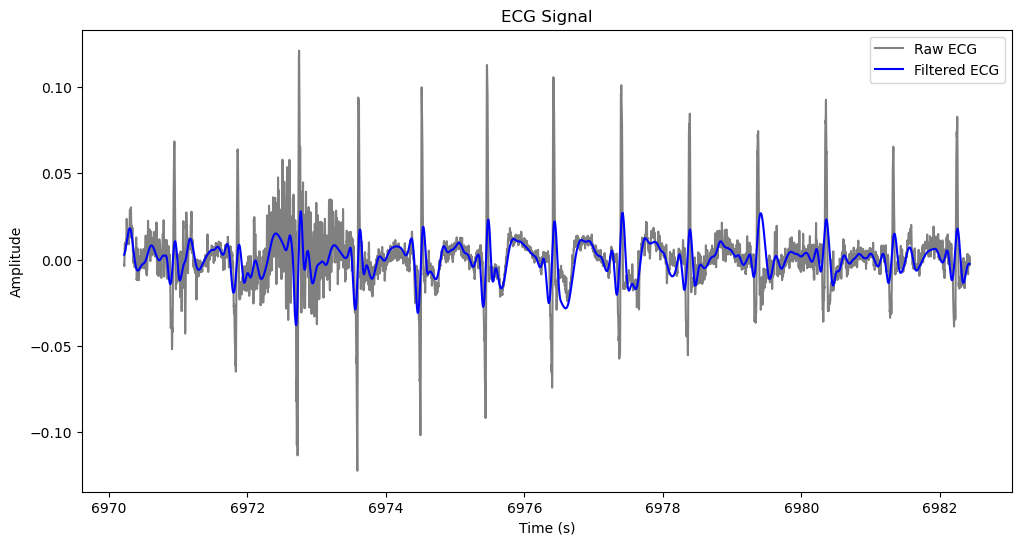

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_3_StartParticipantSinging_Vision_Movement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


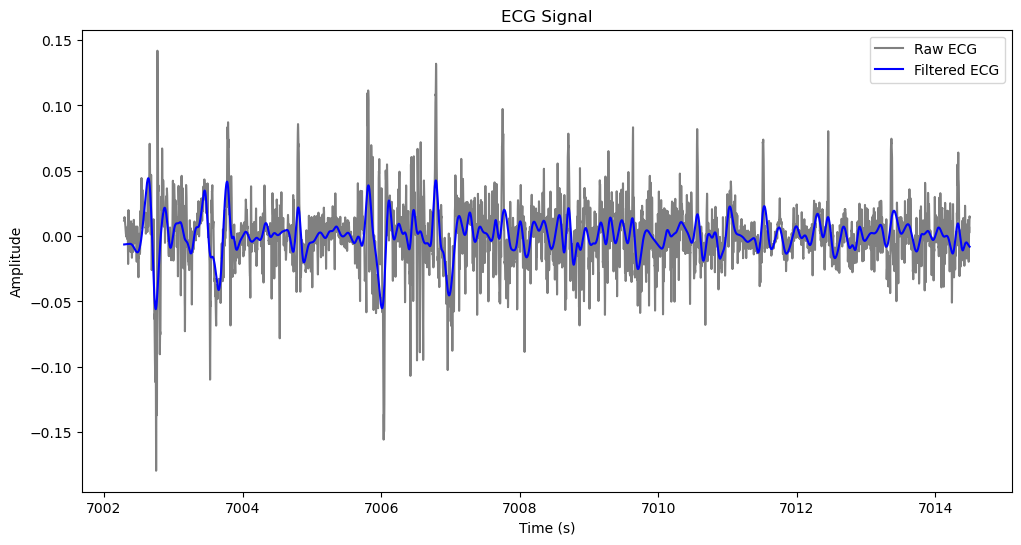

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_4_StartParticipantSinging_Vision_Movement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


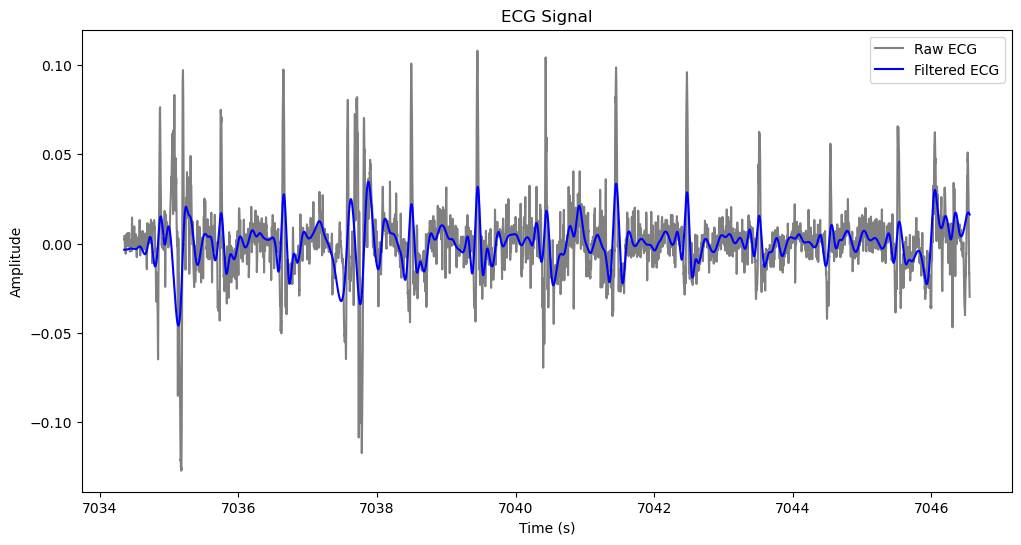

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_0_StartParticipantSinging_Vision_NoMovement_0_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


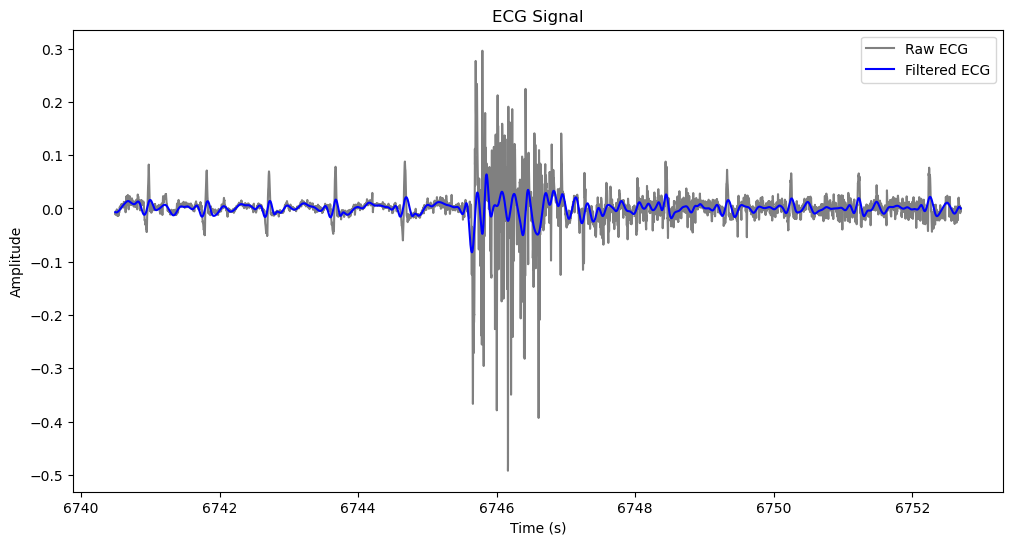

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_1_StartParticipantSinging_Vision_NoMovement_1_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


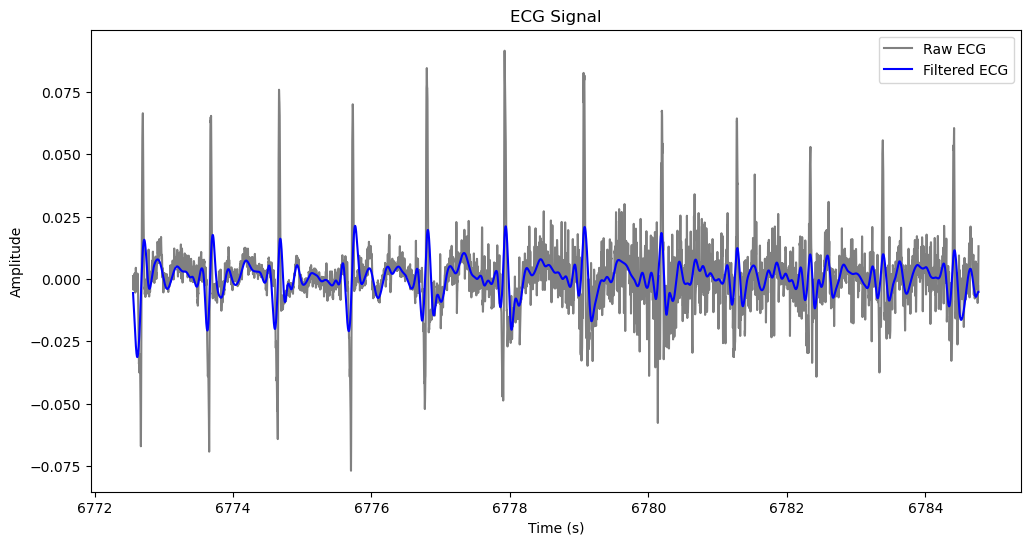

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_2_StartParticipantSinging_Vision_NoMovement_2_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


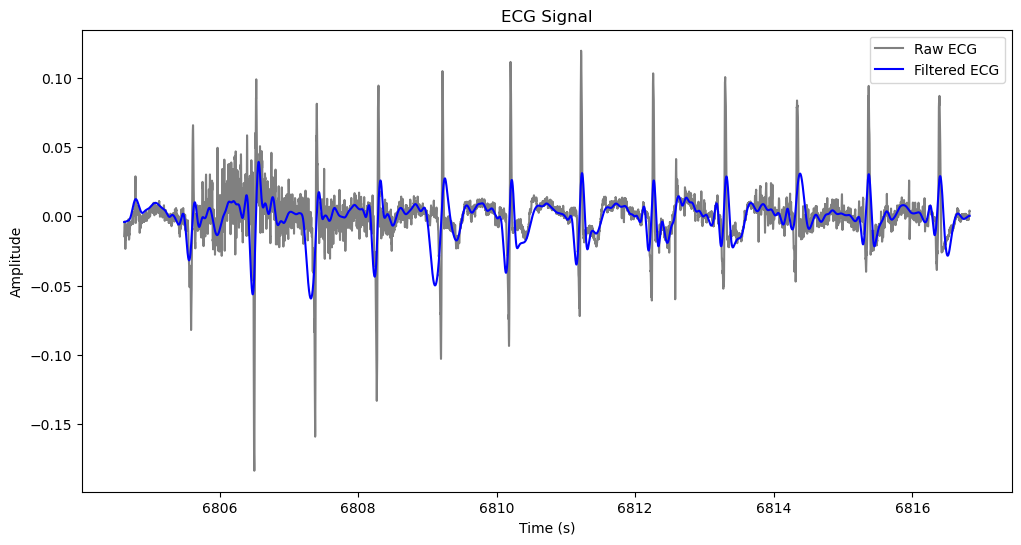

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_3_StartParticipantSinging_Vision_NoMovement_3_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


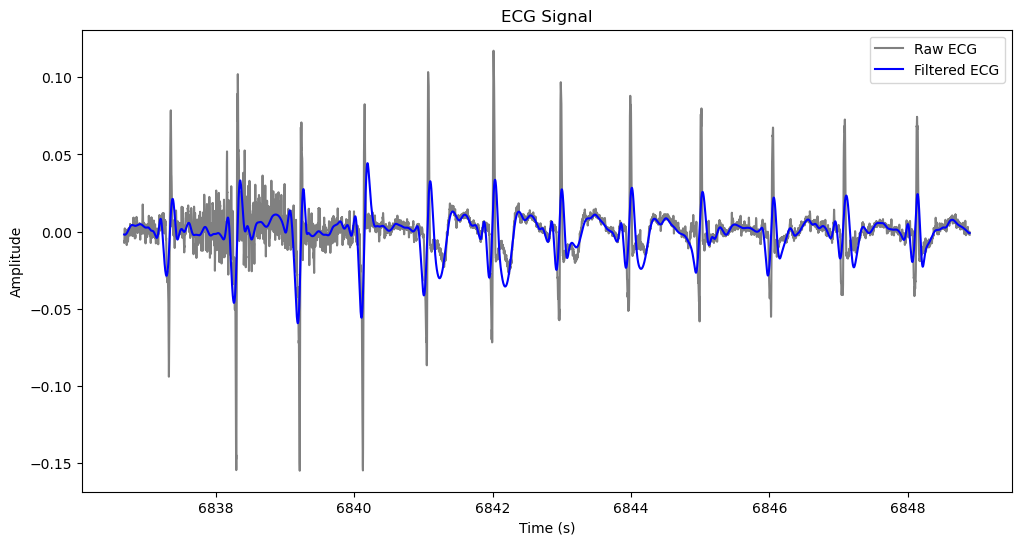

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_4_StartParticipantSinging_Vision_NoMovement_4_EndParticipantSinging.csv
the sample rate of the ECG file is:  1000


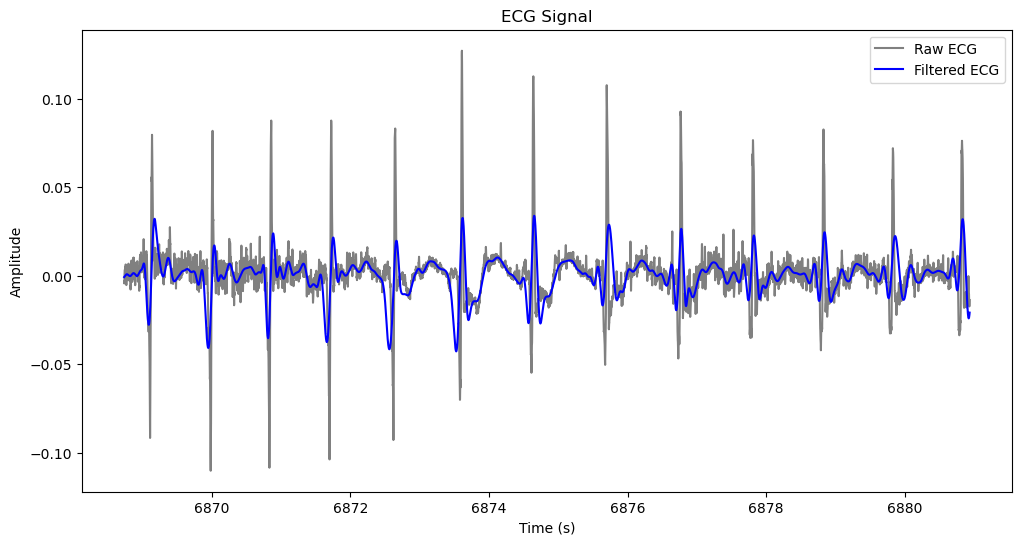

Filtered ECG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_ECG_P2_Vision_NoMovement_4.csv
All files processed successfully. You can look in the directory:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials


In [ ]:
sampling_rate = 1000 

for root, dirs, files in os.walk(input_folder):  # Loop through all files in the input directory
   
    for file in files:                                  # Loop through all files in the input directory
        
        for P in participants:                        # Loop through P1 and P2 
           
            # Find the LSL csv file 
            if P in file and 'PLUX' in file and file.endswith(".csv"):   # Check if the file contains the keyword and is a .wav file
                print("Processing LSL file: ", os.path.basename(file))

                LSL_filename = os.path.join(root, file)
                LSL_data = pd.read_csv(LSL_filename)

                LSL_Time = LSL_data['LSL_Time']

                # ECG is in the third column of the LSL data
                ECG_data = LSL_data.iloc[:, 2].values

                print("the sample rate of the ECG file is: ", sampling_rate)


                # Filter the ECG data with a high pass and low pass filter
                ECG_high_pass = butter_filter(ECG_data, 0.75, sampling_rate, order=4, filter_type='high')
                ECG_low_pass = butter_filter(ECG_high_pass, 3, sampling_rate, order=4, filter_type='low')


    #           # ALTERNATIVE WAY TO FILTER THE ECG DATA
                # Preprocess the ECG data using bandpas and notch filters
                ECG_filtered = process_ecg(ECG_data, sampling_rate, 0.5, 20, 50, 30)  # 0.5 Hz high-pass, 40 Hz low-pass, 50 Hz notch, 30 Q-factor


                # Apply EMD: extract and remove first IMF (high-freq noise)
                ECG_imf1 = my_get_next_imf(ECG_filtered, sd_thresh=0.1)

                ECG_cleaned = my_get_next_imf(ECG_filtered - ECG_imf1)

                # from scipy.signal import savgol_filter
                # window_length must be odd and > polyorder
                # ecg_smooth = savgol_filter(ECG_processed, window_length=251, polyorder=3)


                # Plot both Raw and Filtered ECG signals in the same figure
                plt.figure(figsize=(12, 6))
                plt.plot(LSL_Time, ECG_data, label='Raw ECG', color='gray')
                plt.plot(LSL_Time, ECG_cleaned, label='Filtered ECG', color='blue')
                plt.title('ECG Signal')
                plt.xlabel('Time (s)')
                plt.ylabel('Amplitude')
                plt.legend()
                plt.show()



                # # Plot the Raw and Filtered ECG signals in two subplots 
                # plt.figure(figsize=(12, 8))
                # plt.subplot(2, 1, 1)
                # plt.plot(LSL_Time, ECG_data, label='Raw ECG', color='gray')
                # plt.title('Raw ECG Signal')
                # plt.subplot(2, 1, 2)
                # plt.plot(LSL_Time, ECG_low_pass, label='Filtered ECG', color='blue')
                # plt.title('Filtered ECG Signal')
                # plt.xlabel('Time (s)')
                # plt.tight_layout()
                # plt.show()

                # Save the filtered ECG data to a CSV file 
                filename_base = os.path.basename(file)
                parts = filename_base.split('_')
                # Get the first 7 parts and join them back with underscores (i.e., until the trial number)
                new_name = '_'.join(parts[:7])
                # Replace "PLUX" with "ECG" in the base name
                new_name = new_name.replace('PLUX', 'ECG')
                # Save the filtered ECG data to a CSV file in the output folder
                output_filename = os.path.join(output_folder, new_name + '.csv')
                # Create a DataFrame with the filtered ECG data
                ECG_df = pd.DataFrame({
                    'Time': LSL_Time,
                    'Filtered_ECG': ECG_low_pass
                })
                # Save the DataFrame to a CSV file
                ECG_df.to_csv(output_filename, index=False)
                print("Filtered ECG data saved to: ", output_filename)
                

print("All files processed successfully. You can look in the directory: ", output_folder)
# Close all plots
plt.close('all')


### Respiration Cleaning

In [ ]:
sampling_rate = 1000 

for root, dirs, files in os.walk(input_folder):  # Loop through all files in the input directory
   
    for file in files:                                  # Loop through all files in the input directory
        
        for P in participants:                        # Loop through P1 and P2 
           
            # Find the LSL csv file 
            if P in file and 'PLUX' in file and file.endswith(".csv"):   # Check if the file contains the keyword and is a .wav file
                print("Processing LSL file: ", os.path.basename(file))

                LSL_filename = os.path.join(root, file)
                LSL_data = pd.read_csv(LSL_filename)

                LSL_Time = LSL_data['LSL_Time']

                # Respiration is in the 6th column of the LSL data
                Respiration_data = LSL_data.iloc[:, 5].values

                # cleanign the respiration data with a low pass filter
                Respiration_low_pass = butter_lowpass_filtfilt(Respiration_data, 1.0, 1000, order=4)

                # Plot the Raw and Filtered Respiration signals the same plot 
                plt.figure(figsize=(12, 6))
                plt.plot(LSL_Time, Respiration_data, label='Raw Respiration', color='gray')
                plt.plot(LSL_Time, Respiration_low_pass, label='Filtered Respiration', color='blue')
                plt.title('Respiration Signal')
                plt.xlabel('Time (s)')
                plt.ylabel('Amplitude')
                plt.legend()
                #plt.show()

                

                # Save the filtered Respiration data to a CSV file
                filename_base = os.path.basename(file)
                parts = filename_base.split('_')
                # Get the first 7 parts and join them back with underscores (i.e., until the trial number)
                new_name = '_'.join(parts[:7])
                # Replace "PLUX" with "Respiration" in the base name
                new_name = new_name.replace('PLUX', 'Respiration')
                # Save the filtered Respiration data to a CSV file in the output folder
                output_filename = os.path.join(output_folder, new_name + '.csv')
                # Create a DataFrame with the filtered Respiration data
                Respiration_df = pd.DataFrame({
                    'Time': LSL_Time,
                    'Filtered_Respiration': Respiration_low_pass
                })
                # Save the DataFrame to a CSV file
                Respiration_df.to_csv(output_filename, index=False)
                print("Filtered Respiration data saved to: ", output_filename)
print("All files processed successfully. You can look in the directory: ", output_folder)
                

### EMG Filtering with High Pass, Rectifier and Low Pass

Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_0_StartParticipantSinging_NoVision_Movement_0_EndParticipantSinging.csv


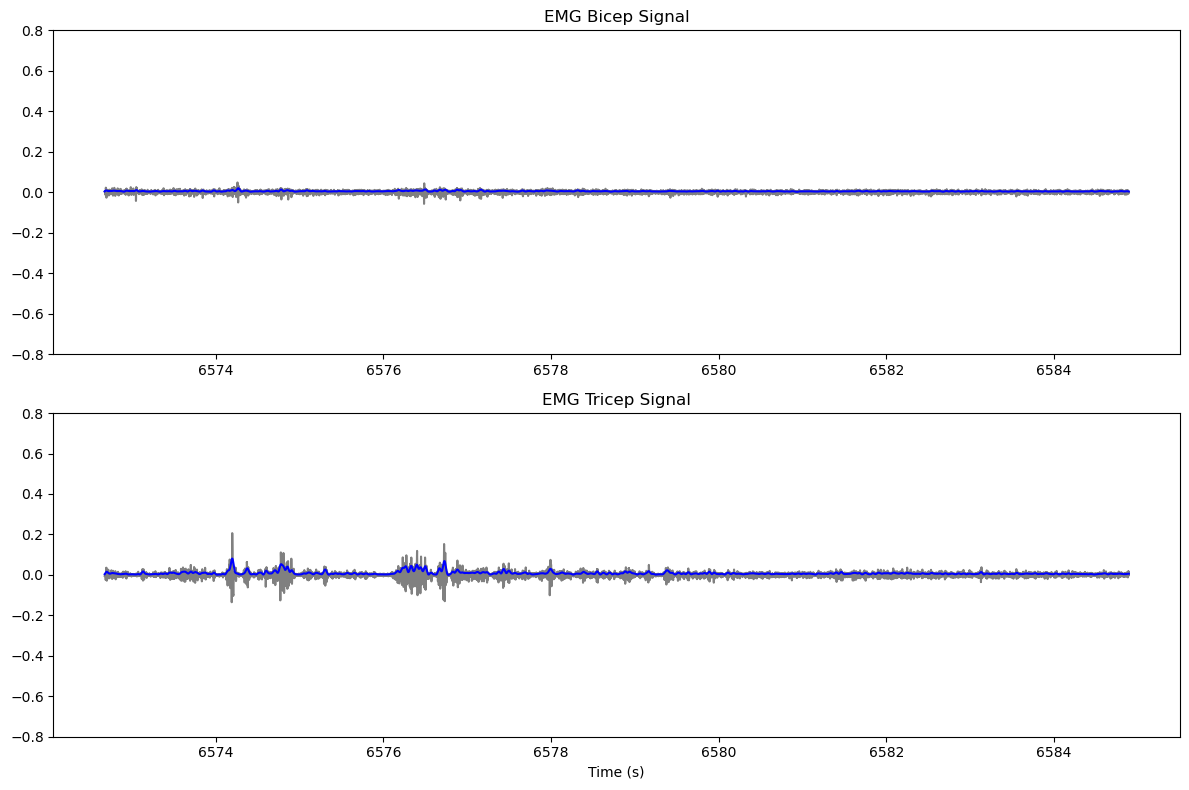

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_1_StartParticipantSinging_NoVision_Movement_1_EndParticipantSinging.csv


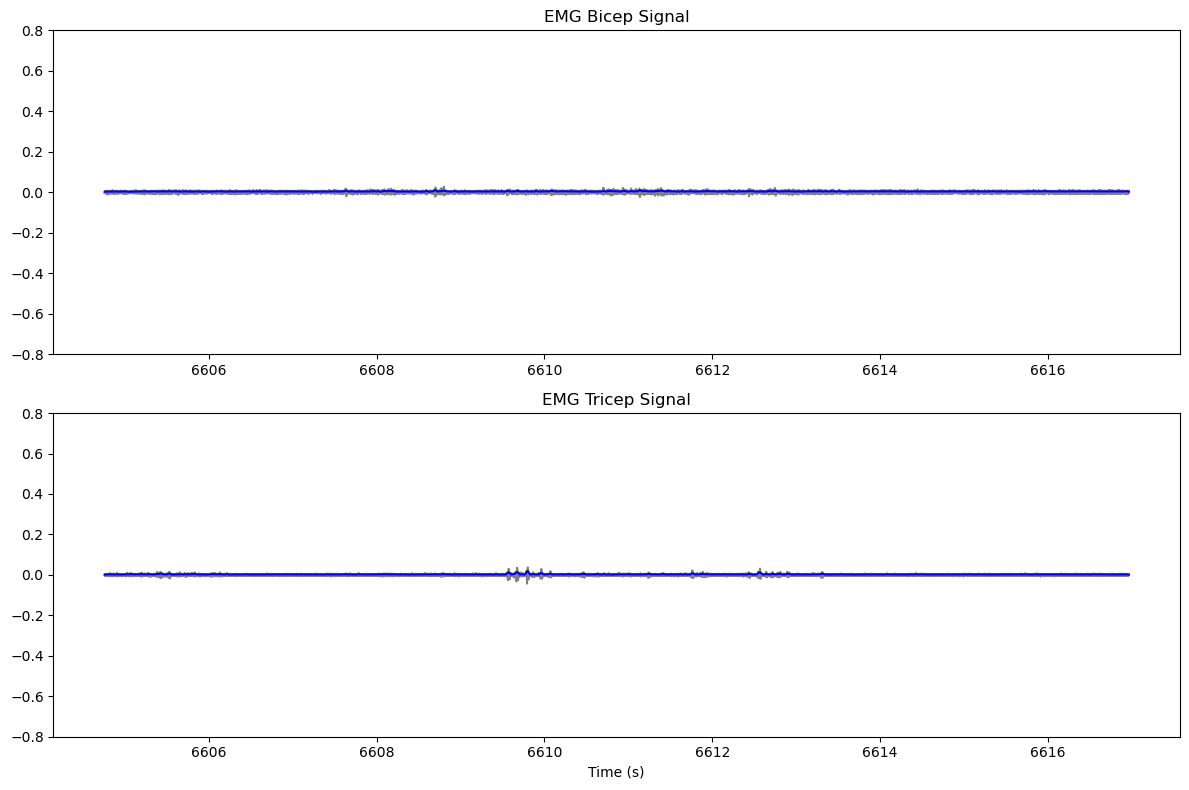

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_2_StartParticipantSinging_NoVision_Movement_2_EndParticipantSinging.csv


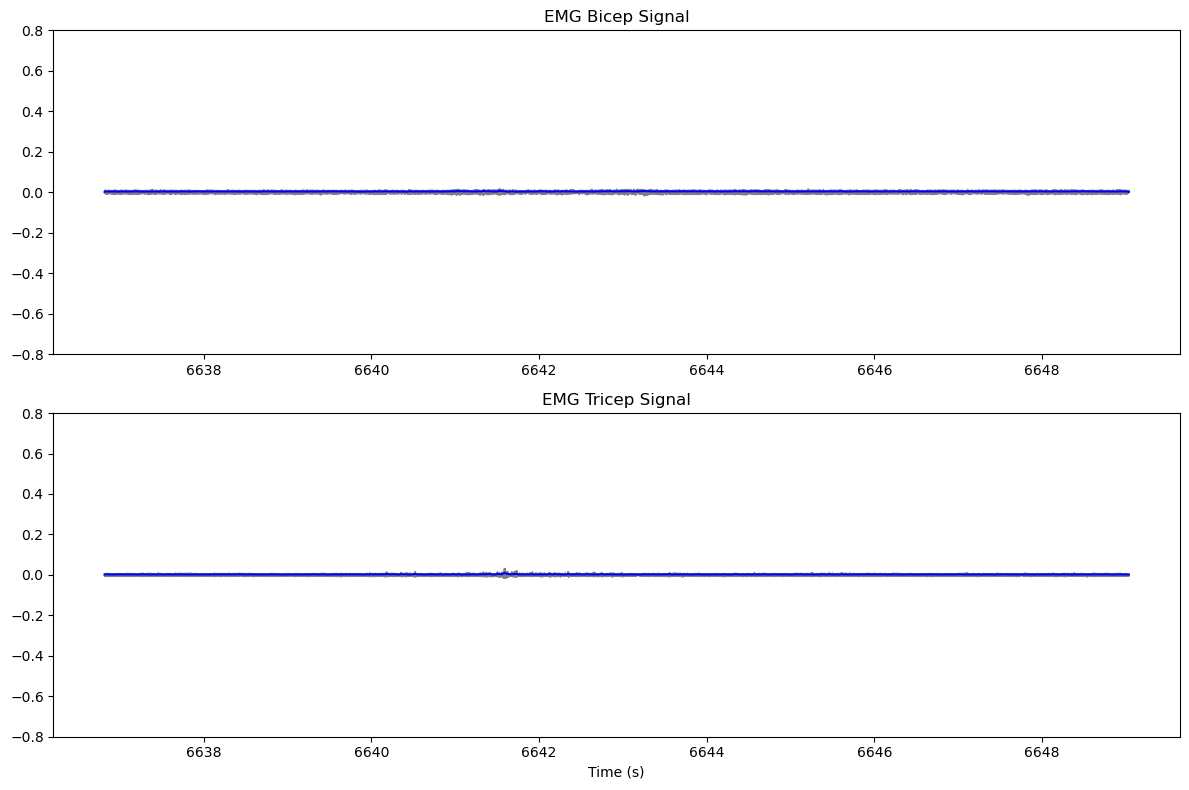

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_3_StartParticipantSinging_NoVision_Movement_3_EndParticipantSinging.csv


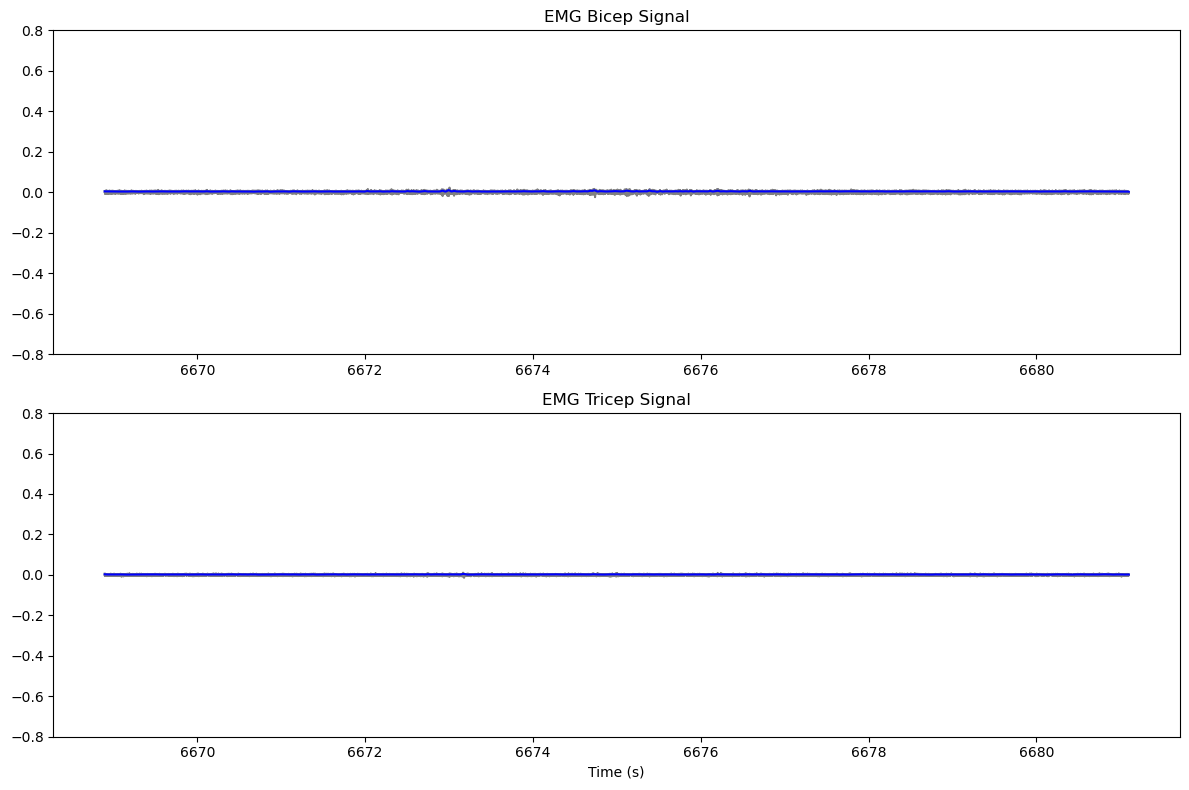

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_Movement_4_StartParticipantSinging_NoVision_Movement_4_EndParticipantSinging.csv


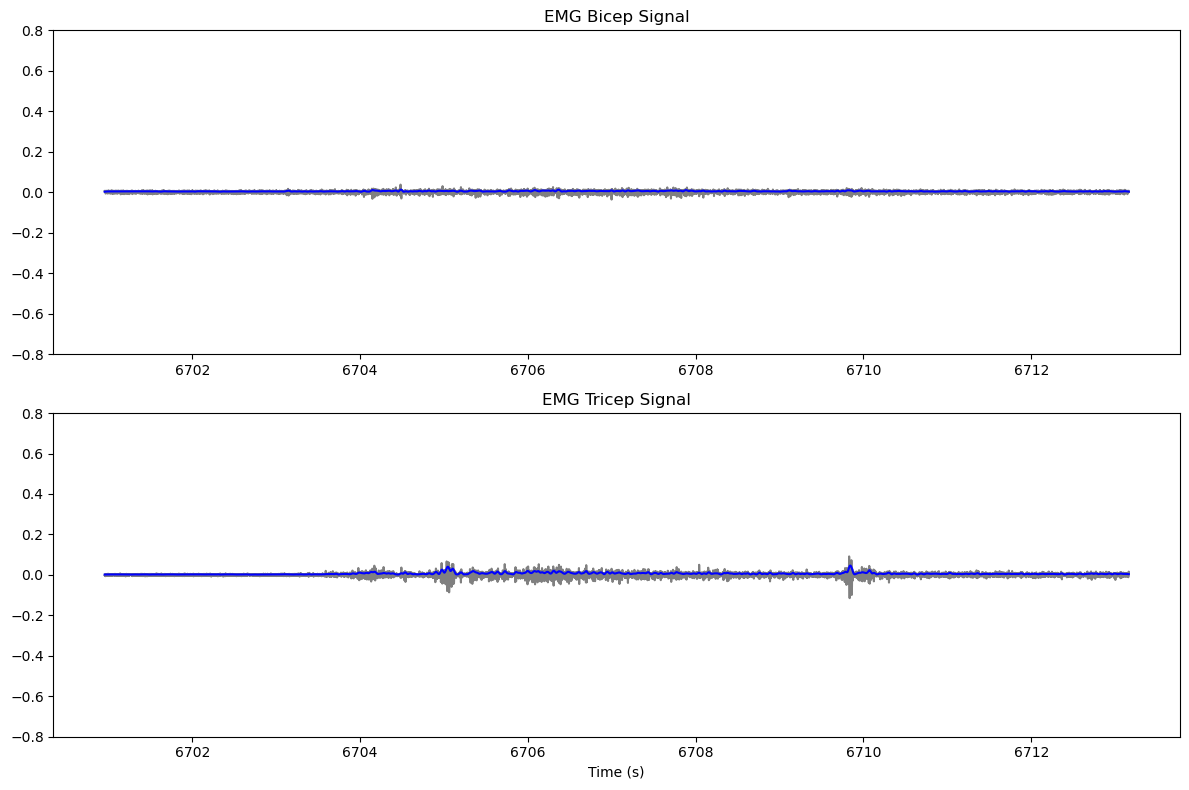

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_0_StartParticipantSinging_NoVision_NoMovement_0_EndParticipantSinging.csv


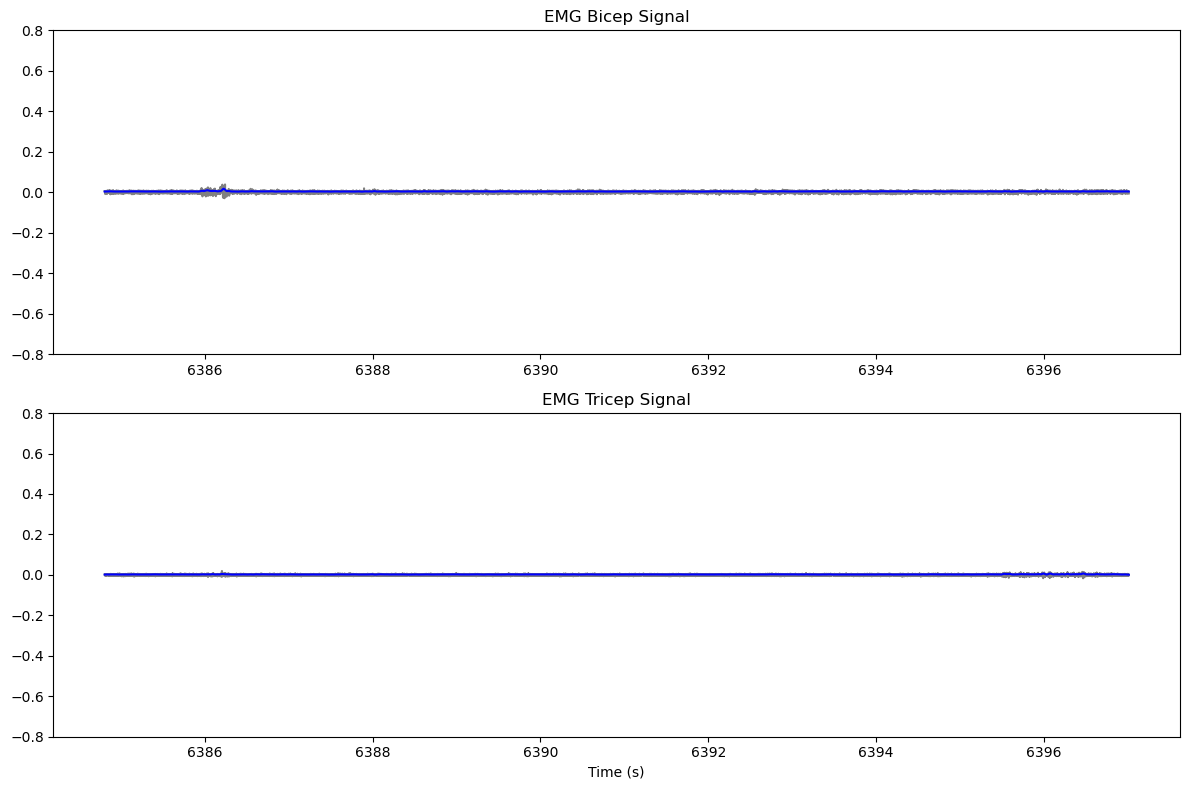

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_1_StartParticipantSinging_NoVision_NoMovement_1_EndParticipantSinging.csv


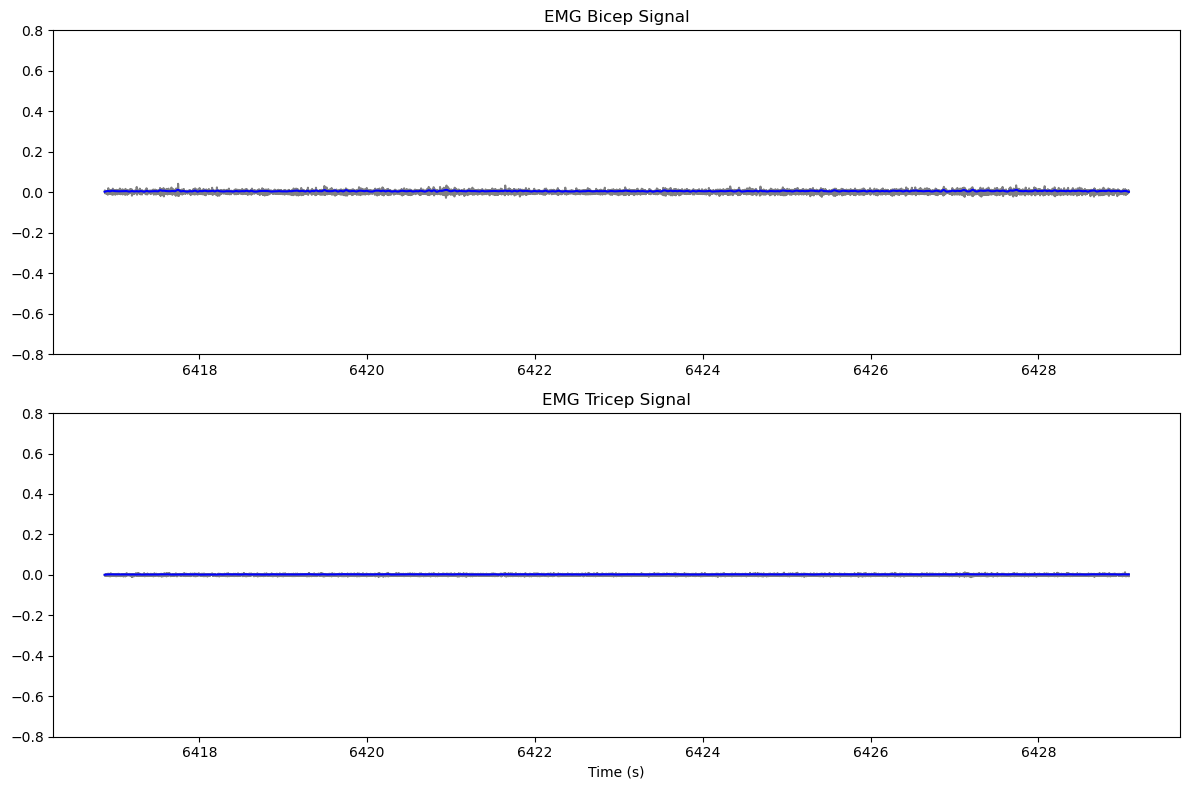

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_2_StartParticipantSinging_NoVision_NoMovement_2_EndParticipantSinging.csv


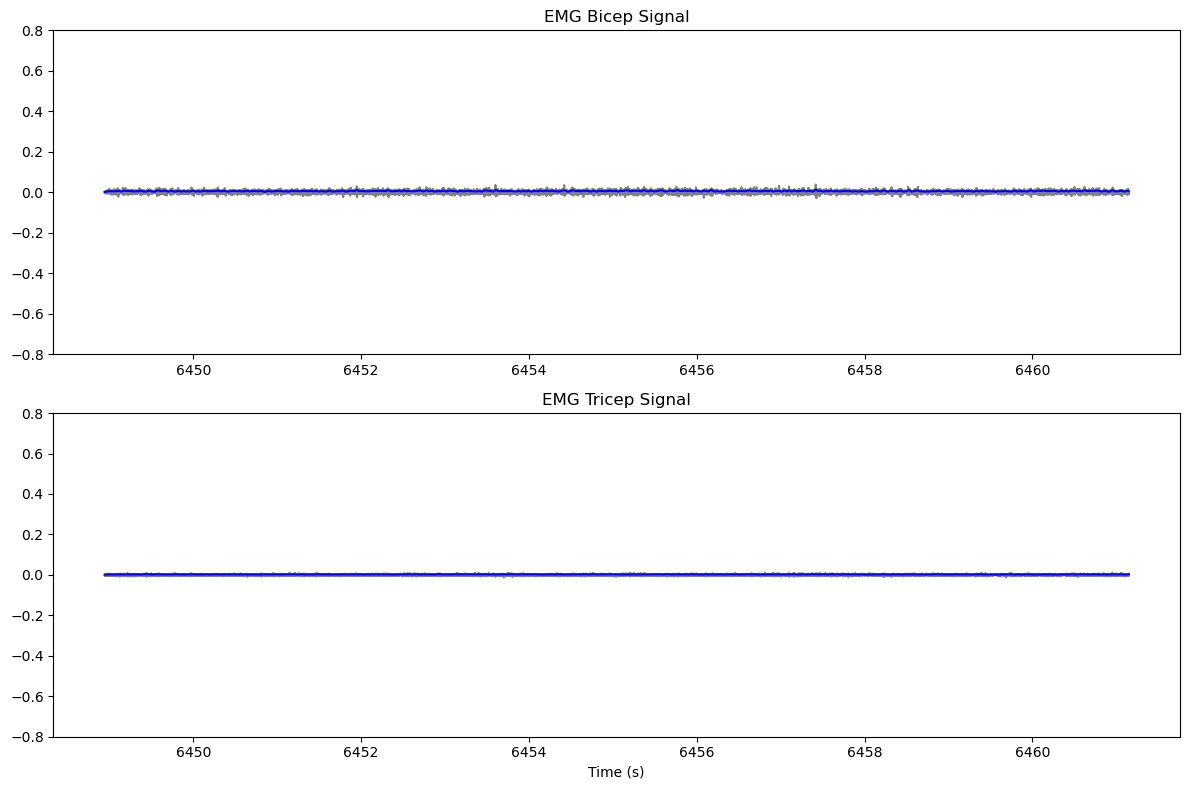

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_3_StartParticipantSinging_NoVision_NoMovement_3_EndParticipantSinging.csv


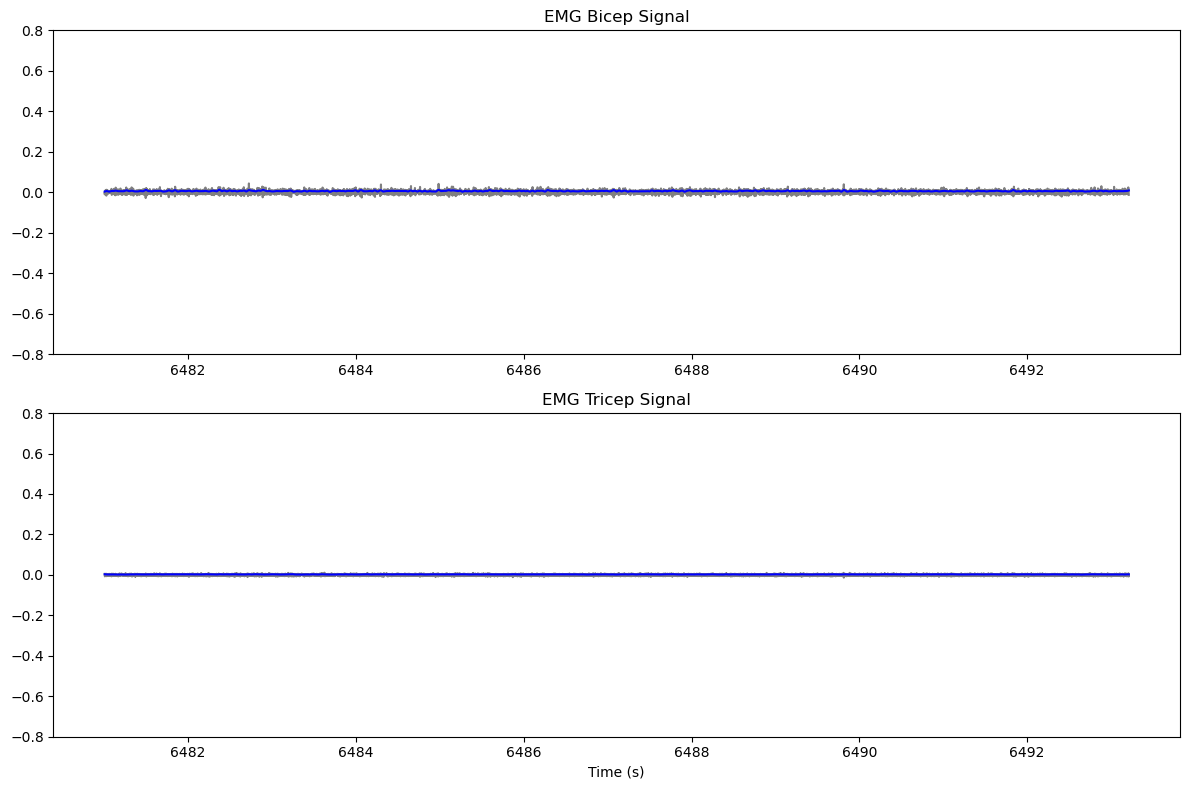

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_NoVision_NoMovement_4_StartParticipantSinging_NoVision_NoMovement_4_EndParticipantSinging.csv


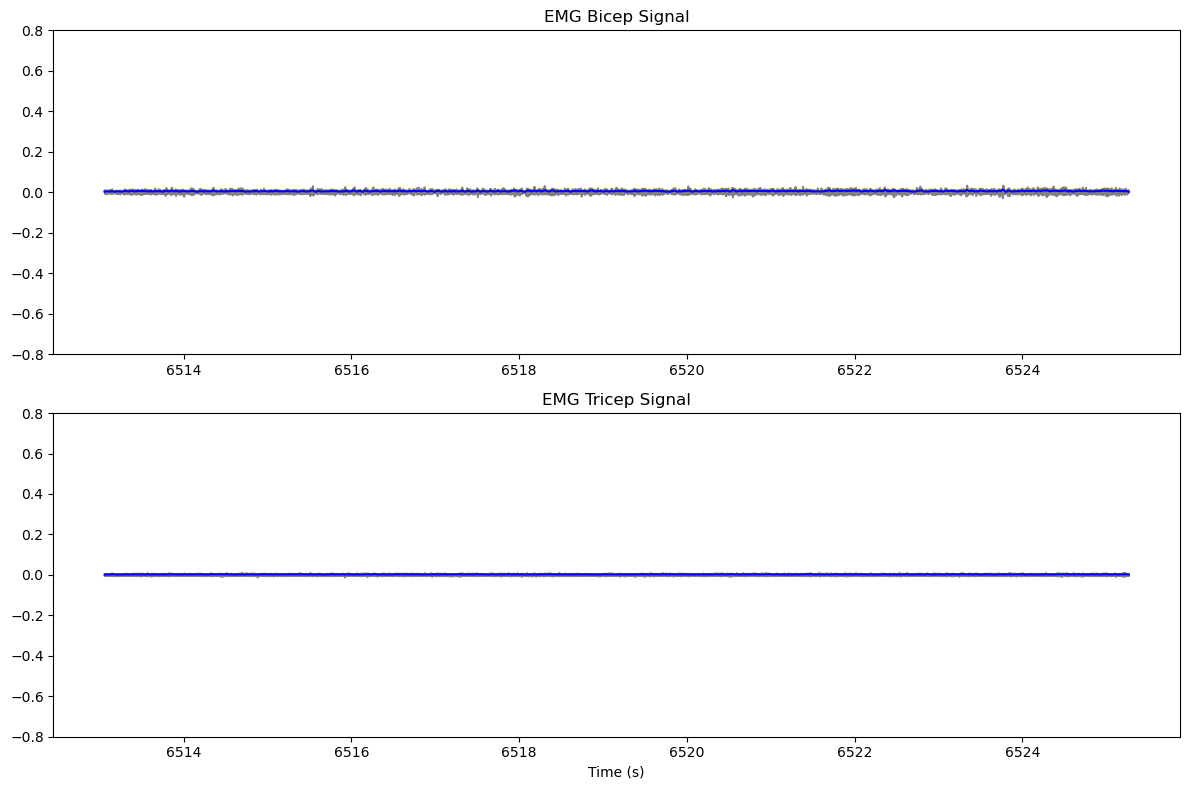

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_NoVision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_0_StartParticipantSinging_Vision_Movement_0_EndParticipantSinging.csv


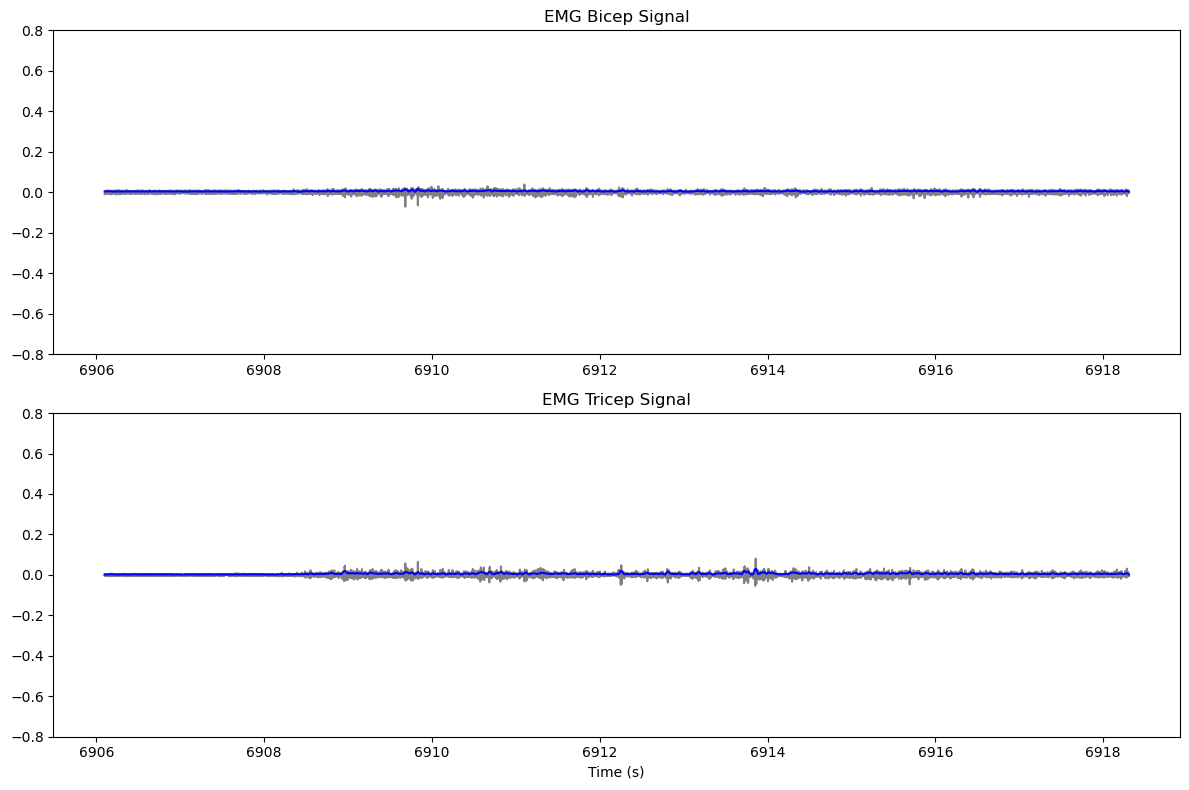

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_1_StartParticipantSinging_Vision_Movement_1_EndParticipantSinging.csv


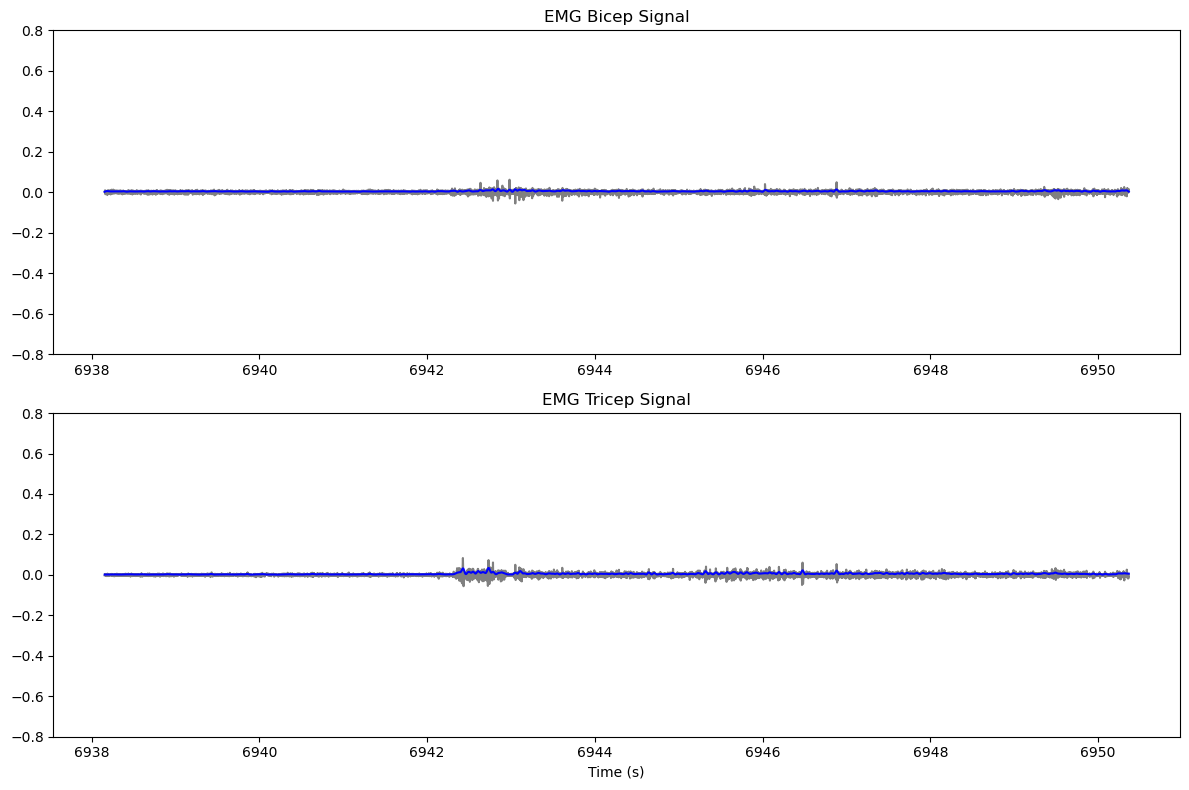

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_2_StartParticipantSinging_Vision_Movement_2_EndParticipantSinging.csv


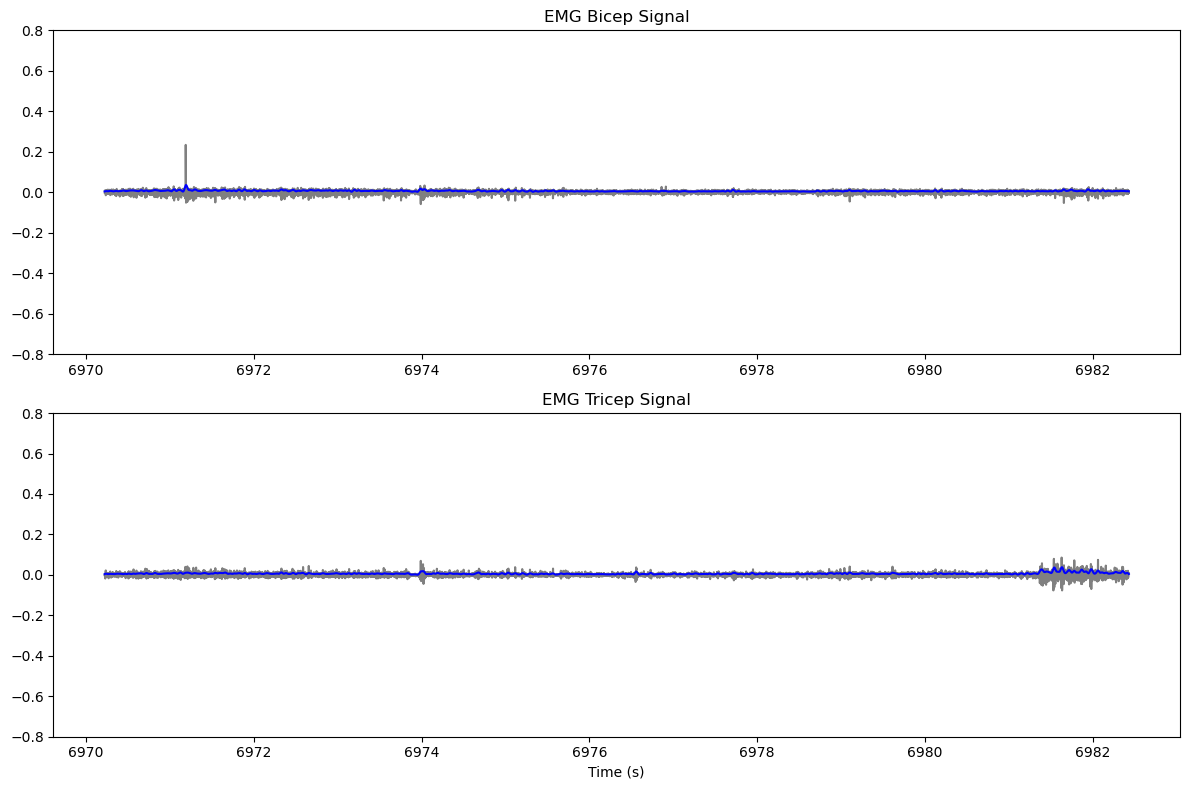

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_3_StartParticipantSinging_Vision_Movement_3_EndParticipantSinging.csv


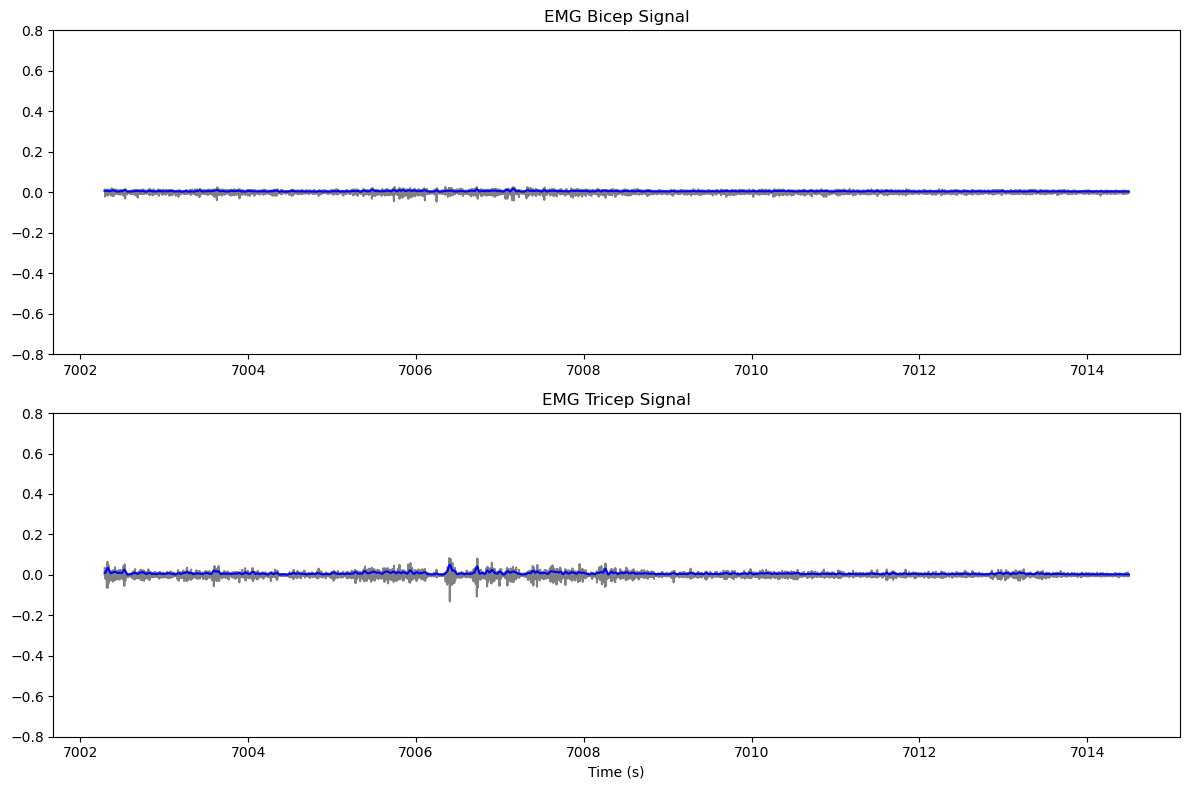

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_Movement_4_StartParticipantSinging_Vision_Movement_4_EndParticipantSinging.csv


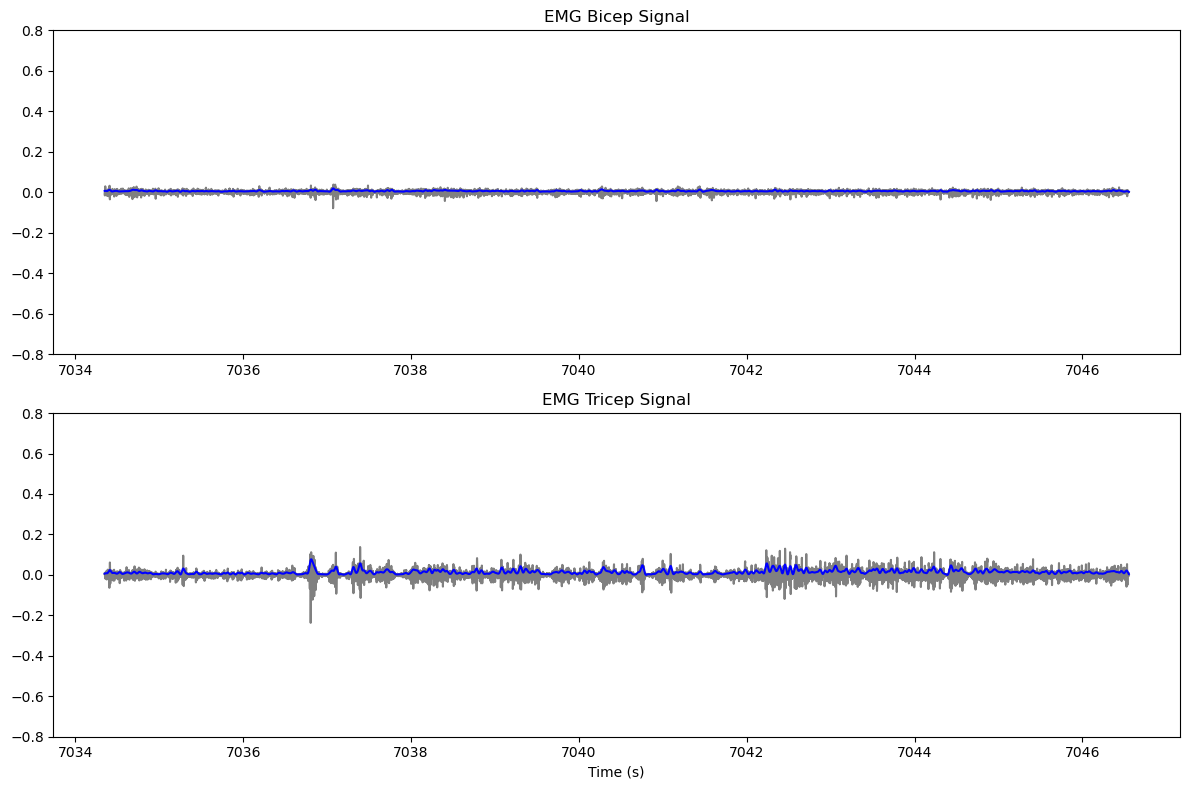

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_0_StartParticipantSinging_Vision_NoMovement_0_EndParticipantSinging.csv


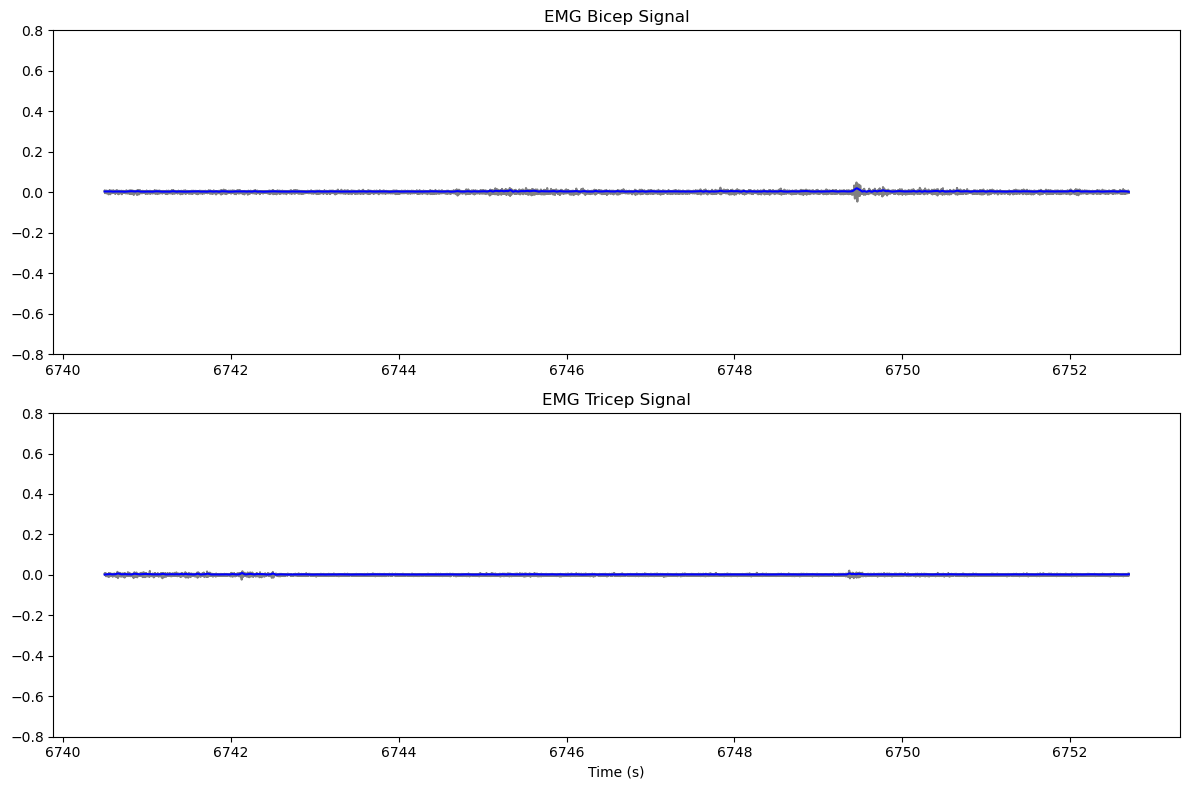

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_1_StartParticipantSinging_Vision_NoMovement_1_EndParticipantSinging.csv


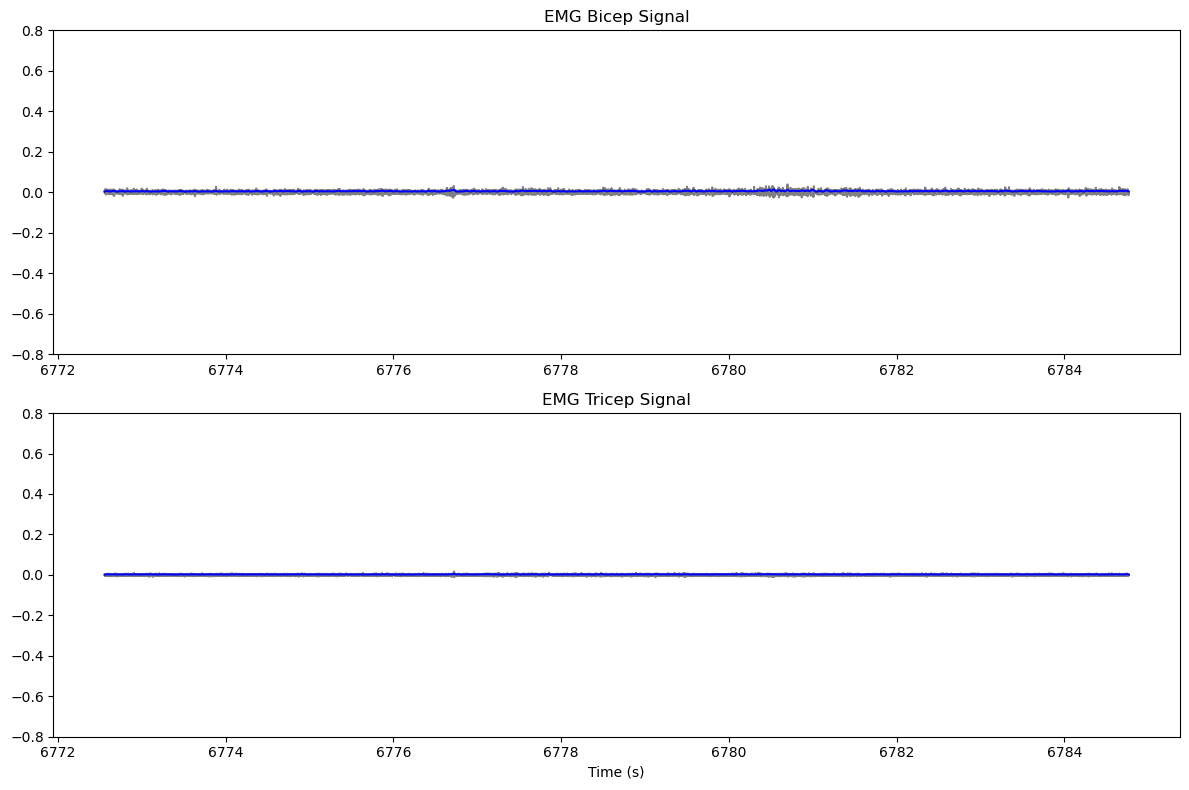

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_2_StartParticipantSinging_Vision_NoMovement_2_EndParticipantSinging.csv


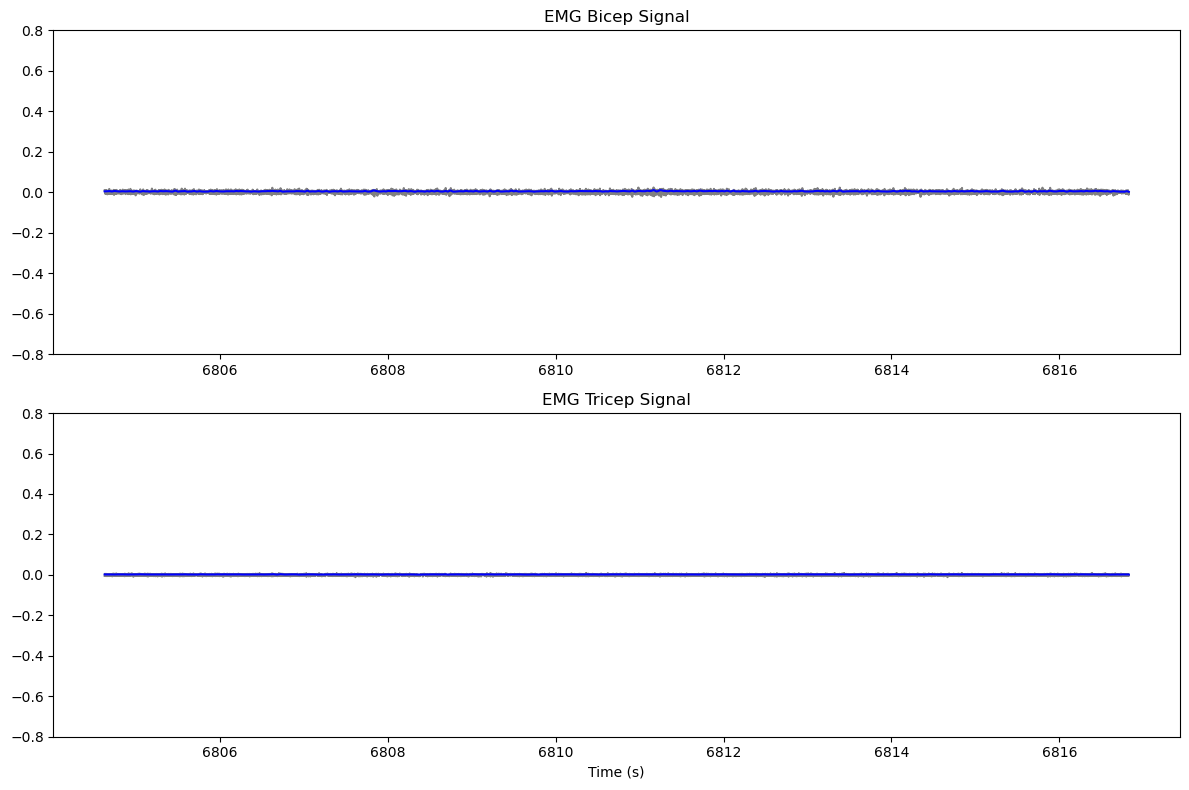

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_3_StartParticipantSinging_Vision_NoMovement_3_EndParticipantSinging.csv


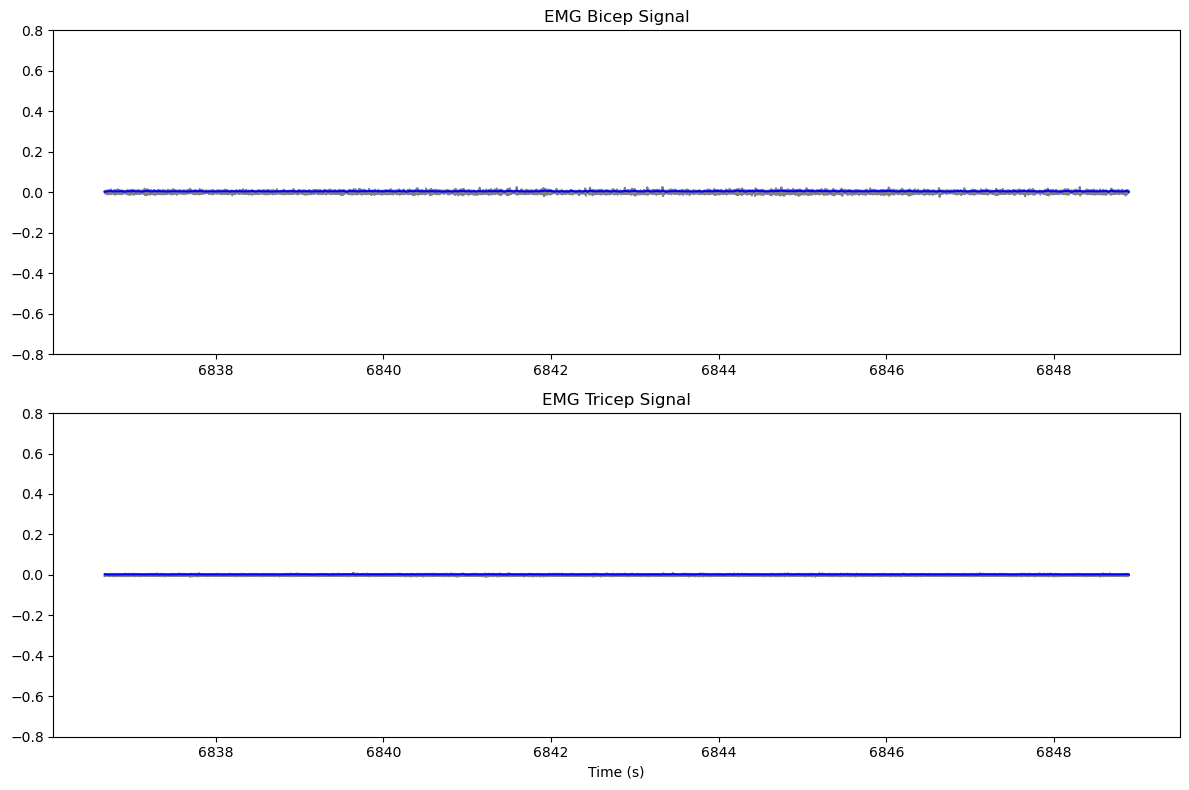

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P1_Vision_NoMovement_4_StartParticipantSinging_Vision_NoMovement_4_EndParticipantSinging.csv


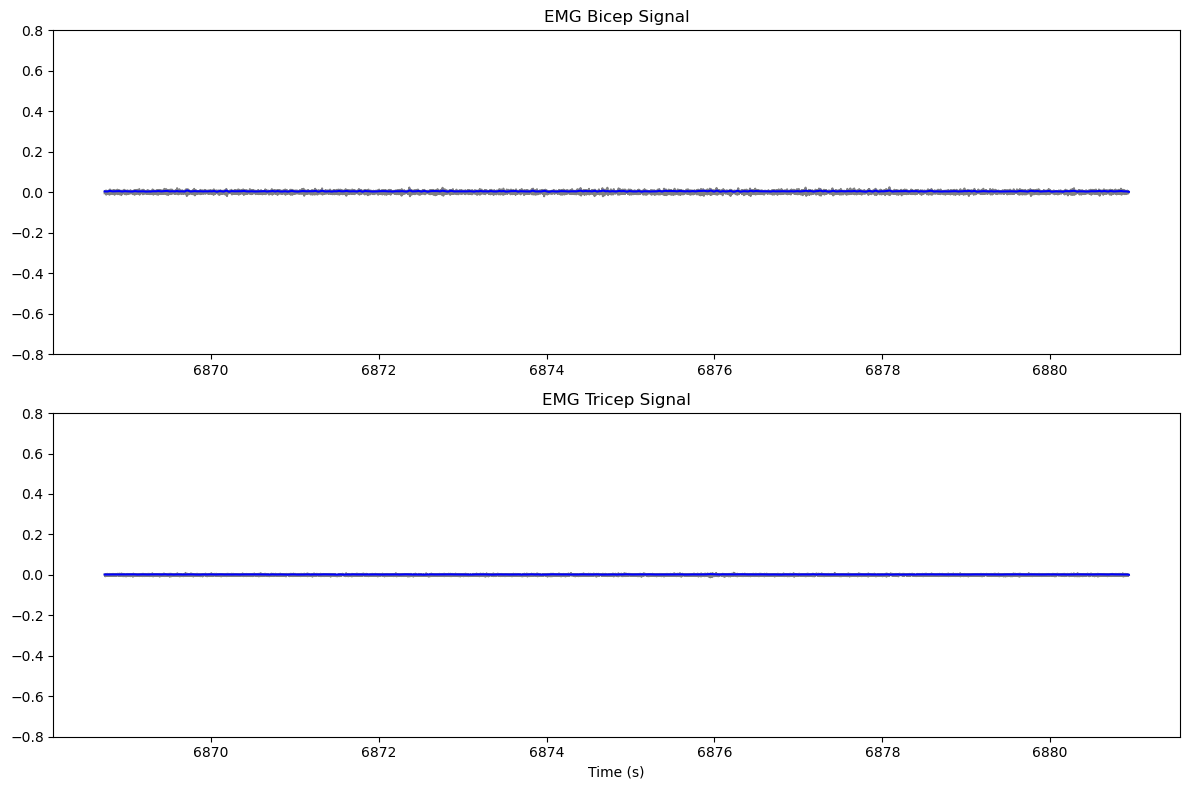

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P1_Vision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_0_StartParticipantSinging_NoVision_Movement_0_EndParticipantSinging.csv


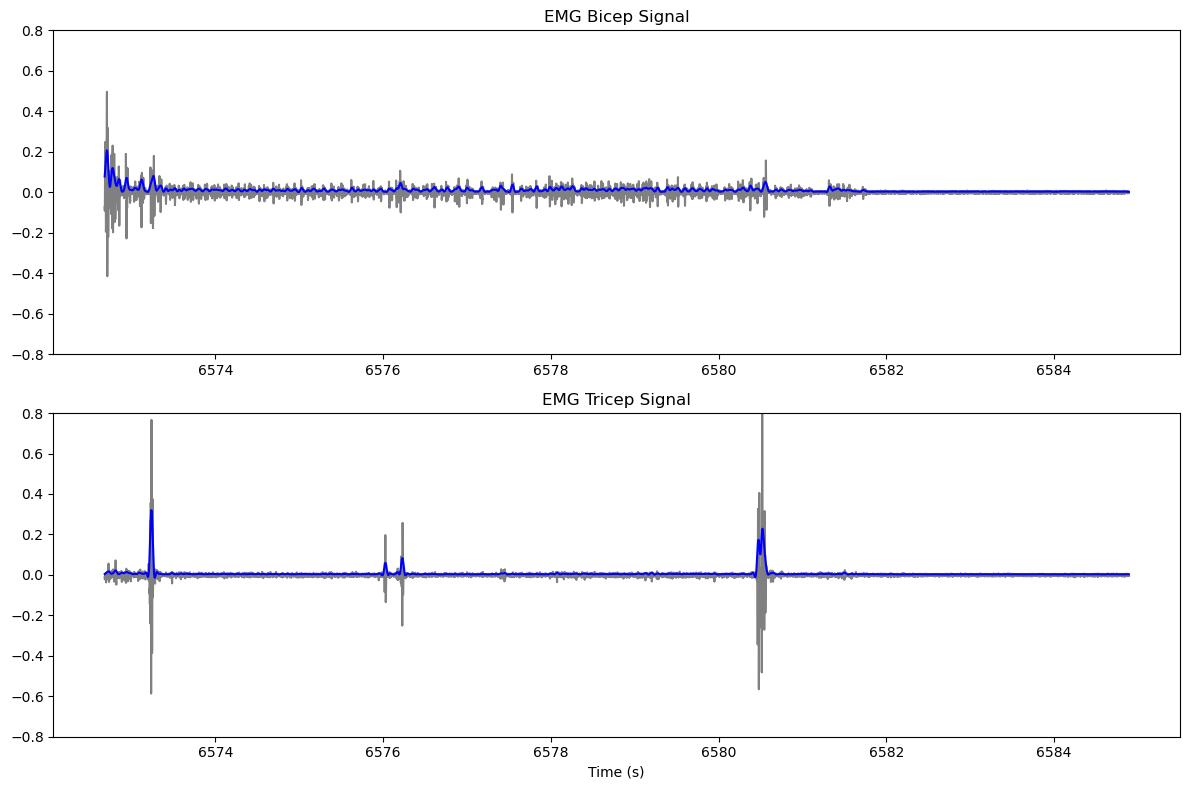

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_1_StartParticipantSinging_NoVision_Movement_1_EndParticipantSinging.csv


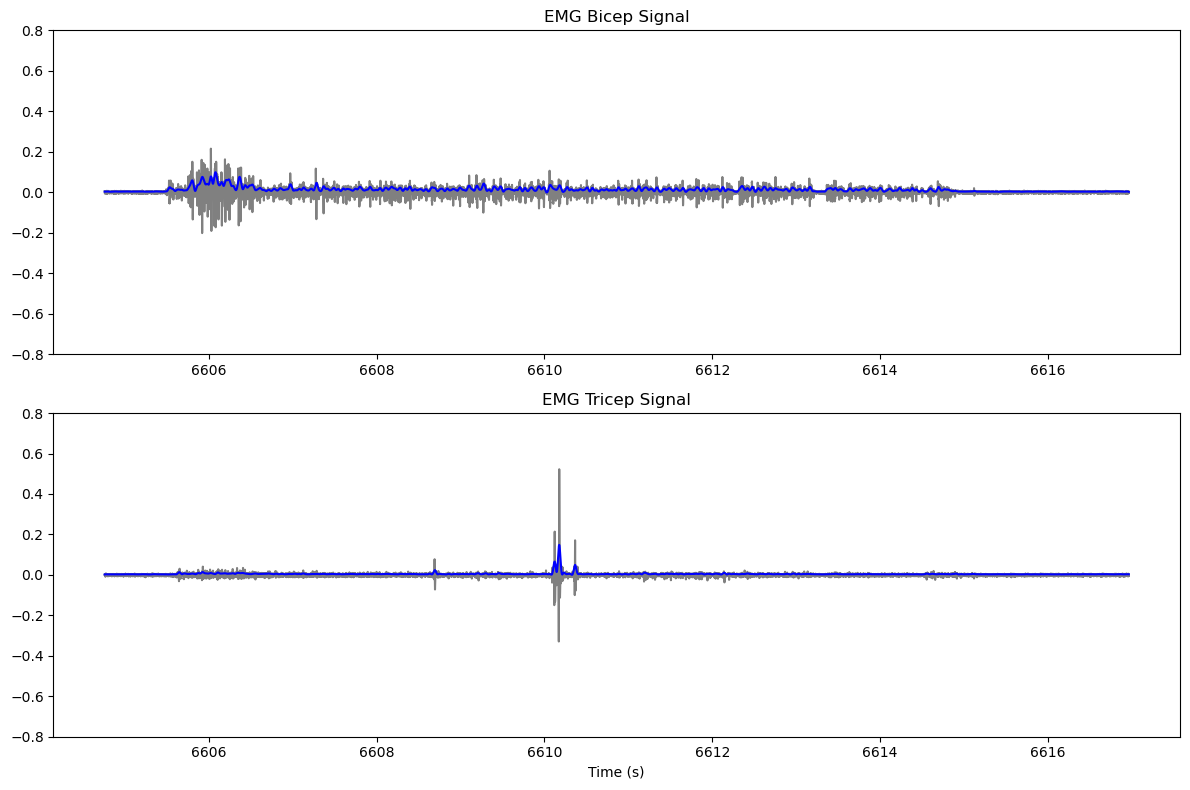

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_2_StartParticipantSinging_NoVision_Movement_2_EndParticipantSinging.csv


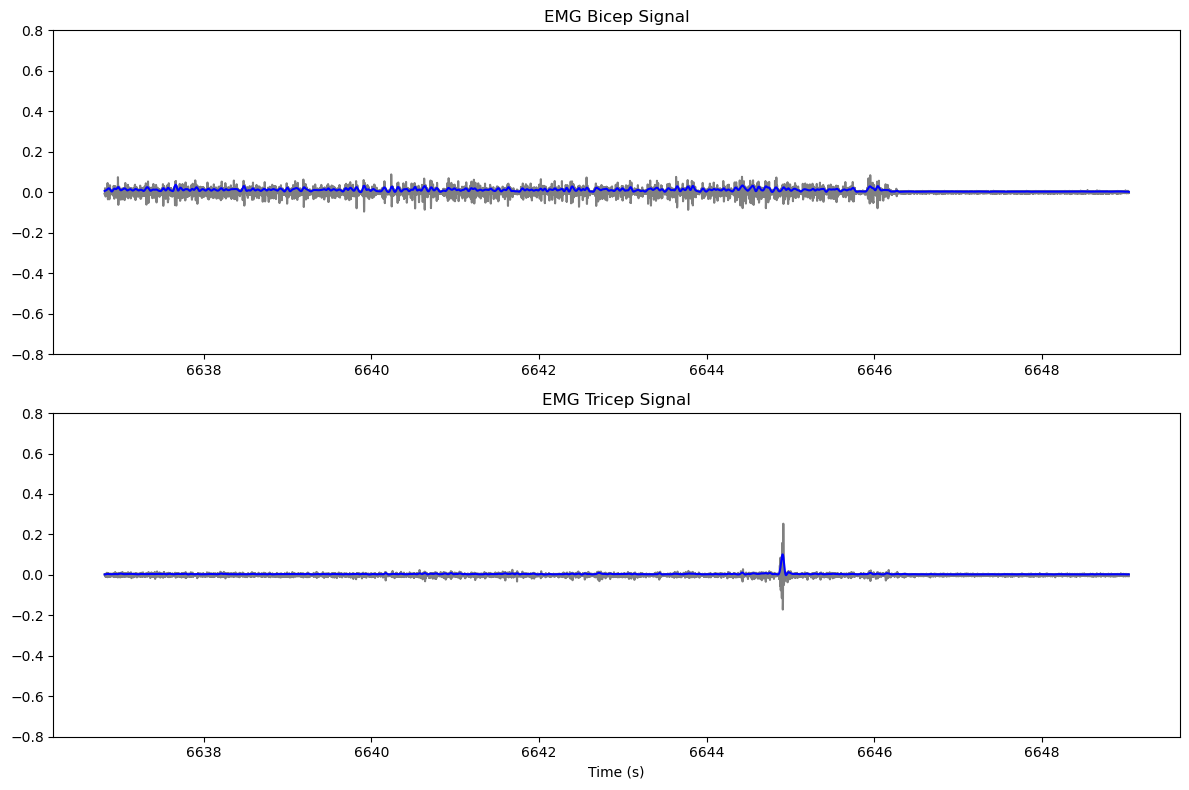

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_3_StartParticipantSinging_NoVision_Movement_3_EndParticipantSinging.csv


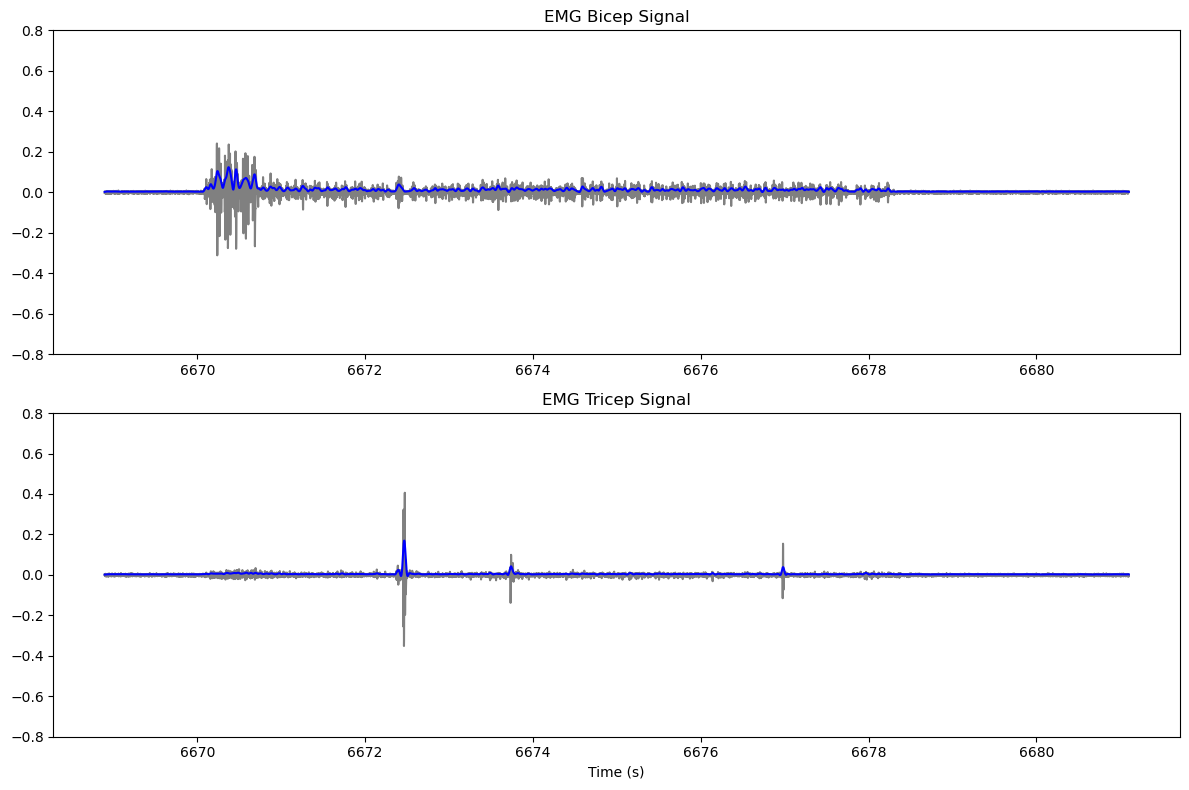

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_Movement_4_StartParticipantSinging_NoVision_Movement_4_EndParticipantSinging.csv


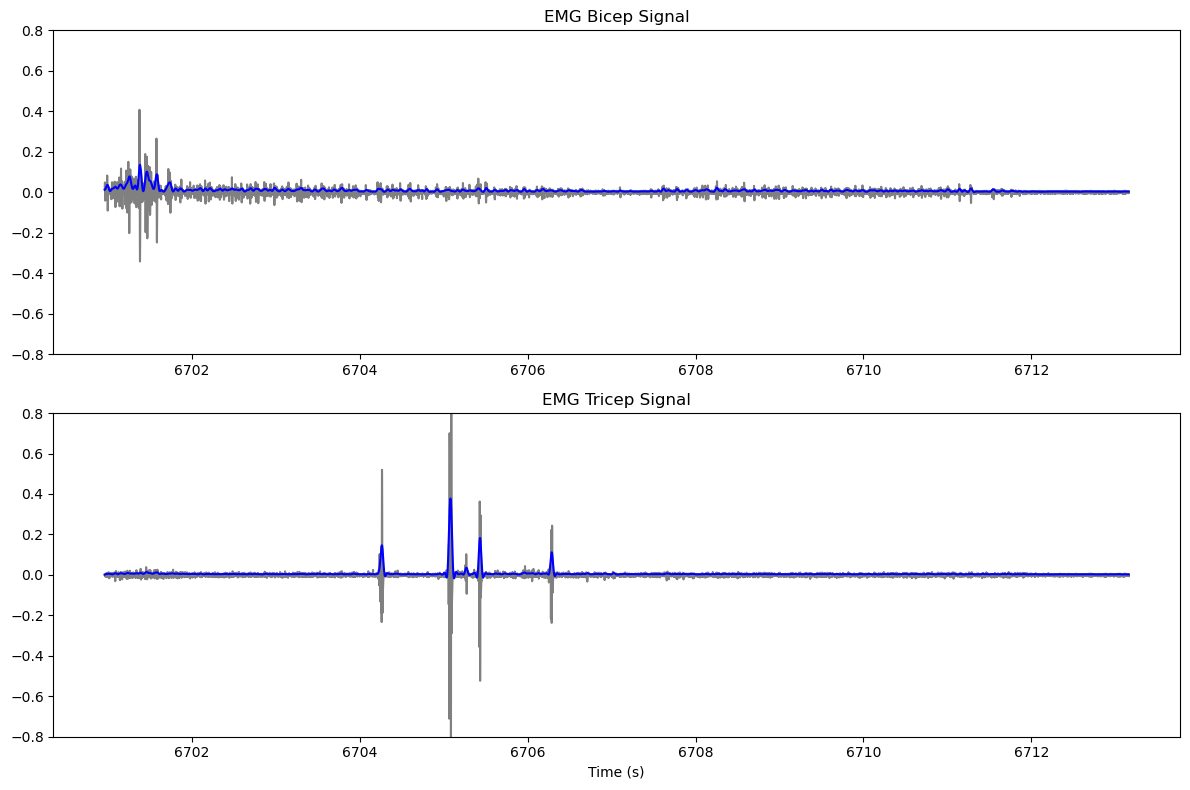

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_0_StartParticipantSinging_NoVision_NoMovement_0_EndParticipantSinging.csv


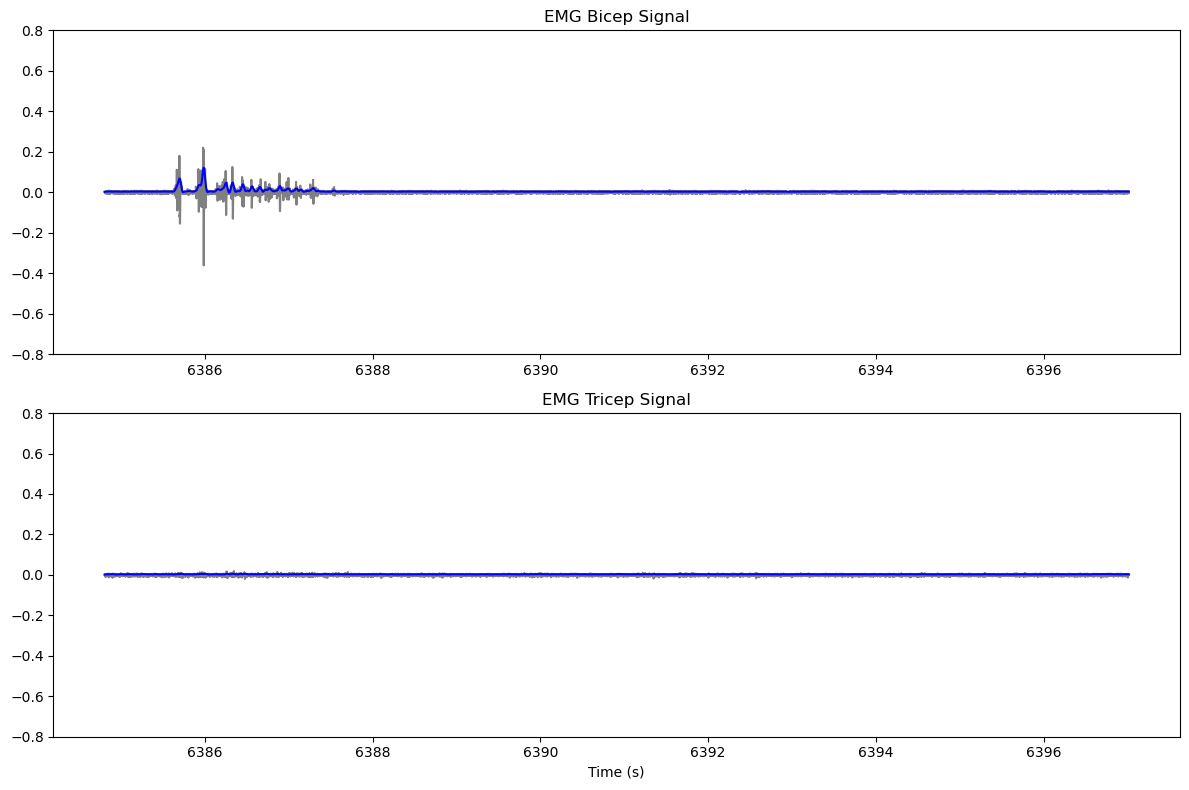

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_1_StartParticipantSinging_NoVision_NoMovement_1_EndParticipantSinging.csv


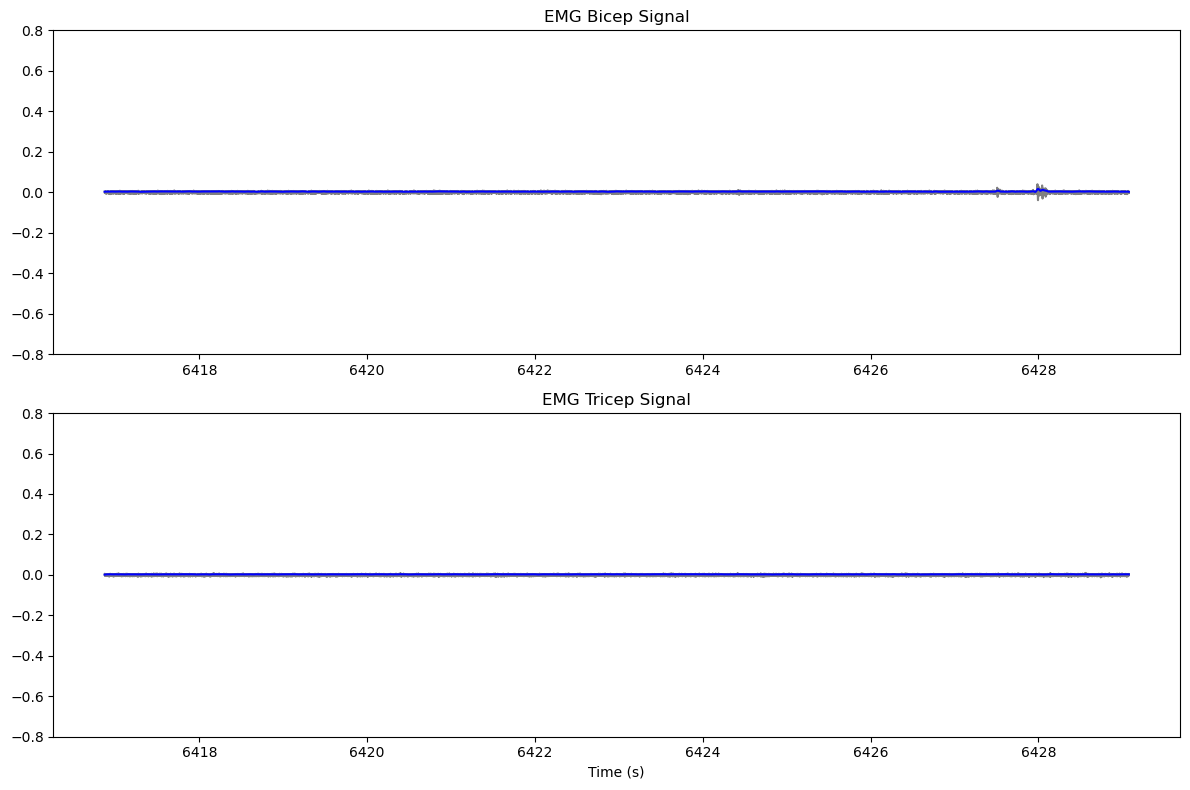

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_2_StartParticipantSinging_NoVision_NoMovement_2_EndParticipantSinging.csv


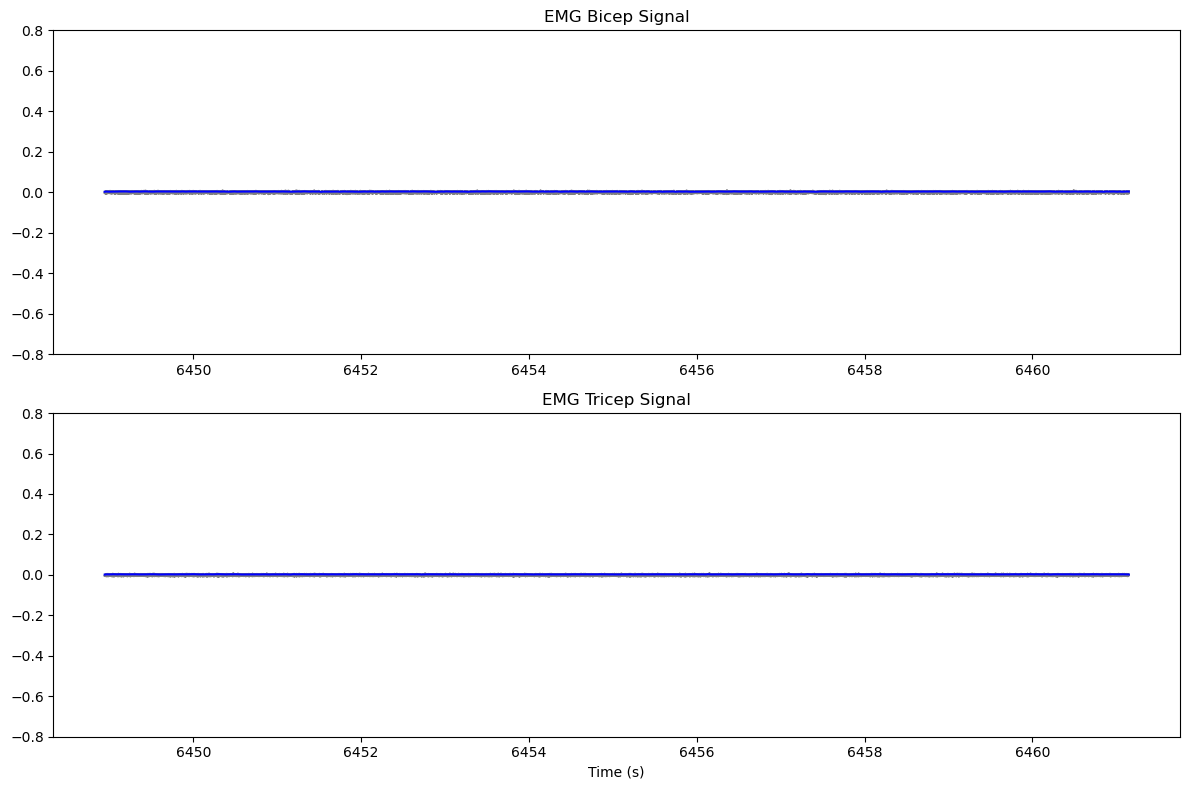

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_3_StartParticipantSinging_NoVision_NoMovement_3_EndParticipantSinging.csv


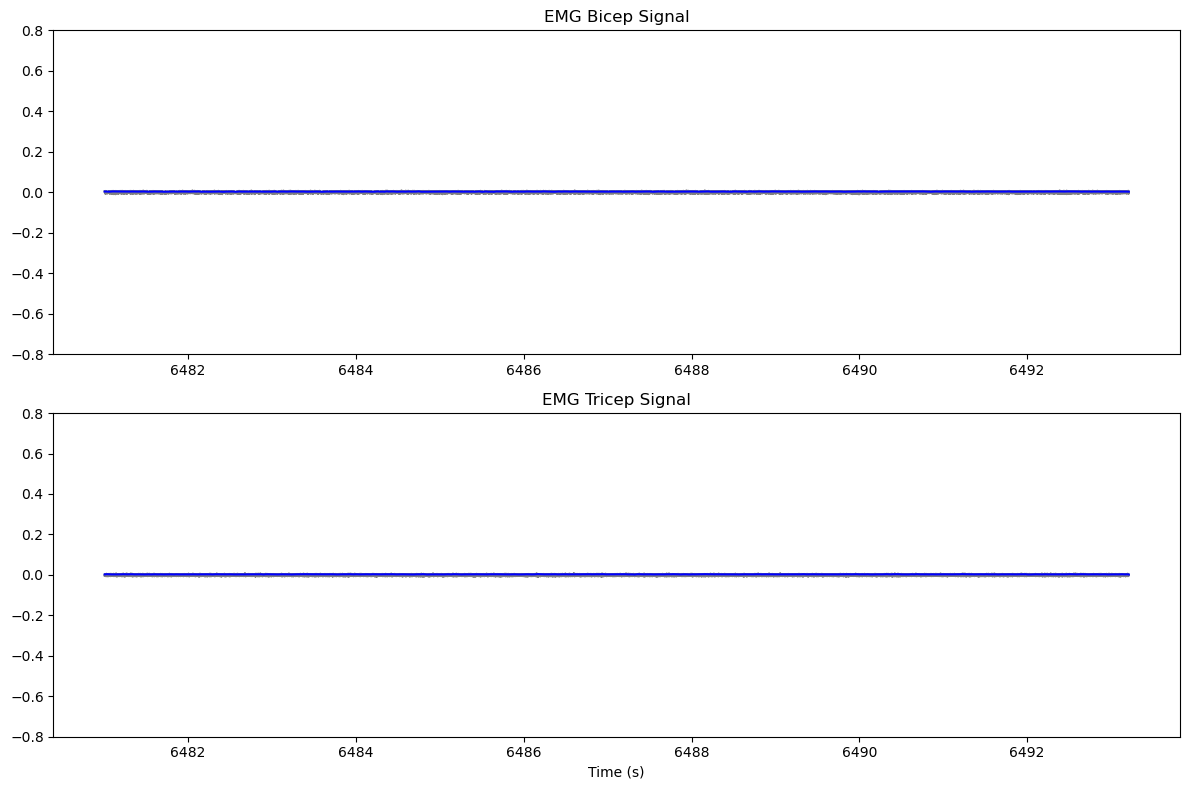

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_NoVision_NoMovement_4_StartParticipantSinging_NoVision_NoMovement_4_EndParticipantSinging.csv


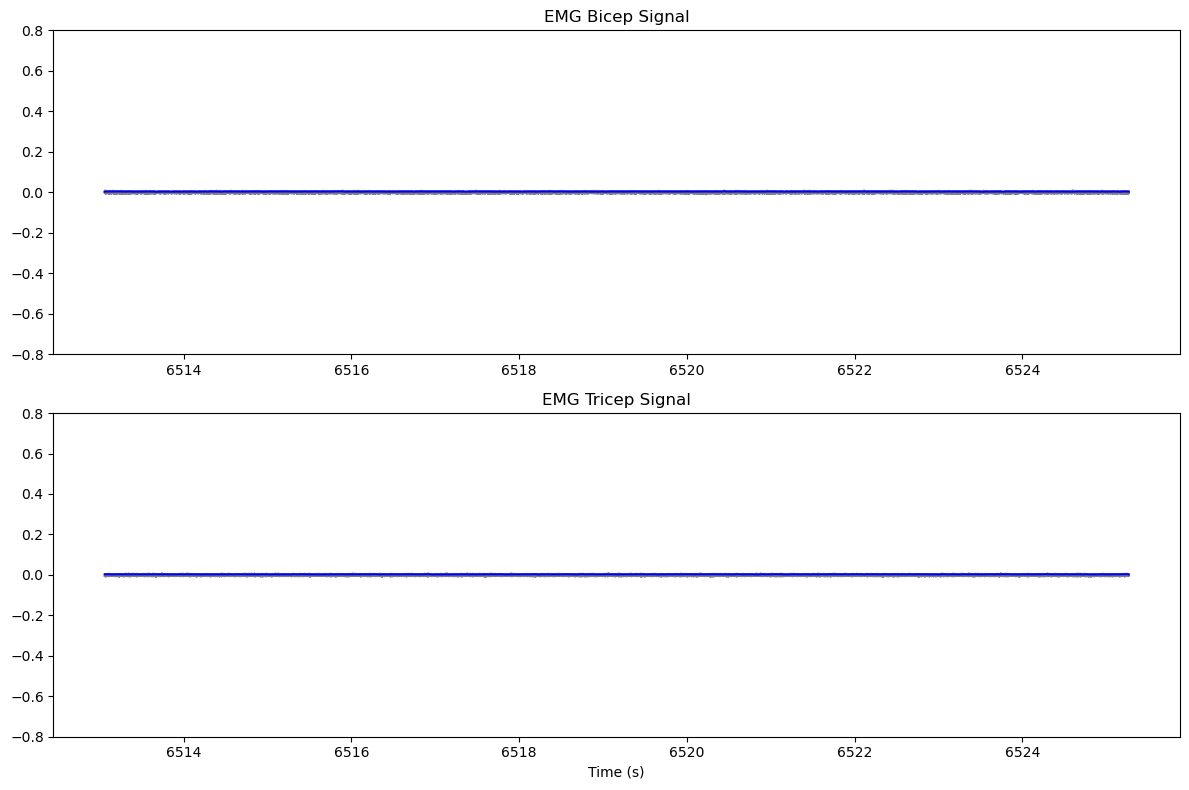

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_NoVision_NoMovement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_0_StartParticipantSinging_Vision_Movement_0_EndParticipantSinging.csv


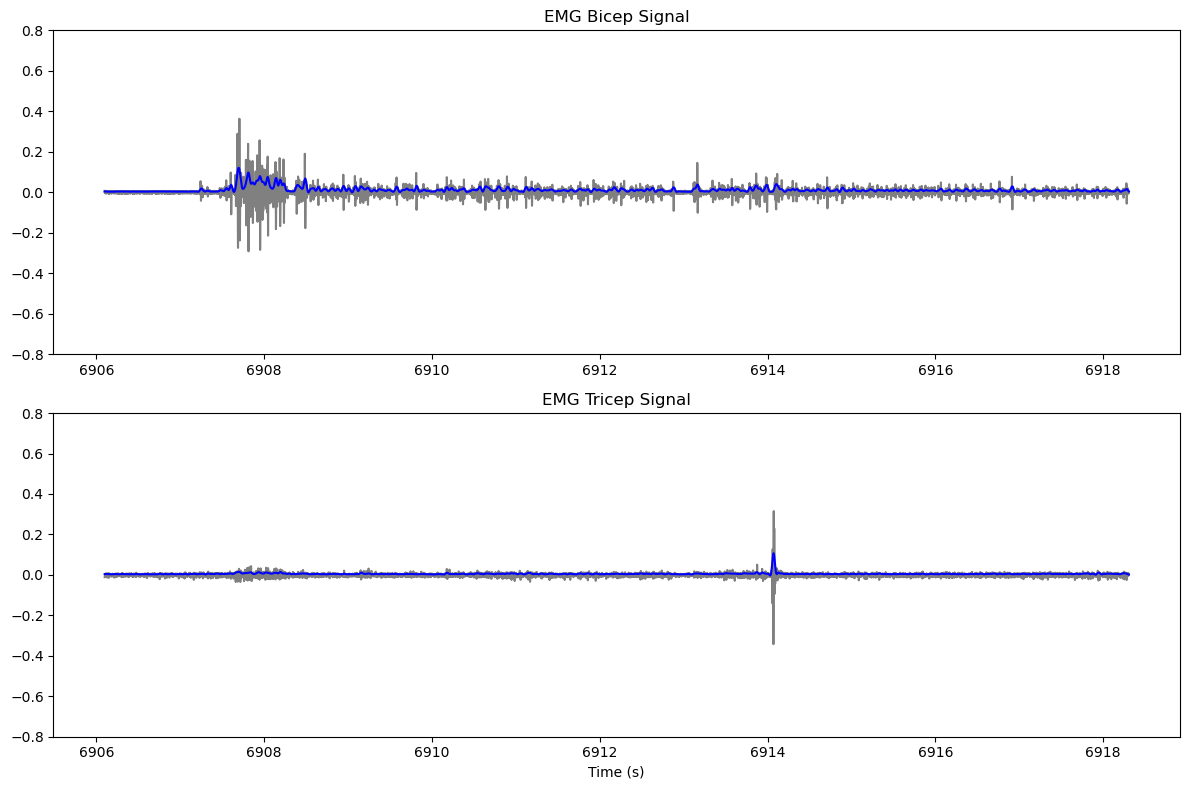

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_Movement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_1_StartParticipantSinging_Vision_Movement_1_EndParticipantSinging.csv


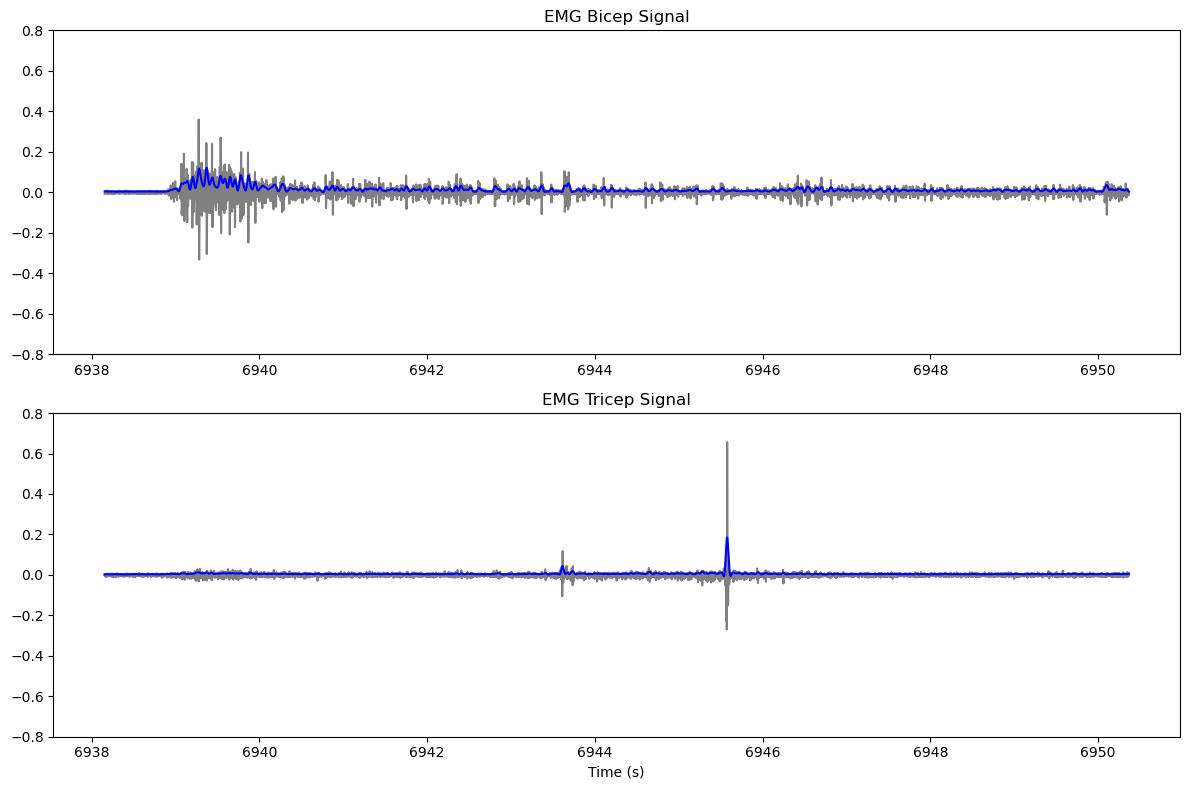

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_Movement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_2_StartParticipantSinging_Vision_Movement_2_EndParticipantSinging.csv


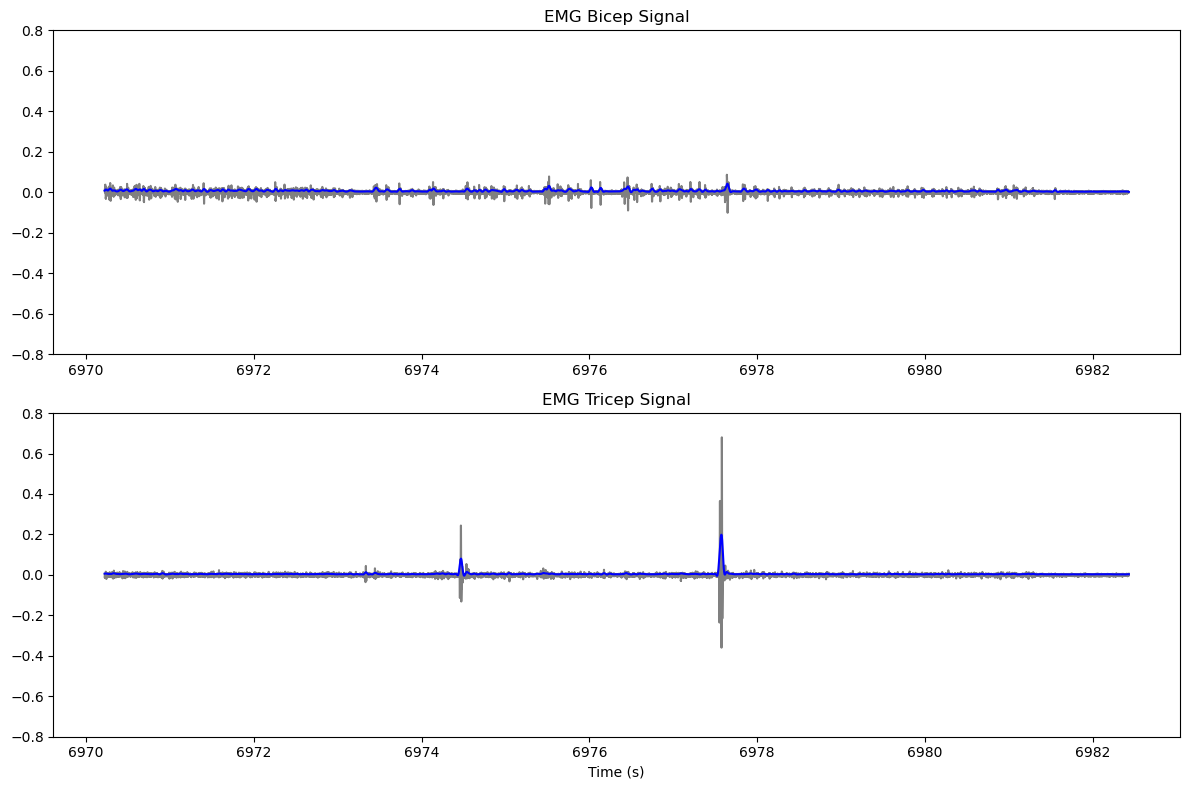

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_Movement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_3_StartParticipantSinging_Vision_Movement_3_EndParticipantSinging.csv


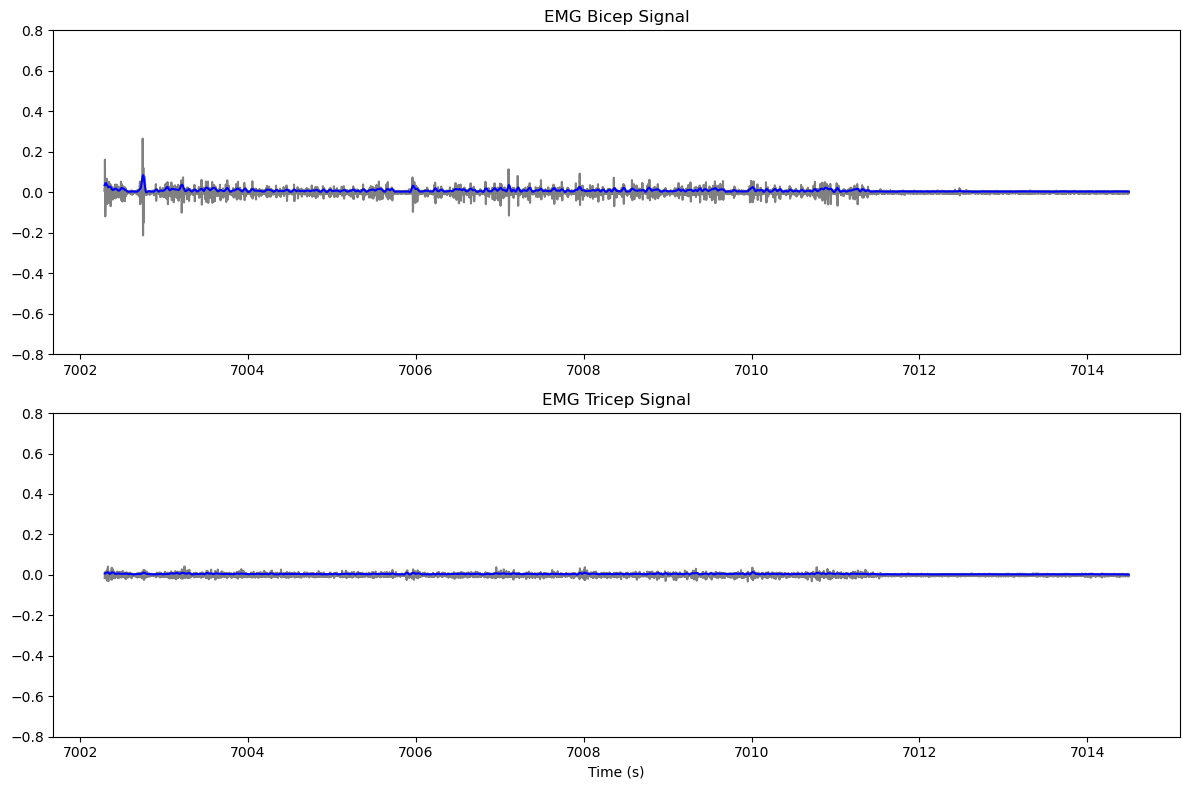

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_Movement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_Movement_4_StartParticipantSinging_Vision_Movement_4_EndParticipantSinging.csv


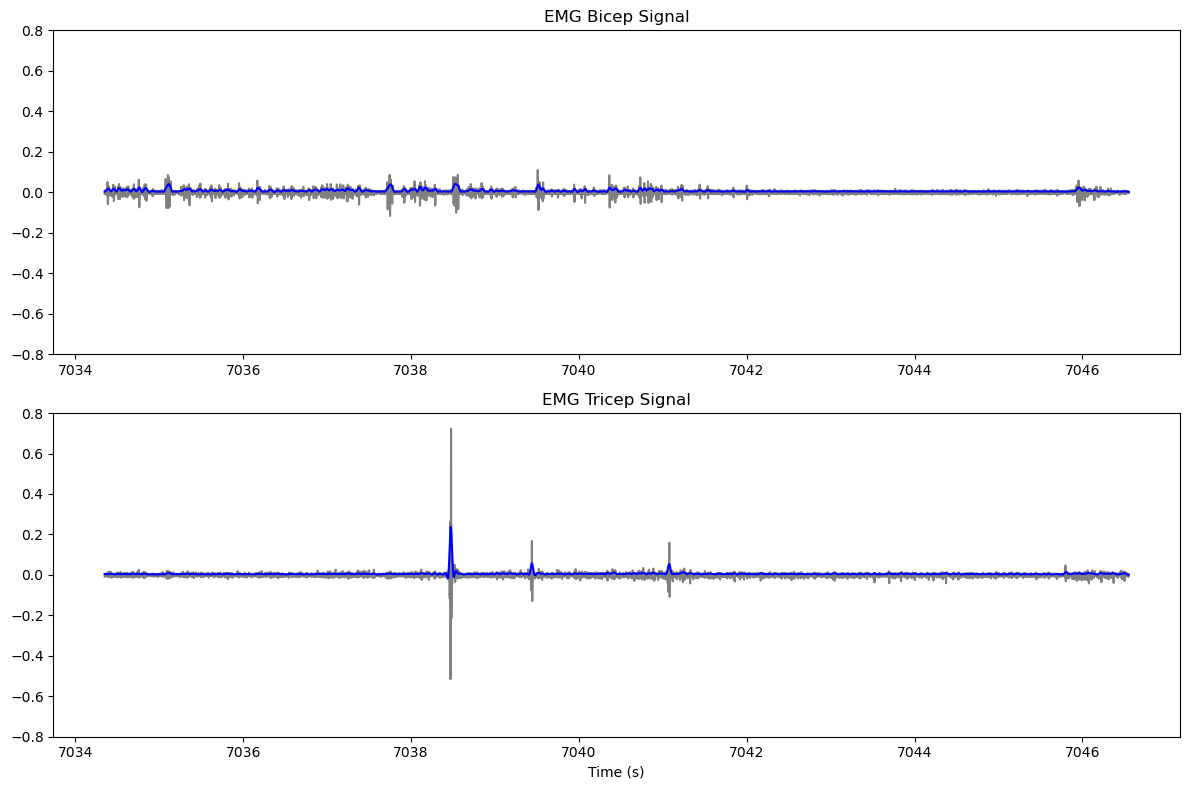

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_Movement_4.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_0_StartParticipantSinging_Vision_NoMovement_0_EndParticipantSinging.csv


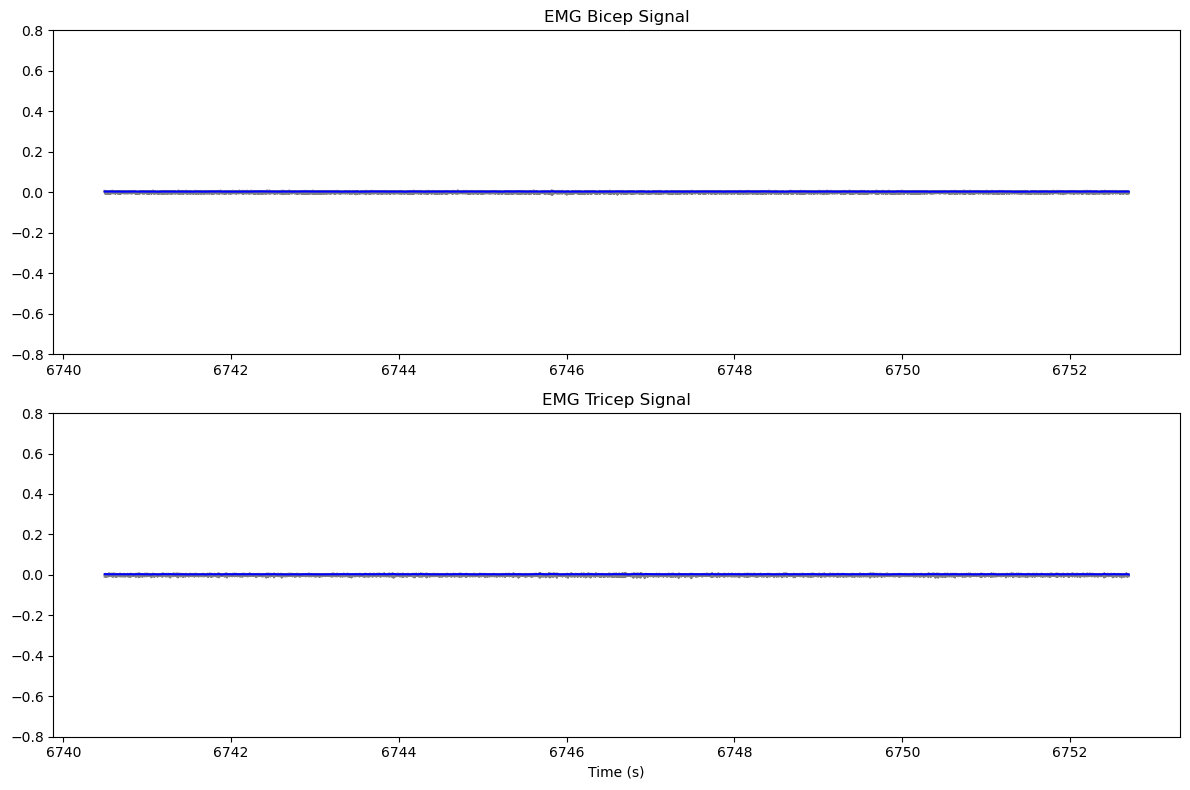

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_NoMovement_0.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_1_StartParticipantSinging_Vision_NoMovement_1_EndParticipantSinging.csv


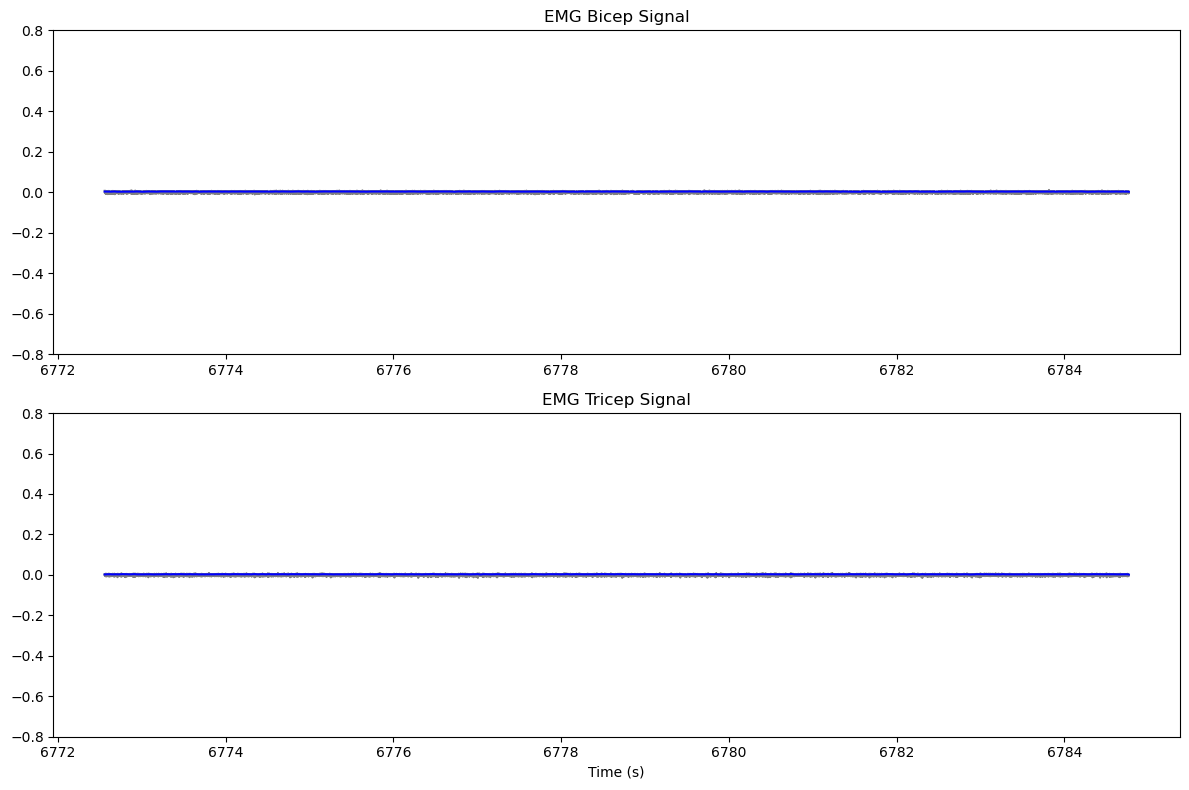

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_NoMovement_1.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_2_StartParticipantSinging_Vision_NoMovement_2_EndParticipantSinging.csv


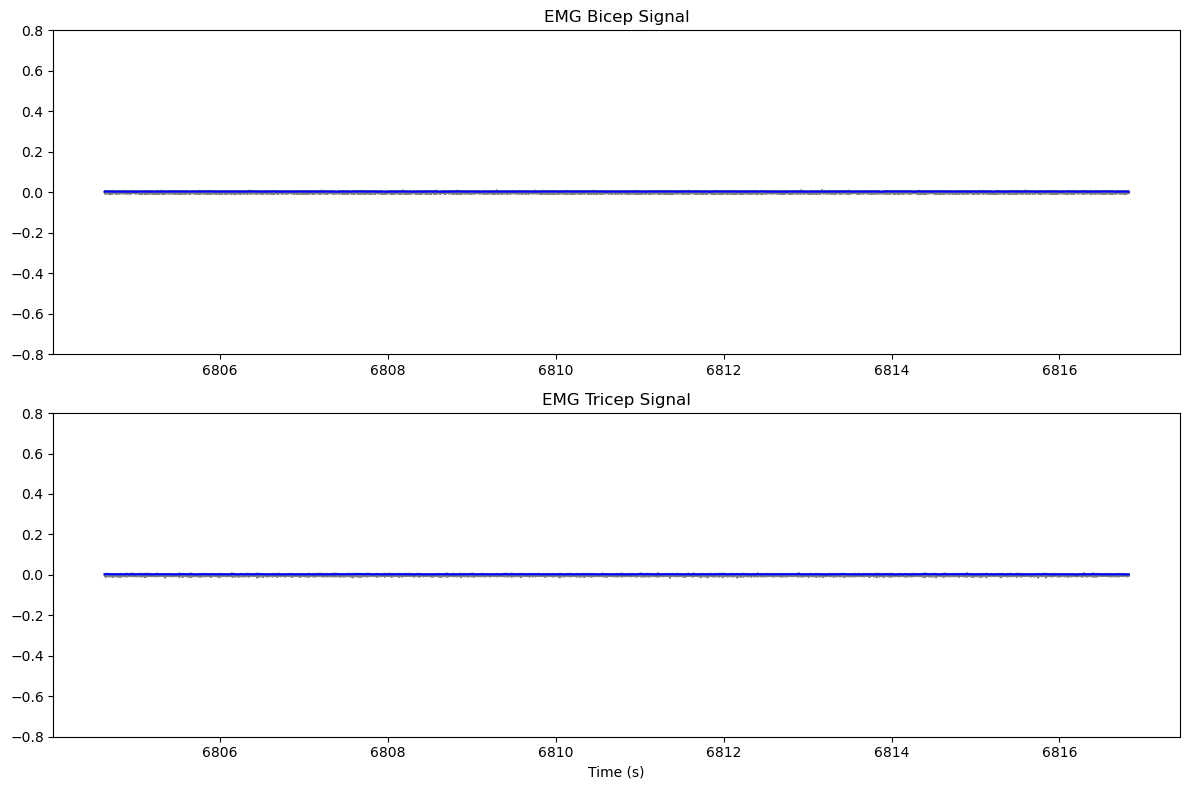

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_NoMovement_2.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_3_StartParticipantSinging_Vision_NoMovement_3_EndParticipantSinging.csv


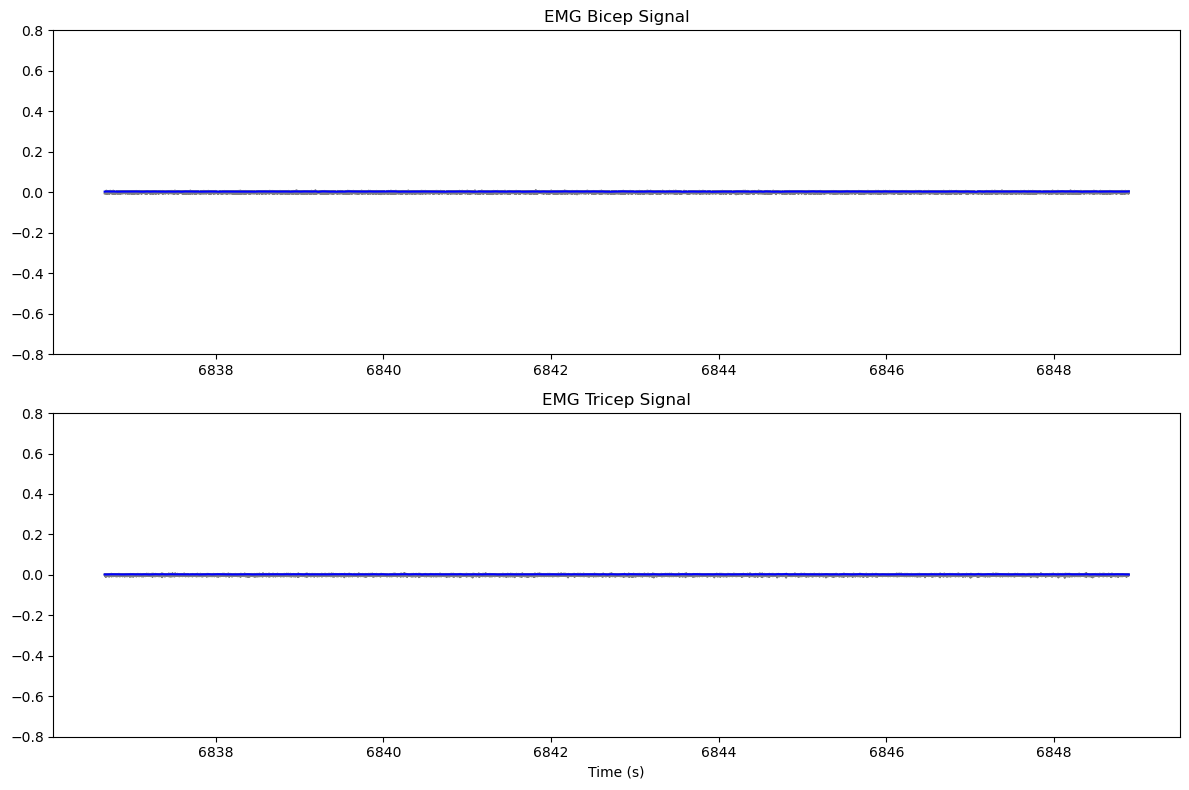

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_NoMovement_3.csv
Processing LSL file:  T1_experiment_PLUX_P2_Vision_NoMovement_4_StartParticipantSinging_Vision_NoMovement_4_EndParticipantSinging.csv


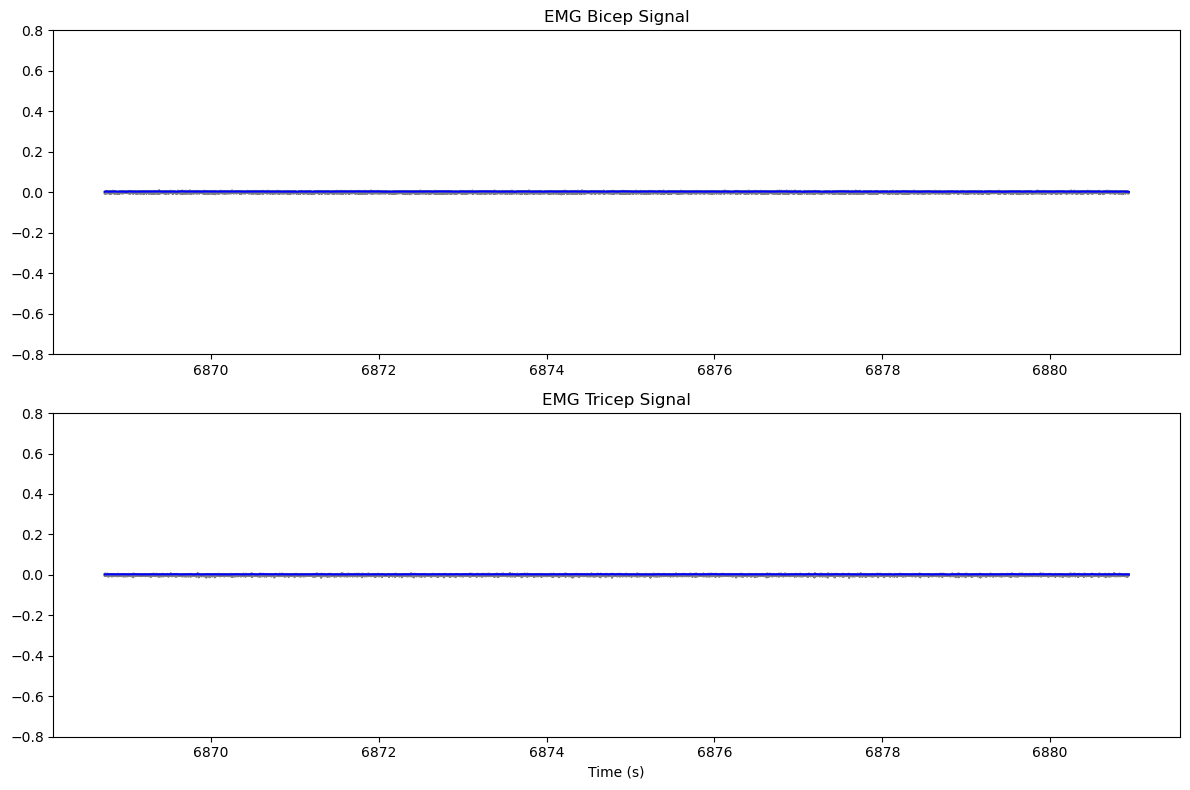

Filtered EMG data saved to:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials\T1_experiment_EMG_P2_Vision_NoMovement_4.csv
All files processed successfully. You can look in the directory:  D:\Mobile-Multimodal-Lab\4_PROCESSED\filtered_trials


In [ ]:
# Define Butterworth filter function
def butter_filter(data, cutoff, fs, order=4, filter_type='low'):
    nyquist = 0.5 * fs  # Nyquist frequency
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype=filter_type, analog=False)
    # Apply zero-phase filtering with padding to prevent edge effects
    padded_data = np.pad(data, (1000, 1000), 'edge')
    filtered_data = filtfilt(b, a, padded_data)
    return filtered_data[1000:-1000]  # Remove padding

# High-pass filter, rectify, and then low-pass filter EMG signals
def process_emg(emg_signal, fs, cutoff_high, cutoff_low):
    # Apply high-pass filter
    high_passed = butter_filter(emg_signal, cutoff_high, fs, order=4, filter_type='high')
    # Rectify (full-wave rectification)
    rectified = np.abs(high_passed)
    # Apply low-pass filter
    low_passed = butter_filter(rectified, cutoff_low, fs, order=4, filter_type='low')
    return low_passed


sampling_rate = 1000    

for root, dirs, files in os.walk(input_folder):  # Loop through all files in the input directory
    for file in files:                                  # Loop through all files in the input directory
        
        for P in participants:                        # Loop through P1 and P2 
           
            # Find the LSL csv file 
            if P in file and 'PLUX' in file and file.endswith(".csv"):   # Check if the file contains the keyword and is a .wav file
                print("Processing LSL file: ", os.path.basename(file))

                LSL_filename = os.path.join(root, file)
                LSL_data = pd.read_csv(LSL_filename)

                LSL_Time = LSL_data['LSL_Time']

                # EMG bicep is in the 4th column 
                EMG_bicep = LSL_data.iloc[:, 3].values

                # EMG tricep is in the 5th column
                EMG_tricep = LSL_data.iloc[:, 4].values
            

                # Filter the EMG data with high and low pass filters
                EMG_bicep_processed = process_emg(EMG_bicep, sampling_rate, 30, 20)  # 30 Hz high-pass, 20 Hz low-pass
                EMG_tricep_processed = process_emg(EMG_tricep, sampling_rate, 30, 20)  # 30 Hz high-pass, 20 Hz low-pass

                
                
                # Plot the Raw and Filtered EMG signals in two subplots
                plt.figure(figsize=(12, 8))
                plt.subplot(2, 1, 1)
                plt.plot(LSL_Time, EMG_bicep, label='Raw EMG Bicep', color='gray')
                plt.plot(LSL_Time, EMG_bicep_processed, label='Filtered EMG Bicep', color='blue')
                plt.ylim(-0.8, 0.8)
                plt.title('EMG Bicep Signal')
                plt.subplot(2, 1, 2)
                plt.plot(LSL_Time, EMG_tricep, label='Raw EMG Tricep', color='gray')
                plt.plot(LSL_Time, EMG_tricep_processed, label='Filtered EMG Tricep', color='blue')
                plt.title('EMG Tricep Signal')
                plt.xlabel('Time (s)')
                #set the y-axis limits to the same range for both subplots
                plt.ylim(-0.8, 0.8)
                plt.tight_layout()
                plt.show()

                # Save the filtered EMG data to a CSV file
                filename_base = os.path.basename(file)
                parts = filename_base.split('_')
                # Get the first 7 parts and join them back with underscores (i.e., until the trial number)
                new_name = '_'.join(parts[:7])
                # Replace "PLUX" with "EMG" in the base name
                new_name = new_name.replace('PLUX', 'EMG')
                # Save the filtered EMG data to a CSV file in the output folder
                output_filename = os.path.join(output_folder, new_name + '.csv')
                # Create a DataFrame with the filtered EMG data
                EMG_df = pd.DataFrame({
                    'Time': LSL_Time,
                    'Filtered_EMG_Bicep': EMG_bicep_processed,
                    'Filtered_EMG_Tricep': EMG_tricep_processed
                })
                # Save the DataFrame to a CSV file
                EMG_df.to_csv(output_filename, index=False)
                print("Filtered EMG data saved to: ", output_filename)

print("All files processed successfully. You can look in the directory: ", output_folder)

                

---

In [ ]:
# PITCH ENVELOPE EXTRACTION FROM AUDIO FLES (OLD, WE'RE WORKIGN WITH AMPLITUDE INSTEAD)

for root, dirs, files in os.walk(input_folder):  # Loop through all files in the input directory
   
    for file in files:                                  # Loop through all files in the input directory
        
        for P in participants:                        # Loop through P1 and P2 
           
            # Find the LSL csv file 
            if P in file and 'Mic' in file and file.endswith(".csv"):   # Check if the file contains the keyword and is a .wav file
                print("Processing LSL file: ", os.path.basename(file))

                LSL_filename = os.path.join(root, file)
                
                LSL_data = pd.read_csv(LSL_filename)
                
                LSL_Time = LSL_data['LSL_Time']

                # Get the start and end time of the LSL 
                start_time = LSL_Time.iloc[0]
                end_time = LSL_Time.iloc[-1]
                duration = end_time - start_time  # Total duration of the LSL time
                
            # Find the corresponding audio file
            if P in file and audio_keyword in file and file.endswith(".wav"):
                print("Processing audio file: ", os.path.basename(file))

                audio_filename = os.path.join(root, file)
                audio_data, sr = librosa.load(audio_filename, sr=None)
                print("the sample rate of the audio file is: ", sr)

                # Extract pitch using the YIN algorithm
                print("Extracting pitch using YIN algorithm...")
                f0, times = extract_pitch_yin(audio_data, sr)

                # Smoothing the pitch contour with a moving average filter
                print("Smoothing the pitch contour...")
                f0_smooth = uniform_filter1d(f0, size=5)


                # Save the Pitch and Smoothed Pitch to data frame
                pitch_df = pd.DataFrame({
                    'Time': times ,
                    'Pitch': f0,
                    'Smooth_Pitch': f0_smooth
                })

                # Create the output CSV file
                filename_base = os.path.basename(file)  # Just the filename, not full path
                parts = filename_base.split('_')  # Split by underscore
                # Get the first 7 parts and join them back with underscores (i.e., until the trial number)
                new_name = '_'.join(parts[:7])
                # Replace "Mic" with "AudioPitch" in the base name
                new_name = new_name.replace('Mic', 'AudioPitch')

                # save the ptich data to a CSV file in teh output folder 
                output_filename = os.path.join(output_folder, new_name + '.csv')
                pitch_df.to_csv(output_filename, index=False)
                print("Pitch data saved to: ", output_filename)


                ## PLOTTING ##
                # Create a plot 3 subplots: the raw audio, the pitch contour, and the smoothed pitch contour
                plt.figure(figsize=(12, 8))
                plt.subplot(3, 1, 1)
                plt.plot(LSL_Time, audio_data, label='Raw Audio', color='gray')
                plt.title('Raw Audio Signal')

                plt.subplot(3, 1, 2)
                plt.plot(times, f0, label='Pitch Contour', color='blue')
                plt.title('Pitch Contour')
                plt.subplot(3, 1, 3)

                plt.plot(times, f0_smooth, label='Smoothed Pitch Contour', color='red')
                plt.title('Smoothed Pitch Contour')
                plt.xlabel('Time (s)')
                plt.tight_layout()
                plt.show()

        
                0/0




## Mutlimodal Merging: Creating one big file with all the data

In [11]:
import os
import glob as glob
import pandas as pd
import numpy as np
from scipy import interpolate

# Merging all the CSV files per modality
filtered_folder = '../filtered_trials'  # Folder where the filtered CSV files are saved
output_folder = '../merged_filteredtimeseries/'  # Folder where the merged CSV file will be saved
output_filename = os.path.join(output_folder, 'merged_filtered_data.csv')

# check for the LSL times for the frames
LSL_trial_folder = '../raw_trials'  # Folder where the raw trials are saved

# Ensure output directory exists
os.makedirs(output_folder, exist_ok=True)

def align_time_to_common_start(df, time_col='Time'):
    """
    Align time column to start from 0
    """
    if df.empty or time_col not in df.columns:
        return df
    
    df = df.copy()
    df[time_col] = df[time_col] - df[time_col].min()
    return df

def create_common_time_grid(dfs, time_col='Time', target_freq=1000):
    """
    Create a common time grid that encompasses all dataframes
    """
    if not dfs or all(df.empty for df in dfs):
        return np.array([])
    
    # Find the overall time range across all dataframes
    min_times = []
    max_times = []
    
    for df in dfs:
        if not df.empty and time_col in df.columns:
            clean_times = df[time_col].dropna()
            if not clean_times.empty:
                min_times.append(clean_times.min())
                max_times.append(clean_times.max())
    
    if not min_times:
        return np.array([])
    
    overall_min = min(min_times)
    overall_max = max(max_times)
    
    # <chunk: merge-time-grid>
    # Create common time grid
    time_step = 1.0 / target_freq
    common_time = np.arange(overall_min, overall_max + time_step, time_step)
    # </chunk>
    
    return common_time

def resample_to_common_grid(df, common_time, time_col='Time'):
    """
    Resample dataframe to the common time grid
    """
    if df.empty or time_col not in df.columns or len(common_time) == 0:
        # Return empty dataframe with common time grid
        result = pd.DataFrame({time_col: common_time})
        return result
    
    # Remove rows with NaN times
    df_clean = df.dropna(subset=[time_col]).copy()
    if df_clean.empty:
        result = pd.DataFrame({time_col: common_time})
        return result
    
    # Sort by time
    df_clean = df_clean.sort_values(time_col).reset_index(drop=True)
    
    # Create result dataframe with common time grid
    result = pd.DataFrame({time_col: common_time})
    
    # Interpolate each numeric column
    for col in df_clean.columns:
        if col != time_col and pd.api.types.is_numeric_dtype(df_clean[col]):
            # Remove NaN values for interpolation
            valid_mask = ~df_clean[col].isna()
            if valid_mask.sum() > 1:  # Need at least 2 points to interpolate
                try:
                    # <chunk: merge-resample>
                    f = interpolate.interp1d(
                        df_clean.loc[valid_mask, time_col], 
                        df_clean.loc[valid_mask, col], 
                        kind='linear', 
                        bounds_error=False, 
                        fill_value='extrapolate'
                    )
                    result[col] = f(common_time)
                    # </chunk>
                except Exception as e:
                    print(f"Warning: Failed to interpolate column {col}: {e}")
                    result[col] = np.nan
            else:
                result[col] = np.nan
        elif col != time_col:
            # For non-numeric columns, forward fill
            result[col] = df_clean[col].iloc[0] if len(df_clean) > 0 else np.nan
    
    return result

def merge_participant_data(df1, df2, time_col='Time', suffixes=('_P1', '_P2')):
    """
    Merge data from two participants with proper time alignment
    """
    if df1.empty and df2.empty:
        return pd.DataFrame()
    elif df1.empty:
        return df2.add_suffix(suffixes[1]) if not df2.empty else pd.DataFrame()
    elif df2.empty:
        return df1.add_suffix(suffixes[0]) if not df1.empty else pd.DataFrame()
    
    # Align both dataframes to start from time 0
    df1_aligned = align_time_to_common_start(df1, time_col)
    df2_aligned = align_time_to_common_start(df2, time_col)
    
    # Merge on time
    merged = pd.merge(df1_aligned, df2_aligned, on=time_col, how='outer', suffixes=suffixes)
    
    # Sort by time
    merged = merged.sort_values(time_col).reset_index(drop=True)
    
    return merged

# Initialize the final merged dataframe
merged_data_full = pd.DataFrame()

participants = ['P1', 'P2']
trials = ['_0', '_1', '_2', '_3', '_4'] 
conditions = ['_NoVision_Movement', '_Vision_Movement', '_NoVision_NoMovement', '_Vision_NoMovement']

for condition in conditions:
    for trial in trials:
        print(f"\nProcessing {condition} {trial}")
        
        # Find all CSV files for the current condition and trial
        csvfilesenvelope = glob.glob(os.path.join(filtered_folder, f"*AudioEnvelope*{condition}*{trial}.csv"))
        csvfilesheartrate = glob.glob(os.path.join(filtered_folder, f"*heart_rate*{condition}*{trial}.csv"))
        csvfilesrespiration = glob.glob(os.path.join(filtered_folder, f"*Respiration*{condition}*{trial}.csv"))
        csvfilesemg = glob.glob(os.path.join(filtered_folder, f"*EMG*{condition}*{trial}.csv"))
        csvfilesmt = glob.glob(os.path.join(filtered_folder, f"*3DMotionTracking*{condition}*{trial}.csv"))
        
        print(f"Found files - Envelope: {len(csvfilesenvelope)}, HR: {len(csvfilesheartrate)}, "
              f"Resp: {len(csvfilesrespiration)}, EMG: {len(csvfilesemg)}, MT: {len(csvfilesmt)}")
        
 
        # Initialize modality dataframes - store them before resampling
        raw_modality_dfs = []
        
        # Process Audio Envelope
        if len(csvfilesenvelope) == 2:
            try:
                envelope_p1 = pd.read_csv(csvfilesenvelope[0])
                envelope_p2 = pd.read_csv(csvfilesenvelope[1])
                envelope_merged = merge_participant_data(envelope_p1, envelope_p2)
                
                # Ensure proper column names
                expected_cols = ['Time', 'Amplitude_Envelope_P1', 'Amplitude_Envelope_P2']
                envelope_merged = envelope_merged.reindex(columns=expected_cols, fill_value=np.nan)
                
                raw_modality_dfs.append(envelope_merged)
                print(f"✓ Prepared envelope data: {len(envelope_merged)} samples")
            except Exception as e:
                print(f"✗ Failed to process envelope data: {e}")
        
        # Process Heart Rate
        if len(csvfilesheartrate) == 2:
            try:
                hr_p1 = pd.read_csv(csvfilesheartrate[0])
                hr_p2 = pd.read_csv(csvfilesheartrate[1])
                hr_merged = merge_participant_data(hr_p1, hr_p2)
                
                expected_cols = ['Time', 'Filtered_ECG_P1', 'Filtered_ECG_P2']
                hr_merged = hr_merged.reindex(columns=expected_cols, fill_value=np.nan)
                
                raw_modality_dfs.append(hr_merged)
                print(f"✓ Prepared heart rate data: {len(hr_merged)} samples")
            except Exception as e:
                print(f"✗ Failed to process heart rate data: {e}")
        
        # Process Respiration
        if len(csvfilesrespiration) == 2:
            try:
                resp_p1 = pd.read_csv(csvfilesrespiration[0])
                resp_p2 = pd.read_csv(csvfilesrespiration[1])
                resp_merged = merge_participant_data(resp_p1, resp_p2)
                
                expected_cols = ['Time', 'Filtered_Respiration_P1', 'Filtered_Respiration_P2']
                resp_merged = resp_merged.reindex(columns=expected_cols, fill_value=np.nan)
                
                raw_modality_dfs.append(resp_merged)
                print(f"✓ Prepared respiration data: {len(resp_merged)} samples")
            except Exception as e:
                print(f"✗ Failed to process respiration data: {e}")
        
        # Process EMG
        if len(csvfilesemg) == 2:
            try:
                emg_p1 = pd.read_csv(csvfilesemg[0])
                emg_p2 = pd.read_csv(csvfilesemg[1])
                emg_merged = merge_participant_data(emg_p1, emg_p2)
                
                expected_cols = ['Time', 'Filtered_EMG_Bicep_P1', 'Filtered_EMG_Tricep_P1',
                               'Filtered_EMG_Bicep_P2', 'Filtered_EMG_Tricep_P2']
                emg_merged = emg_merged.reindex(columns=expected_cols, fill_value=np.nan)
                
                raw_modality_dfs.append(emg_merged)
                print(f"✓ Prepared EMG data: {len(emg_merged)} samples")
            except Exception as e:
                print(f"✗ Failed to process EMG data: {e}")
        

        # Process Motion Tracking (with LSL alignment)
        if len(csvfilesmt) == 2:
            try:
                mt_p1 = pd.read_csv(csvfilesmt[0])
                mt_p2 = pd.read_csv(csvfilesmt[1])
                
                print(f"Motion tracking P1 shape: {mt_p1.shape}")
                print(f"Motion tracking P2 shape: {mt_p2.shape}")
                
                # Remove leading underscore from condition and trial for matching
                condition_clean = condition.lstrip('_')
                trial_clean = trial.lstrip('_')
                
                csvfilesLSL1 = glob.glob(os.path.join(LSL_trial_folder, f"*Video*P1*{condition_clean}*{trial_clean}*.csv"))
                csvfilesLSL2 = glob.glob(os.path.join(LSL_trial_folder, f"*Video*P2*{condition_clean}*{trial_clean}*.csv"))

                if len(csvfilesLSL1) >= 1 and len(csvfilesLSL2) >= 1:
                    print(f"✓ Found LSL files - processing with time alignment...")
                    
                    lsl_p1 = pd.read_csv(csvfilesLSL1[0])
                    lsl_p2 = pd.read_csv(csvfilesLSL2[0])
                    
                    print(f"LSL P1 shape: {lsl_p1.shape}, columns: {list(lsl_p1.columns)}")
                    print(f"LSL P2 shape: {lsl_p2.shape}, columns: {list(lsl_p2.columns)}")
                    
                    # Fix LSL column naming and centering
                    # Assume first column is time, second is frame
                    lsl_p1_cols = list(lsl_p1.columns)
                    lsl_p2_cols = list(lsl_p2.columns)
                    
                    # Rename columns properly
                    lsl_p1.columns = ['LSL_Time', 'Frame'] + lsl_p1_cols[2:]
                    lsl_p2.columns = ['LSL_Time', 'Frame'] + lsl_p2_cols[2:]
                    
                    # Center time to start from 0
                    lsl_p1['LSL_Time'] = lsl_p1['LSL_Time'] - lsl_p1['LSL_Time'].min()
                    lsl_p2['LSL_Time'] = lsl_p2['LSL_Time'] - lsl_p2['LSL_Time'].min()
                    # also make sure the frame indices start from 1
                    lsl_p1['Frame'] = lsl_p1['Frame'] - lsl_p1['Frame'].min()
                    lsl_p2['Frame'] = lsl_p2['Frame'] - lsl_p2['Frame'].min()
                    
                    print(f"LSL time ranges - P1: {lsl_p1['LSL_Time'].min():.3f} to {lsl_p1['LSL_Time'].max():.3f}")
                    print(f"LSL time ranges - P2: {lsl_p2['LSL_Time'].min():.3f} to {lsl_p2['LSL_Time'].max():.3f}")
                    print(f"LSL frame ranges - P1: {lsl_p1['Frame'].min()} to {lsl_p1['Frame'].max()}")
                    print(f"LSL frame ranges - P2: {lsl_p2['Frame'].min()} to {lsl_p2['Frame'].max()}")
                    
                    # <chunk: merge-frame-to-lsl>
                    # Create unique frame-time mappings (handle duplicates)
                    lsl_p1_unique = lsl_p1.groupby('Frame')['LSL_Time'].first().reset_index()
                    lsl_p2_unique = lsl_p2.groupby('Frame')['LSL_Time'].first().reset_index()
                    
                    print(f"Unique LSL mappings - P1: {len(lsl_p1_unique)}, P2: {len(lsl_p2_unique)}")
                    
                    # Add sequential frame index to motion tracking data (starting from 0)
                    mt_p1['Frame'] = range(len(mt_p1))
                    mt_p2['Frame'] = range(len(mt_p2))
                    
                    print(f"Motion frame ranges - P1: 0 to {len(mt_p1)-1}, P2: 0 to {len(mt_p2)-1}")
                    
                    # Merge motion tracking with LSL times
                    mt_p1_timed = pd.merge(mt_p1, lsl_p1_unique, on='Frame', how='left')
                    mt_p2_timed = pd.merge(mt_p2, lsl_p2_unique, on='Frame', how='left')
                    # </chunk>
                    
                    print(f"After LSL merge - P1: {mt_p1_timed.shape}, P2: {mt_p2_timed.shape}")
                    
                    # Check how many frames got valid timestamps
                    p1_valid_times = mt_p1_timed['LSL_Time'].notna().sum()
                    p2_valid_times = mt_p2_timed['LSL_Time'].notna().sum()
                    
                    print(f"Valid timestamps after merge - P1: {p1_valid_times}/{len(mt_p1_timed)}, P2: {p2_valid_times}/{len(mt_p2_timed)}")
                    
                    if p1_valid_times == 0 or p2_valid_times == 0:
                        print("⚠️  No valid timestamps found - frame indices might not match LSL data")
                        print("Falling back to synthetic time...")
                        
                        # Use synthetic time based on assumed frame rate
                        frame_rate = 30  # Adjust as needed
                        mt_p1_timed['LSL_Time'] = mt_p1_timed['Frame'] / frame_rate
                        mt_p2_timed['LSL_Time'] = mt_p2_timed['Frame'] / frame_rate
                        
                        print(f"Using synthetic time at {frame_rate} FPS")
                    
                    # Rename LSL_Time to Time
                    mt_p1_timed = mt_p1_timed.rename(columns={'LSL_Time': 'Time'})
                    mt_p2_timed = mt_p2_timed.rename(columns={'LSL_Time': 'Time'})
                    
                    # Select key motion tracking positions
                    key_positions = [
                        "right_index_x", "right_index_y", "right_index_z"
                    ]
                    
                    available_positions_p1 = [col for col in key_positions if col in mt_p1_timed.columns]
                    available_positions_p2 = [col for col in key_positions if col in mt_p2_timed.columns]
                    
                    print(f"Available motion positions - P1: {available_positions_p1}")
                    print(f"Available motion positions - P2: {available_positions_p2}")
                    
                    # Filter columns
                    mt_p1_filtered = mt_p1_timed[['Time'] + available_positions_p1].copy()
                    mt_p2_filtered = mt_p2_timed[['Time'] + available_positions_p2].copy()
                    
                    # Remove rows where Time is NaN (if any still remain)
                    mt_p1_filtered = mt_p1_filtered.dropna(subset=['Time'])
                    mt_p2_filtered = mt_p2_filtered.dropna(subset=['Time'])
                    
                    print(f"After time filtering - P1: {len(mt_p1_filtered)}, P2: {len(mt_p2_filtered)}")
                    print(f"Time ranges after filtering - P1: {mt_p1_filtered['Time'].min():.3f} to {mt_p1_filtered['Time'].max():.3f}")
                    print(f"Time ranges after filtering - P2: {mt_p2_filtered['Time'].min():.3f} to {mt_p2_filtered['Time'].max():.3f}")
                    
                    # Merge participants
                    mt_merged = merge_participant_data(mt_p1_filtered, mt_p2_filtered)
                    
                    print(f"After participant merge: {mt_merged.shape}")
                    
                    if not mt_merged.empty and 'Time' in mt_merged.columns:
                        # Verify we have valid time data
                        valid_times = mt_merged['Time'].notna().sum()
                        print(f"Valid times in merged data: {valid_times}/{len(mt_merged)}")
                        
                        if valid_times > 0:
                            raw_modality_dfs.append(mt_merged)
                            print(f"✓ Prepared motion tracking data and found LSL: {len(mt_merged)} samples")
                            motion_cols = [col for col in mt_merged.columns if col != 'Time']
                            print(f"  Motion columns: {motion_cols}")
                        else:
                            print(f"✗ Motion tracking has no valid timestamps")
                    else:
                        print(f"✗ Motion tracking merge resulted in empty dataframe or no Time column")
                
                else:
                    print(f"✗ LSL files not found for motion tracking alignment")
                    print(f"  Trying without LSL alignment using synthetic time...")
                    
                    # Use synthetic time based on frame rate
                    frame_rate = 30  # Adjust based on your video frame rate
                    mt_p1['Time'] = np.arange(len(mt_p1)) / frame_rate
                    mt_p2['Time'] = np.arange(len(mt_p2)) / frame_rate
                    
                    # Select key positions
                    key_positions = [
                        "right_wrist_x", "right_wrist_y", "right_wrist_z",
                        "left_wrist_x", "left_wrist_y", "left_wrist_z",
                        "right_index_x", "right_index_y", "right_index_z",
                        "left_index_x", "left_index_y", "left_index_z"
                    ]
                    
                    available_positions_p1 = [col for col in key_positions if col in mt_p1.columns]
                    available_positions_p2 = [col for col in key_positions if col in mt_p2.columns]
                    
                    print(f"Using synthetic time - Available positions P1: {available_positions_p1}")
                    print(f"Using synthetic time - Available positions P2: {available_positions_p2}")
                    
                    mt_p1_filtered = mt_p1[['Time'] + available_positions_p1]
                    mt_p2_filtered = mt_p2[['Time'] + available_positions_p2]
                    
                    mt_merged = merge_participant_data(mt_p1_filtered, mt_p2_filtered)
                    
                    if not mt_merged.empty:
                        raw_modality_dfs.append(mt_merged)
                        print(f"✓ Prepared motion tracking data (synthetic time): {len(mt_merged)} samples")
                    
            except Exception as e:
                print(f"✗ Failed to process motion tracking data: {e}")
                import traceback
                traceback.print_exc()

        else:
            print(f"✗ Expected 2 motion tracking files, found {len(csvfilesmt)}")
        

        # Create common time grid and resample all modalities to it
        if raw_modality_dfs:
            print(f"\n🔍 FINAL MERGE DEBUG START")
            print(f"Number of modalities to merge: {len(raw_modality_dfs)}")
            
            # Show what each modality contains
            for i, df in enumerate(raw_modality_dfs):
                print(f"  Modality {i+1}: {df.shape} - Columns: {list(df.columns)}")
                if not df.empty:
                    print(f"    Time range: {df['Time'].min():.3f} to {df['Time'].max():.3f}")
                    print(f"    Sample times: {df['Time'].head(3).tolist()}")
                else:
                    print(f"    ⚠️  Empty dataframe!")
            
            print(f"\nCreating common time grid for {len(raw_modality_dfs)} modalities...")
            
            # Create common time grid that encompasses all modalities
            common_time = create_common_time_grid(raw_modality_dfs, target_freq=1000)
            
            if len(common_time) == 0:
                print("✗ Failed to create common time grid")
                # Try to understand why
                print("Debugging common time grid creation:")
                for i, df in enumerate(raw_modality_dfs):
                    if not df.empty and 'Time' in df.columns:
                        clean_times = df['Time'].dropna()
                        if not clean_times.empty:
                            print(f"  Modality {i+1}: min={clean_times.min():.3f}, max={clean_times.max():.3f}")
                        else:
                            print(f"  Modality {i+1}: No valid times after dropna")
                    else:
                        print(f"  Modality {i+1}: Empty or no Time column")
                continue
            
            print(f"✓ Common time grid created: {len(common_time)} samples from {common_time[0]:.3f}s to {common_time[-1]:.3f}s")
            
            # Resample all modalities to the common time grid
            resampled_dfs = []
            for i, df in enumerate(raw_modality_dfs):
                print(f"  Resampling modality {i+1}...")
                print(f"    Input: {df.shape} - Columns: {list(df.columns)}")
                
                resampled_df = resample_to_common_grid(df, common_time)
                resampled_dfs.append(resampled_df)
                
                print(f"    Output: {resampled_df.shape} - Columns: {list(resampled_df.columns)}")
                
                # Check for motion tracking columns specifically
                motion_cols = [col for col in resampled_df.columns if any(x in col.lower() for x in ['wrist', 'index', 'shoulder'])]
                if motion_cols:
                    print(f"    🎯 Motion columns found: {motion_cols}")
                
                # Check if data is all NaN
                non_time_cols = [col for col in resampled_df.columns if col != 'Time']
                if non_time_cols:
                    nan_counts = resampled_df[non_time_cols].isna().sum()
                    total_rows = len(resampled_df)
                    print(f"    Data quality: {total_rows - nan_counts.max()}/{total_rows} non-NaN rows")
            
            print(f"\n📊 Starting final merge of {len(resampled_dfs)} resampled dataframes...")
            
            # Now merge all resampled modalities (they all have the same time grid)
            trial_data = resampled_dfs[0].copy()
            print(f"  Base dataframe: {trial_data.shape} - Columns: {list(trial_data.columns)}")
            
            for i, df in enumerate(resampled_dfs[1:], 1):
                print(f"  Merging dataframe {i+1}: {df.shape}")
                print(f"    Columns to add: {[col for col in df.columns if col != 'Time']}")
                
                # Since they all have the same time grid, we can merge on Time
                before_shape = trial_data.shape
                trial_data = pd.merge(trial_data, df, on='Time', how='left')
                after_shape = trial_data.shape
                
                print(f"    After merge: {before_shape} -> {after_shape}")
                
                # Check for motion tracking columns in the merged result
                motion_cols = [col for col in trial_data.columns if any(x in col.lower() for x in ['wrist', 'index', 'shoulder'])]
                if motion_cols:
                    print(f"    🎯 Motion columns in merged data: {motion_cols}")
            
            print(f"🎉 Final merged data: {len(trial_data)} samples, {len(trial_data.columns)} columns")
            print(f"All columns: {list(trial_data.columns)}")
            
            # Specifically check for motion tracking columns
            motion_cols = [col for col in trial_data.columns if any(x in col.lower() for x in ['wrist', 'index', 'shoulder', 'right_', 'left_'])]
            if motion_cols:
                print(f"🎯 MOTION TRACKING COLUMNS FOUND: {motion_cols}")
                
                # Check if they have data
                for col in motion_cols:
                    non_nan_count = trial_data[col].notna().sum()
                    print(f"    {col}: {non_nan_count}/{len(trial_data)} non-NaN values")
            else:
                print(f"❌ NO MOTION TRACKING COLUMNS FOUND IN FINAL DATA!")
                print(f"   This suggests the motion data was lost during resampling or merging")
            
            # Add condition information
            conditionvision = "Vision" if "_Vision" in condition else "NoVision_Movement"
            conditionmovement = "Movement" if "_Movement" in condition else "NoMovement"

            trial_data['ConditionVision'] = conditionvision
            trial_data['ConditionMovement'] = conditionmovement
            # remove _ from trial
            trial = trial.replace('_', '')
            trial_data['Trial'] = trial
            
            # Save the dataset to a CSV file
            output_trial_filename = os.path.join(output_folder, f"{condition.replace('_', '')}_Trial{trial}.csv")
            trial_data.to_csv(output_trial_filename, index=False)
            print(f"✓ Trial data saved to: {output_trial_filename}")
            print(f"  Shape: {trial_data.shape}")
            
            # Show sample of time alignment
            print(f"  Time alignment check - First 5 timestamps: {trial_data['Time'].head().tolist()}")
            print(f"  Time step consistency: {np.diff(trial_data['Time'].head(10)).round(6).tolist()}")
            
            print(f"🔍 FINAL MERGE DEBUG END\n")
            
        else:
            print("✗ No modality data found for this trial")

print("Processing complete!")
            


Processing _NoVision_Movement _0
Found files - Envelope: 2, HR: 2, Resp: 2, EMG: 2, MT: 2
✓ Prepared envelope data: 195405 samples
✓ Prepared heart rate data: 24429 samples
✓ Prepared respiration data: 24429 samples
✓ Prepared EMG data: 24429 samples
Motion tracking P1 shape: (662, 99)
Motion tracking P2 shape: (734, 99)
✓ Found LSL files - processing with time alignment...
LSL P1 shape: (5937, 2), columns: ['LSL_Time', 'Video_P1_Channel 1']
LSL P2 shape: (5885, 2), columns: ['LSL_Time', 'Video_P2_Channel 1']
LSL time ranges - P1: 0.000 to 12.208
LSL time ranges - P2: 0.000 to 12.211
LSL frame ranges - P1: 0.0 to 661.0
LSL frame ranges - P2: 0.0 to 733.0
Unique LSL mappings - P1: 662, P2: 734
Motion frame ranges - P1: 0 to 661, P2: 0 to 733
After LSL merge - P1: (662, 101), P2: (734, 101)
Valid timestamps after merge - P1: 662/662, P2: 734/734
Available motion positions - P1: ['right_index_x', 'right_index_y', 'right_index_z']
Available motion positions - P2: ['right_index_x', 'right_

In [ ]:
# analyze and produce plots

Series([], Name: Time, dtype: object)